In [1]:
# ============================================================
# CELL 1 — BERT + RAW
# FROZEN TRANSFORMER EXPERIMENT
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_NAME = (
    "bert-base-uncased"
)

EXPERIMENT_NAME = (
    "BERT + RAW"
)

CLEANING_METHOD = (
    "RAW"
)

MAX_LENGTH = 512

METADATA_DIM = 53

FREEZE_TRANSFORMER = True


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

BASE_RESULT_DIR = (
    "/kaggle/working/"
    "bert_raw"
)

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)


os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)


# ============================================================
# FIXED EXPERIMENTAL CONTROLS
# ============================================================

FIXED_CONTROLS = {

    "user_level_split": True,

    "train_users": 6135,

    "validation_users": 767,

    "test_users": 767,

    "diagnostic_anchor_removal": True,

    "metadata_features": 53,

    "metadata_scaling":
        "TRAIN ONLY",

    "training_balance":
        "2013 negative + 2013 positive",

    "batch_size": 16,

    "context_length": 512,

    "random_seed": 42,

    "checkpoint_metric":
        "Validation F1",

    "early_stopping_patience": 2,

    "maximum_epochs": 10,

    "transformer_frozen":
        True
}


# ============================================================
# PRINT CONFIGURATION
# ============================================================

print("=" * 60)
print("BERT + RAW")
print("=" * 60)

print()

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

print()

print(
    "Model:",
    MODEL_NAME
)

print(
    "Cleaning:",
    CLEANING_METHOD
)

print(
    "Context length:",
    MAX_LENGTH
)

print(
    "Metadata features:",
    METADATA_DIM
)

print(
    "Transformer frozen:",
    FREEZE_TRANSFORMER
)

print(
    "Seed:",
    SEED
)


# ============================================================
# MODEL INFORMATION
# ============================================================

print()
print("=" * 60)
print("BERT CONFIGURATION")
print("=" * 60)

print(
    "Base encoder:",
    "BERT-base-uncased"
)

print(
    "Pretrained model:",
    MODEL_NAME
)

print(
    "Backbone training:",
    "FROZEN"
)

print(
    "Downstream classifier:",
    "TRAINABLE"
)

print(
    "Metadata branch:",
    "TRAINABLE"
)


# ============================================================
# SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_config = {

    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_dimension":
        METADATA_DIM,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "seed":
        SEED,

    "fixed_controls":
        FIXED_CONTROLS
}


with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print(
    "✓ BERT-base-uncased selected"
)

print(
    "✓ RAW cleaning selected"
)

print(
    "✓ Context length = 512"
)

print(
    "✓ Metadata dimension = 53"
)

print(
    "✓ Transformer backbone = FROZEN"
)

print(
    "✓ Downstream layers = TRAINABLE"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ Result directory created"
)

print(
    "✓ Checkpoint directory created"
)

print(
    "✓ Backup directory created"
)

print(
    "✓ Experiment configuration saved"
)

print(
    "✓ MentalBERT outputs untouched"
)

print(
    "✓ Longformer outputs untouched"
)

print(
    "✓ BigBird outputs untouched"
)

print(
    "✓ Fixed experimental controls recorded"
)

BERT + RAW

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: bert-base-uncased
Cleaning: RAW
Context length: 512
Metadata features: 53
Transformer frozen: True
Seed: 42

BERT CONFIGURATION
Base encoder: BERT-base-uncased
Pretrained model: bert-base-uncased
Backbone training: FROZEN
Downstream classifier: TRAINABLE
Metadata branch: TRAINABLE

CELL 1 COMPLETE
✓ BERT-base-uncased selected
✓ RAW cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Experiment configuration saved
✓ MentalBERT outputs untouched
✓ Longformer outputs untouched
✓ BigBird outputs untouched
✓ Fixed experimental controls recorded


In [2]:
# ============================================================
# CELL 2 — BERT + RAW
# LOADING EXACT USER-LEVEL SPLIT
# ============================================================

print("=" * 60)
print("BERT + RAW — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)

print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)

assert os.path.exists(TRAIN_PATH)
assert os.path.exists(VAL_PATH)
assert os.path.exists(TEST_PATH)

print()
print("✓ All split files found")

print()
print("Loading TRAIN...")
train_df = pd.read_pickle(TRAIN_PATH)

print("Loading VALIDATION...")
val_df = pd.read_pickle(VAL_PATH)

print("Loading TEST...")
test_df = pd.read_pickle(TEST_PATH)

# ============================================================
# SPLIT SHAPES
# ============================================================

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

assert train_df.shape == (6135, 82)
assert val_df.shape == (767, 82)
assert test_df.shape == (767, 82)

# ============================================================
# REQUIRED COLUMNS
# ============================================================

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:
    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns
    print(f"✓ {column}")

# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(train_df["user_id"])
val_users = set(val_df["user_id"])
test_users = set(test_df["user_id"])

print("Train unique users:", train_df["user_id"].nunique())
print("Validation unique users:", val_df["user_id"].nunique())
print("Test unique users:", test_df["user_id"].nunique())

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique

print("TRAIN ↔ VAL:", len(train_users & val_users))
print("TRAIN ↔ TEST:", len(train_users & test_users))
print("VAL ↔ TEST:", len(val_users & test_users))

assert len(train_users & val_users) == 0
assert len(train_users & test_users) == 0
assert len(val_users & test_users) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")

# ============================================================
# LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print("\nTRAIN:")
print(train_df["label"].value_counts().sort_index())

print("\nVALIDATION:")
print(val_df["label"].value_counts().sort_index())

print("\nTEST:")
print(test_df["label"].value_counts().sort_index())

assert train_df["label"].value_counts().sort_index().to_dict() == {
    0: 4122,
    1: 2013
}

assert val_df["label"].value_counts().sort_index().to_dict() == {
    0: 515,
    1: 252
}

assert test_df["label"].value_counts().sort_index().to_dict() == {
    0: 516,
    1: 251
}

# ============================================================
# TIMELINE TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

train_null = int(train_df["timeline_text"].isna().sum())
val_null = int(val_df["timeline_text"].isna().sum())
test_null = int(test_df["timeline_text"].isna().sum())

print("TRAIN null timeline texts:", train_null)
print("VALIDATION null timeline texts:", val_null)
print("TEST null timeline texts:", test_null)

assert train_null == 0
assert val_null == 0
assert test_null == 0

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as previous experiments")
print("✓ No duplicate users")
print("✓ No cross-split user overlap")
print("✓ Timeline text available")

BERT + RAW — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null timeline 

In [3]:
# ============================================================
# CELL 3 — BERT + RAW
# EXACT D1 ANCHOR DETECTION
# ============================================================

import os
import re
import json
import glob

from collections import defaultdict


print("=" * 60)
print("BERT + RAW — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ============================================================
# D1 TIMELINE DIRECTORY
# ============================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
), (
    f"D1 timeline directory not found: "
    f"{D1_TIMELINE_DIR}"
)


# ============================================================
# FIND D1 TIMELINE FILES
# ============================================================

d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(
    d1_timeline_files
) == 2626


# ============================================================
# EXACT ANCHOR PATTERNS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    (
        r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
        r"\s+(?:has\s+)?diagnosed\s+me\b"
        r".{0,80}\bdepress"
    )
]


compiled_anchor_patterns = [

    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )

    for pattern
    in REFINED_ANCHOR_PATTERNS
]


# ============================================================
# EXCLUSION PATTERNS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]


compiled_exclusion_patterns = [

    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )

    for pattern
    in EXCLUSION_PATTERNS
]


# ============================================================
# EXACT ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(
    text
):

    if text is None:
        return False

    text = str(
        text
    ).strip()

    if not text:
        return False

    # --------------------------------------------------------
    # Exclusions first
    # --------------------------------------------------------

    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):
            return False

    # --------------------------------------------------------
    # Anchor patterns
    # --------------------------------------------------------

    for pattern in compiled_anchor_patterns:

        if pattern.search(text):
            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ]
    .astype(str)
)


all_positive_users = (
    train_positive_users
    |
    val_positive_users
    |
    test_positive_users
)


print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)

assert len(
    train_positive_users
) == 2013

assert len(
    val_positive_users
) == 252

assert len(
    test_positive_users
) == 251

assert len(
    all_positive_users
) == 2516


# ============================================================
# INDEX TIMELINE FILES
# ============================================================

timeline_files_by_user = (
    defaultdict(list)
)


for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )


assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN ALL POSITIVE D1 TIMELINES
# ============================================================

anchor_records = []

users_processed = set()

tweets_scanned = 0


for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: "
            f"{username}"
        )

    users_processed.add(
        username
    )


    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {

    (
        record["username"],
        record["tweet_id"]
    )

    for record
    in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# EXACT CONTROL ASSERTIONS
# ============================================================

assert len(
    users_processed
) == 2516

assert len(
    anchor_records
) == 1920

assert len(
    anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ============================================================
# SAVE ANCHOR RECORDS
# ============================================================

bert_raw_anchor_df = pd.DataFrame(
    anchor_records
)

bert_raw_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)


# ============================================================
# SAVE UNIQUE PAIRS
# ============================================================

pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

BERT + RAW — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — BERT + RAW
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("BERT + RAW — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED = 199
EXPECTED_TEST_REMOVED = 186
EXPECTED_TOTAL_REMOVED = 1920

# ============================================================
# PRE-REMOVAL VERIFICATION
# ============================================================

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records) - len(anchor_pairs)
)

print("Raw anchor records:", len(anchor_records))
print("Unique anchor pairs:", len(anchor_pairs))
print("Duplicate anchor occurrences:", duplicate_anchor_occurrences)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")

# ============================================================
# SPLIT-LEVEL RECORD COUNTS
# ============================================================

train_anchor_records = [
    r for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r for r in anchor_records
    if r["username"] in test_positive_users
]

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print("TRAIN:", len(train_anchor_records),
      "| expected:", EXPECTED_TRAIN_REMOVED)

print("VAL:", len(val_anchor_records),
      "| expected:", EXPECTED_VAL_REMOVED)

print("TEST:", len(test_anchor_records),
      "| expected:", EXPECTED_TEST_REMOVED)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED

# ============================================================
# EXACT ANCHOR SET
# ============================================================

EXACT_ANCHOR_SET = set(anchor_pairs)

# ============================================================
# TIMELINE FILE INDEX
# ============================================================

timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:

    filename = os.path.basename(timeline_file)

    username = filename.split("created_at")[0]

    timeline_files_by_user[username].append(
        timeline_file
    )

assert len(timeline_files_by_user) == 2516

# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

def build_anchor_removed_text(username):

    kept_texts = []
    removed_count = 0

    for timeline_file in timeline_files_by_user[username]:

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get("id", "")
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get("text", "")
                ).strip()

                if tweet_text:

                    kept_texts.append(
                        tweet_text
                    )

    return " ".join(kept_texts), removed_count

# ============================================================
# COPY ORIGINAL DATAFRAMES
# ============================================================

train_bert_raw_df = train_df.copy(deep=True)
val_bert_raw_df = val_df.copy(deep=True)
test_bert_raw_df = test_df.copy(deep=True)

# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0

for username in sorted(all_positive_users):

    anchor_removed_text, removed_count = (
        build_anchor_removed_text(username)
    )

    positive_anchor_removed_text[username] = (
        anchor_removed_text
    )

    if username in train_positive_users:
        train_removed += removed_count

    elif username in val_positive_users:
        val_removed += removed_count

    elif username in test_positive_users:
        test_removed += removed_count

# ============================================================
# VERIFY REMOVAL COUNTS
# ============================================================

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print("TRAIN removed:", train_removed)
print("VAL removed:", val_removed)
print("TEST removed:", test_removed)

total_removed = (
    train_removed +
    val_removed +
    test_removed
)

print("TOTAL removed:", total_removed)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED
assert total_removed == EXPECTED_TOTAL_REMOVED

print("✓ Record-level removal exactly matches previous experiments")

# ============================================================
# ASSIGN ANCHOR-REMOVED TEXT
# ============================================================

for df in [
    train_bert_raw_df,
    val_bert_raw_df,
    test_bert_raw_df
]:

    positive_mask = df["label"] == 1

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(positive_anchor_removed_text)
        .fillna("")
        .values
    )

    negative_mask = df["label"] == 0

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )

# ============================================================
# D2 PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, split_name in [

    (train_df, train_bert_raw_df, "TRAIN"),
    (val_df, val_bert_raw_df, "VALIDATION"),
    (test_df, test_bert_raw_df, "TEST")

]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            ["username", "anchor_removed_text"]
        ]
        .rename(
            columns={
                "anchor_removed_text": "timeline_text"
            }
        )
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(result_d2)

    print(f"✓ {split_name} D2 unchanged")

# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (train_df, train_bert_raw_df, "TRAIN"),
    (val_df, val_bert_raw_df, "VALIDATION"),
    (test_df, test_bert_raw_df, "TEST")

]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: users and labels unchanged"
    )

# ============================================================
# EMPTY TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    ("TRAIN", train_bert_raw_df),
    ("VALIDATION", val_bert_raw_df),
    ("TEST", test_bert_raw_df)

]:

    empty_count = int(
        (
            df["anchor_removed_text"]
            .fillna("")
            .astype(str)
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )

# ============================================================
# SAVE
# ============================================================

train_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ RAW anchor-removed source saved")

BERT + RAW — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

CELL 4 COMPLETE
✓ 1,847 unique D1 anchors removed
✓ 73 duplicate occurrences handl

In [5]:
# ============================================================
# CELL 5 — BERT + RAW
# TEXT PREPARATION
# ============================================================

print("=" * 60)
print("BERT + RAW — TEXT PREPARATION")
print("=" * 60)

# ============================================================
# RAW POLICY
# ============================================================

print()
print("=" * 60)
print("RAW TEXT POLICY")
print("=" * 60)

print("01. Use anchor-removed source text directly")
print("02. No additional text cleaning")
print("03. Preserve URLs")
print("04. Preserve user mentions")
print("05. Preserve hashtags")
print("06. Preserve punctuation")
print("07. Preserve digits")
print("08. Preserve emojis")
print("09. Preserve capitalization")
print("10. Preserve whitespace")

# ============================================================
# CREATE MODEL TEXT
# ============================================================

train_bert_raw_df["model_text"] = (
    train_bert_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

val_bert_raw_df["model_text"] = (
    val_bert_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

test_bert_raw_df["model_text"] = (
    test_bert_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

# ============================================================
# RAW TEXT PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("RAW TEXT PRESERVATION CHECK")
print("=" * 60)

assert (
    train_bert_raw_df["model_text"].tolist()
    ==
    train_bert_raw_df["anchor_removed_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

assert (
    val_bert_raw_df["model_text"].tolist()
    ==
    val_bert_raw_df["anchor_removed_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

assert (
    test_bert_raw_df["model_text"].tolist()
    ==
    test_bert_raw_df["anchor_removed_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

print("✓ TRAIN raw text preserved")
print("✓ VALIDATION raw text preserved")
print("✓ TEST raw text preserved")

# ============================================================
# EMPTY TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("MODEL TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [
    ("TRAIN", train_bert_raw_df),
    ("VALIDATION", val_bert_raw_df),
    ("TEST", test_bert_raw_df)
]:

    empty_count = int(
        (
            df["model_text"]
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty model texts = {empty_count}"
    )

# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [
    (train_df, train_bert_raw_df, "TRAIN"),
    (val_df, val_bert_raw_df, "VALIDATION"),
    (test_df, test_bert_raw_df, "TEST")
]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users, usernames and labels unchanged"
    )

# ============================================================
# SAVE
# ============================================================

train_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ RAW condition preserved")
print("✓ No additional text cleaning applied")
print("✓ Anchor-removed text used directly")
print("✓ URLs preserved")
print("✓ Mentions preserved")
print("✓ Hashtags preserved")
print("✓ Punctuation preserved")
print("✓ Digits preserved")
print("✓ Emojis preserved")
print("✓ Capitalization preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ RAW model text saved")

BERT + RAW — TEXT PREPARATION

RAW TEXT POLICY
01. Use anchor-removed source text directly
02. No additional text cleaning
03. Preserve URLs
04. Preserve user mentions
05. Preserve hashtags
06. Preserve punctuation
07. Preserve digits
08. Preserve emojis
09. Preserve capitalization
10. Preserve whitespace

RAW TEXT PRESERVATION CHECK
✓ TRAIN raw text preserved
✓ VALIDATION raw text preserved
✓ TEST raw text preserved

MODEL TEXT INTEGRITY
TRAIN: empty model texts = 29
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

USER + LABEL PRESERVATION
✓ TRAIN: users, usernames and labels unchanged
✓ VALIDATION: users, usernames and labels unchanged
✓ TEST: users, usernames and labels unchanged

CELL 5 COMPLETE
✓ RAW condition preserved
✓ No additional text cleaning applied
✓ Anchor-removed text used directly
✓ URLs preserved
✓ Mentions preserved
✓ Hashtags preserved
✓ Punctuation preserved
✓ Digits preserved
✓ Emojis preserved
✓ Capitalization preserved
✓ User IDs preserved
✓ Label

In [6]:
# ============================================================
# CELL 6 — BERT + RAW
# TOKEN LENGTH ANALYSIS
# ============================================================

from transformers import AutoTokenizer
import numpy as np
import pandas as pd

print("=" * 60)
print("BERT + RAW — TOKEN LENGTH ANALYSIS")
print("=" * 60)

# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)

# ============================================================
# HUGGING FACE AUTHENTICATION
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret("HF_TOKEN")

print()
print("✓ HF_TOKEN retrieved")

# ============================================================
# LOAD TOKENIZER
# ============================================================

bert_raw_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print(
    "Tokenizer max length:",
    bert_raw_tokenizer.model_max_length
)

print("✓ BERT tokenizer loaded")

# ============================================================
# TOKEN LENGTH FUNCTION
# ============================================================

def calculate_token_lengths(texts, split_name):

    print()
    print(f"Processing {split_name}...")

    lengths = []

    for idx, text in enumerate(texts):

        encoded = bert_raw_tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(
            len(encoded["input_ids"])
        )

        if (
            (idx + 1) % 1000 == 0
            or
            (idx + 1) == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )

# ============================================================
# TRAIN
# ============================================================

bert_raw_train_token_lengths = calculate_token_lengths(
    train_bert_raw_df["model_text"]
    .fillna("")
    .astype(str)
    .tolist(),
    "TRAIN"
)

# ============================================================
# VALIDATION
# ============================================================

bert_raw_val_token_lengths = calculate_token_lengths(
    val_bert_raw_df["model_text"]
    .fillna("")
    .astype(str)
    .tolist(),
    "VALIDATION"
)

# ============================================================
# TEST
# ============================================================

bert_raw_test_token_lengths = calculate_token_lengths(
    test_bert_raw_df["model_text"]
    .fillna("")
    .astype(str)
    .tolist(),
    "TEST"
)

# ============================================================
# STATISTICS
# ============================================================

def print_token_statistics(lengths, split_name):

    print()
    print("=" * 60)
    print(f"{split_name} TOKEN STATISTICS")
    print("=" * 60)

    print("Minimum:", int(lengths.min()))
    print("Maximum:", int(lengths.max()))
    print("Mean:", round(float(lengths.mean()), 2))
    print("Median:", round(float(np.median(lengths)), 2))

    print(
        "25th percentile:",
        round(float(np.percentile(lengths, 25)), 2)
    )

    print(
        "75th percentile:",
        round(float(np.percentile(lengths, 75)), 2)
    )

    print(
        "90th percentile:",
        round(float(np.percentile(lengths, 90)), 2)
    )

    print(
        "95th percentile:",
        round(float(np.percentile(lengths, 95)), 2)
    )

    print(
        "99th percentile:",
        round(float(np.percentile(lengths, 99)), 2)
    )

    # --------------------------------------------------------
    # 512 COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(lengths <= 512)
    )

    above_512 = int(
        np.sum(lengths > 512)
    )

    print()
    print("512-TOKEN COVERAGE")

    print("Users <= 512:", within_512)
    print("Users > 512:", above_512)

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )

    # --------------------------------------------------------
    # 4096 REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(lengths <= 4096)
    )

    above_4096 = int(
        np.sum(lengths > 4096)
    )

    print()
    print("4096-TOKEN REFERENCE")

    print("Users <= 4096:", within_4096)
    print("Users > 4096:", above_4096)

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100 * above_4096 / len(lengths),
            2
        ),
        "%"
    )

# ============================================================
# PRINT STATISTICS
# ============================================================

print_token_statistics(
    bert_raw_train_token_lengths,
    "TRAIN"
)

print_token_statistics(
    bert_raw_val_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    bert_raw_test_token_lengths,
    "TEST"
)

# ============================================================
# ESTIMATED CONTEXT CHUNKS
# ============================================================

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [512, 4096]:

    print()
    print("Context length:", context_length)

    train_chunks = np.ceil(
        bert_raw_train_token_lengths /
        context_length
    )

    val_chunks = np.ceil(
        bert_raw_val_token_lengths /
        context_length
    )

    test_chunks = np.ceil(
        bert_raw_test_token_lengths /
        context_length
    )

    print(
        "TRAIN mean chunks:",
        round(float(train_chunks.mean()), 2)
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(float(val_chunks.mean()), 2)
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(float(test_chunks.mean()), 2)
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )

# ============================================================
# SUMMARY TABLE
# ============================================================

bert_raw_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": 6135,
        "Mean": np.mean(
            bert_raw_train_token_lengths
        ),
        "Median": np.median(
            bert_raw_train_token_lengths
        ),
        "<=512 (%)": 100 * np.mean(
            bert_raw_train_token_lengths <= 512
        ),
        "<=4096 (%)": 100 * np.mean(
            bert_raw_train_token_lengths <= 4096
        )
    },

    {
        "Split": "Validation",
        "Users": 767,
        "Mean": np.mean(
            bert_raw_val_token_lengths
        ),
        "Median": np.median(
            bert_raw_val_token_lengths
        ),
        "<=512 (%)": 100 * np.mean(
            bert_raw_val_token_lengths <= 512
        ),
        "<=4096 (%)": 100 * np.mean(
            bert_raw_val_token_lengths <= 4096
        )
    },

    {
        "Split": "Test",
        "Users": 767,
        "Mean": np.mean(
            bert_raw_test_token_lengths
        ),
        "Median": np.median(
            bert_raw_test_token_lengths
        ),
        "<=512 (%)": 100 * np.mean(
            bert_raw_test_token_lengths <= 512
        ),
        "<=4096 (%)": 100 * np.mean(
            bert_raw_test_token_lengths <= 4096
        )
    }
])

print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    bert_raw_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

# ============================================================
# SAVE TOKEN LENGTHS
# ============================================================

pd.DataFrame({
    "token_length": bert_raw_train_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length": bert_raw_val_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length": bert_raw_test_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.csv"
    ),
    index=False
)

bert_raw_token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)

# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print("✓ Authenticated BERT tokenizer loaded")
print("✓ RAW text analyzed")
print("✓ No truncation used during analysis")
print("✓ 512-token coverage measured")
print("✓ 4096-token reference measured")
print("✓ Context chunk estimates calculated")
print("✓ Token-length files saved")

BERT + RAW — TOKEN LENGTH ANALYSIS

Tokenizer: bert-base-uncased
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (7467 > 512). Running this sequence through the model will result in indexing errors



Tokenizer max length: 512
✓ BERT tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 347828
Mean: 17388.17
Median: 5983.0
25th percentile: 1726.0
75th percentile: 19141.0
90th percentile: 51089.2
95th percentile: 72920.4
99th percentile: 125782.76

512-TOKEN COVERAGE
Users <= 512: 641
Users > 512: 5494
Percentage <= 512: 10.45 %
Percentage > 512: 89.55 %

4096-TOKEN REFERENCE
Users <= 4096: 2583
Users > 4096: 3552
Percentage <= 4096: 42.1 %
Percentage > 4096: 57.9 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 299787
Mean: 17157.44
Median: 5985.0
25th percentile: 1656.5
75th percentile: 20665.5
90th percentile: 53711.6
95th percentile: 72781.7
99th percentile: 109968.1

512-TOKEN COVERAGE
Users <= 512: 75
Users > 512: 692
Percentage <= 512: 9.78 %
Percenta

In [7]:
# ============================================================
# CELL 7 — BERT + RAW
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("BERT + RAW — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)

# ============================================================
# FEATURE GROUPS
# ============================================================

behavioral_features = [
    "tweet_count",
    "posting_frequency",
    "active_days",
    "night_posting_ratio",
    "engagement",
    "total_retweets",
    "total_favorites",
    "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)

# ============================================================
# FEATURE COUNT CHECK
# ============================================================

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33
assert len(set(non_lda_features)) == 33

# ============================================================
# VERIFY NON-LDA FEATURES
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, split_name in [
    (train_bert_raw_df, "TRAIN"),
    (val_bert_raw_df, "VALIDATION"),
    (test_bert_raw_df, "TEST")
]:

    missing = [
        col
        for col in non_lda_features
        if col not in df.columns
    ]

    assert not missing, (
        f"{split_name} missing columns: {missing}"
    )

    print(
        f"✓ {split_name}: all 33 non-LDA features found"
    )

# ============================================================
# PHYSICAL SCHEMA
# ============================================================

train_columns = list(train_bert_raw_df.columns)
val_columns = list(val_bert_raw_df.columns)
test_columns = list(test_bert_raw_df.columns)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print("Train columns:", len(train_columns))
print("Validation columns:", len(val_columns))
print("Test columns:", len(test_columns))

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert train_columns == val_columns
assert train_columns == test_columns

print("✓ 84-column current schema confirmed")

# ============================================================
# NON-LDA PHYSICAL POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        idx
        for idx, column in enumerate(train_columns)
        if column == feature
    ]

    assert len(positions) == 1, (
        f"Expected exactly one occurrence of "
        f"{feature}, found {positions}"
    )

    non_lda_positions.append(positions[0])

print()
print("Non-LDA physical positions:")
print(non_lda_positions)

assert len(non_lda_positions) == 33

# ============================================================
# LDA BLOCKS
# ============================================================

first_lda_positions = list(range(42, 62))
second_lda_positions = list(range(62, 82))

print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    first_pos = first_lda_positions[i]
    second_pos = second_lda_positions[i]

    assert train_columns[first_pos] == (
        f"lda_topic_{i + 1}"
    )

    assert train_columns[second_pos] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns "
        f"[{first_pos}, {second_pos}] "
        f"→ using position {first_pos}"
    )

print()
print("✓ First LDA occurrence selected")

# ============================================================
# EXACT 53 POSITIONS
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    + first_lda_positions
)

assert len(selected_metadata_positions) == 53
assert len(set(selected_metadata_positions)) == 53
assert all(
    position < 82
    for position in selected_metadata_positions
)

# ============================================================
# FINAL FEATURE NAMES
# ============================================================

selected_metadata_names = (
    non_lda_features
    + [
        train_columns[position]
        for position in first_lda_positions
    ]
)

assert len(selected_metadata_names) == 53

# ============================================================
# FINAL SELECTION
# ============================================================

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print("Non-LDA features:", len(non_lda_features))
print("LDA features:", len(first_lda_positions))
print("Total selected:", len(selected_metadata_positions))

print("✓ Exactly 53 unique physical positions selected")

# ============================================================
# FINAL MAPPING
# ============================================================

print()
print("=" * 60)
print("FINAL 53-FEATURE MAPPING")
print("=" * 60)

for i, (name, position) in enumerate(
    zip(
        selected_metadata_names,
        selected_metadata_positions
    ),
    start=1
):

    print(
        f"{i:02d}. {name} "
        f"(physical position {position})"
    )

# ============================================================
# POSITION-BASED EXTRACTION
# ============================================================

def extract_metadata_by_position(df, positions):

    return (
        df.iloc[:, positions]
        .to_numpy(dtype=np.float32)
    )

# ============================================================
# TRAIN
# ============================================================

print()
print("Extracting metadata — TRAIN")

train_bert_raw_metadata = extract_metadata_by_position(
    train_bert_raw_df,
    selected_metadata_positions
)

print(
    "TRAIN metadata:",
    train_bert_raw_metadata.shape
)

# ============================================================
# VALIDATION
# ============================================================

print()
print("Extracting metadata — VALIDATION")

val_bert_raw_metadata = extract_metadata_by_position(
    val_bert_raw_df,
    selected_metadata_positions
)

print(
    "VALIDATION metadata:",
    val_bert_raw_metadata.shape
)

# ============================================================
# TEST
# ============================================================

print()
print("Extracting metadata — TEST")

test_bert_raw_metadata = extract_metadata_by_position(
    test_bert_raw_df,
    selected_metadata_positions
)

print(
    "TEST metadata:",
    test_bert_raw_metadata.shape
)

# ============================================================
# SHAPE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print("Train:", train_bert_raw_metadata.shape)
print("Validation:", val_bert_raw_metadata.shape)
print("Test:", test_bert_raw_metadata.shape)

assert train_bert_raw_metadata.shape == (6135, 53)
assert val_bert_raw_metadata.shape == (767, 53)
assert test_bert_raw_metadata.shape == (767, 53)

print("✓ Exact 53 metadata features confirmed")

# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, split_name in [
    (train_bert_raw_metadata, "TRAIN"),
    (val_bert_raw_metadata, "VALIDATION"),
    (test_bert_raw_metadata, "TEST")
]:

    nan_count = int(np.isnan(metadata).sum())
    inf_count = int(np.isinf(metadata).sum())

    print(
        f"{split_name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0

# ============================================================
# TRAIN-ONLY STANDARDIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler_bert_raw = StandardScaler()

train_bert_raw_metadata_scaled = (
    metadata_scaler_bert_raw
    .fit_transform(
        train_bert_raw_metadata
    )
    .astype(np.float32)
)

val_bert_raw_metadata_scaled = (
    metadata_scaler_bert_raw
    .transform(
        val_bert_raw_metadata
    )
    .astype(np.float32)
)

test_bert_raw_metadata_scaled = (
    metadata_scaler_bert_raw
    .transform(
        test_bert_raw_metadata
    )
    .astype(np.float32)
)

# ============================================================
# NORMALIZATION CHECK
# ============================================================

training_mean_abs = float(
    np.abs(
        train_bert_raw_metadata_scaled.mean(axis=0)
    ).mean()
)

training_std_mean = float(
    train_bert_raw_metadata_scaled.std(axis=0).mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")

# ============================================================
# SAVE SCALER
# ============================================================

joblib.dump(
    metadata_scaler_bert_raw,
    os.path.join(
        RESULT_DIR,
        "metadata_scaler.pkl"
    )
)

# ============================================================
# SAVE FEATURE NAMES
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )

# ============================================================
# SAVE PHYSICAL POSITIONS
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )

# ============================================================
# SAVE SCALED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_bert_raw_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_bert_raw_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_bert_raw_metadata_scaled
)

# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Duplicate LDA block excluded")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

BERT + RAW — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7: duplicate colu

In [8]:
# ============================================================
# CELL 8 — BERT + RAW
# TOKENIZATION
# ============================================================

from transformers import AutoTokenizer
import numpy as np

print("=" * 60)
print("BERT + RAW — TOKENIZATION")
print("=" * 60)

# ============================================================
# LOAD TOKENIZER
# ============================================================

bert_raw_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print("Text source: RAW anchor-removed model_text")

print()
print("✓ BERT tokenizer available")

# ============================================================
# TOKENIZATION FUNCTION
# ============================================================

def tokenize_texts(texts, split_name):

    print()
    print(f"Tokenizing {split_name}...")

    encoded = bert_raw_tokenizer(
        texts,
        max_length=MAX_LENGTH,
        truncation=True,
        padding="max_length",
        return_attention_mask=True
    )

    input_ids = np.asarray(
        encoded["input_ids"],
        dtype=np.int64
    )

    attention_masks = np.asarray(
        encoded["attention_mask"],
        dtype=np.int64
    )

    print(
        f"{split_name} input IDs:",
        input_ids.shape
    )

    print(
        f"{split_name} attention masks:",
        attention_masks.shape
    )

    return input_ids, attention_masks

# ============================================================
# TRAIN
# ============================================================

bert_raw_train_input_ids, bert_raw_train_attention_masks = (
    tokenize_texts(
        train_bert_raw_df["model_text"]
        .fillna("")
        .astype(str)
        .tolist(),
        "TRAIN"
    )
)

# ============================================================
# VALIDATION
# ============================================================

bert_raw_val_input_ids, bert_raw_val_attention_masks = (
    tokenize_texts(
        val_bert_raw_df["model_text"]
        .fillna("")
        .astype(str)
        .tolist(),
        "VALIDATION"
    )
)

# ============================================================
# TEST
# ============================================================

bert_raw_test_input_ids, bert_raw_test_attention_masks = (
    tokenize_texts(
        test_bert_raw_df["model_text"]
        .fillna("")
        .astype(str)
        .tolist(),
        "TEST"
    )
)

# ============================================================
# SHAPE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    bert_raw_train_input_ids.shape
)

print(
    "Validation:",
    bert_raw_val_input_ids.shape
)

print(
    "Test:",
    bert_raw_test_input_ids.shape
)

assert bert_raw_train_input_ids.shape == (
    6135,
    512
)

assert bert_raw_val_input_ids.shape == (
    767,
    512
)

assert bert_raw_test_input_ids.shape == (
    767,
    512
)

assert bert_raw_train_attention_masks.shape == (
    6135,
    512
)

assert bert_raw_val_attention_masks.shape == (
    767,
    512
)

assert bert_raw_test_attention_masks.shape == (
    767,
    512
)

print("✓ All token shapes correct")

# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for split_name, masks in [
    ("TRAIN", bert_raw_train_attention_masks),
    ("VALIDATION", bert_raw_val_attention_masks),
    ("TEST", bert_raw_test_attention_masks)
]:

    active_tokens = masks.sum(axis=1)

    print()
    print(split_name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )

    assert np.all(
        active_tokens >= 1
    )

# ============================================================
# LABEL ALIGNMENT
# ============================================================

assert len(bert_raw_train_input_ids) == len(train_bert_raw_df)
assert len(bert_raw_val_input_ids) == len(val_bert_raw_df)
assert len(bert_raw_test_input_ids) == len(test_bert_raw_df)

print()
print("✓ Labels aligned")

# ============================================================
# SAVE
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    bert_raw_train_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    bert_raw_train_attention_masks
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    bert_raw_val_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    bert_raw_val_attention_masks
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    bert_raw_test_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    bert_raw_test_attention_masks
)

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ RAW anchor-removed text tokenized")
print("✓ BERT maximum length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

BERT + RAW — TOKENIZATION

Model: bert-base-uncased
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: RAW anchor-removed model_text

✓ BERT tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 480.71

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 482.08

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 483.29

✓ Labels aligned

CELL 8 COMPLETE
✓ RAW anchor-removed text tokenized
✓ BERT maximum length = 512
✓ Truncation enabled
✓ Padding = MAX_LENGTH
✓ Att

In [9]:
# ============================================================
# CELL 9 — BERT + RAW
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

print("=" * 60)
print("BERT + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)

# ============================================================
# ORIGINAL LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_bert_raw_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_bert_raw_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_bert_raw_df["label"]
    .value_counts()
    .sort_index()
)

# ============================================================
# TRAINING-ONLY UNDERSAMPLING
# ============================================================

print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

positive_train = train_bert_raw_df[
    train_bert_raw_df["label"] == 1
].copy()

negative_train = train_bert_raw_df[
    train_bert_raw_df["label"] == 0
].copy()

print(
    "Original positive users:",
    len(positive_train)
)

print(
    "Original negative users:",
    len(negative_train)
)

assert len(positive_train) == 2013
assert len(negative_train) == 4122

# ============================================================
# RANDOMLY SELECT NEGATIVE USERS
# ============================================================

negative_sample = negative_train.sample(
    n=len(positive_train),
    random_state=SEED
)

balanced_train_bert_raw_df = pd.concat(
    [
        positive_train,
        negative_sample
    ],
    axis=0
)

# Shuffle balanced training users
balanced_train_bert_raw_df = (
    balanced_train_bert_raw_df
    .sample(
        frac=1.0,
        random_state=SEED
    )
    .reset_index(drop=True)
)

# ============================================================
# BALANCE CHECK
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_counts = (
    balanced_train_bert_raw_df["label"]
    .value_counts()
    .sort_index()
)

print(balanced_counts)

assert balanced_counts.to_dict() == {
    0: 2013,
    1: 2013
}

# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

balanced_users = set(
    balanced_train_bert_raw_df["user_id"]
)

train_users = set(
    train_bert_raw_df["user_id"]
)

val_users = set(
    val_bert_raw_df["user_id"]
)

test_users = set(
    test_bert_raw_df["user_id"]
)

print(
    "Balanced training users:",
    len(balanced_users)
)

print(
    "Unique balanced users:",
    balanced_train_bert_raw_df[
        "user_id"
    ].nunique()
)

assert len(balanced_users) == 4026

assert (
    balanced_train_bert_raw_df[
        "user_id"
    ].is_unique
)

assert len(
    balanced_users & val_users
) == 0

assert len(
    balanced_users & test_users
) == 0

print("✓ No duplicate training users")
print("✓ No train/validation overlap")
print("✓ No train/test overlap")

# ============================================================
# VALIDATION / TEST PRESERVATION
# ============================================================

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert len(val_bert_raw_df) == 767
assert len(test_bert_raw_df) == 767

print(
    "Validation users:",
    len(val_bert_raw_df)
)

print(
    "Test users:",
    len(test_bert_raw_df)
)

print("✓ Validation unchanged")
print("✓ Test unchanged")

# ============================================================
# SAVE
# ============================================================

balanced_train_bert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "balanced_train.pkl"
    )
)

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print("✓ Random undersampling applied to TRAIN ONLY")
print("✓ All 2,013 positive users retained")
print("✓ 2,013 negative users randomly selected")
print("✓ Balanced TRAIN = 4,026 users")
print("✓ VALIDATION = 767 users")
print("✓ TEST = 767 users")
print("✓ Random seed = 42")
print("✓ No cross-split user overlap")
print("✓ Balanced training split saved")

BERT + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
label
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [10]:
# ============================================================
# CELL 10 — BERT + RAW
# BUILDING PYTORCH DATASETS
# ============================================================

from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np

print("=" * 60)
print("BERT + RAW — BUILDING PYTORCH DATASETS")
print("=" * 60)

# ============================================================
# DATA ARRAYS
# ============================================================

train_input_ids = bert_raw_train_input_ids
train_attention_masks = bert_raw_train_attention_masks
train_metadata = train_bert_raw_metadata_scaled
train_labels = (
    balanced_train_bert_raw_df["label"]
    .to_numpy(dtype=np.int64)
)

val_input_ids = bert_raw_val_input_ids
val_attention_masks = bert_raw_val_attention_masks
val_metadata = val_bert_raw_metadata_scaled
val_labels = (
    val_bert_raw_df["label"]
    .to_numpy(dtype=np.int64)
)

test_input_ids = bert_raw_test_input_ids
test_attention_masks = bert_raw_test_attention_masks
test_metadata = test_bert_raw_metadata_scaled
test_labels = (
    test_bert_raw_df["label"]
    .to_numpy(dtype=np.int64)
)

# ============================================================
# ALIGN TRAIN ARRAYS WITH BALANCED TRAINING USERS
# ============================================================

balanced_indices = []

original_train_user_ids = (
    train_bert_raw_df["user_id"]
    .tolist()
)

balanced_train_user_ids = (
    balanced_train_bert_raw_df["user_id"]
    .tolist()
)

user_to_index = {
    user_id: idx
    for idx, user_id
    in enumerate(original_train_user_ids)
}

for user_id in balanced_train_user_ids:

    assert user_id in user_to_index

    balanced_indices.append(
        user_to_index[user_id]
    )

balanced_indices = np.asarray(
    balanced_indices,
    dtype=np.int64
)

train_input_ids = train_input_ids[
    balanced_indices
]

train_attention_masks = train_attention_masks[
    balanced_indices
]

train_metadata = train_metadata[
    balanced_indices
]

# ============================================================
# DATASET CLASS
# ============================================================

class UserLevelDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        assert len(input_ids) == len(attention_masks)
        assert len(input_ids) == len(metadata)
        assert len(input_ids) == len(labels)

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }

# ============================================================
# BUILD DATASETS
# ============================================================

train_dataset = UserLevelDataset(
    train_input_ids,
    train_attention_masks,
    train_metadata,
    train_labels
)

val_dataset = UserLevelDataset(
    val_input_ids,
    val_attention_masks,
    val_metadata,
    val_labels
)

test_dataset = UserLevelDataset(
    test_input_ids,
    test_attention_masks,
    test_metadata,
    test_labels
)

# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ============================================================
# DATASET SIZES
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

assert len(train_dataset) == 4026
assert len(val_dataset) == 767
assert len(test_dataset) == 767

# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

assert len(train_loader) == 252
assert len(val_loader) == 48
assert len(test_loader) == 48

# ============================================================
# BATCH SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

batch = next(
    iter(train_loader)
)

print(
    "Input IDs:",
    tuple(batch["input_ids"].shape)
)

print(
    "Attention mask:",
    tuple(batch["attention_mask"].shape)
)

print(
    "Metadata:",
    tuple(batch["metadata"].shape)
)

print(
    "Labels:",
    tuple(batch["labels"].shape)
)

assert tuple(
    batch["input_ids"].shape
) == (16, 512)

assert tuple(
    batch["attention_mask"].shape
) == (16, 512)

assert tuple(
    batch["metadata"].shape
) == (16, 53)

assert tuple(
    batch["labels"].shape
) == (16,)

# ============================================================
# BATCH DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)

assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64

# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_label_counts = np.bincount(
    train_labels,
    minlength=2
)

print(
    "Balanced TRAIN:",
    balanced_label_counts
)

assert np.array_equal(
    balanced_label_counts,
    np.array([2013, 2013])
)

# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

assert len(
    balanced_train_bert_raw_df
) == len(train_dataset)

assert (
    balanced_train_bert_raw_df[
        "user_id"
    ].tolist()
    ==
    balanced_train_user_ids
)

print(
    "Balanced training users:",
    len(balanced_train_user_ids)
)

print("✓ User alignment verified")

# ============================================================
# SAVE DATASET INFO
# ============================================================

dataset_info = {
    "train_users": len(train_dataset),
    "validation_users": len(val_dataset),
    "test_users": len(test_dataset),
    "batch_size": BATCH_SIZE,
    "train_batches": len(train_loader),
    "validation_batches": len(val_loader),
    "test_batches": len(test_loader),
    "context_length": 512,
    "metadata_features": 53
}

with open(
    os.path.join(
        RESULT_DIR,
        "dataset_info.json"
    ),
    "w"
) as f:

    json.dump(
        dataset_info,
        f,
        indent=2
    )

# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

BERT + RAW — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [11]:
# ============================================================
# CELL 11 — BERT + RAW
# BUILDING FROZEN BERT + METADATA MODEL
# ============================================================

import torch
import torch.nn as nn
from transformers import AutoModel

print("=" * 60)
print("BERT + RAW — BUILDING FROZEN BERT + METADATA MODEL")
print("=" * 60)

# ============================================================
# LOAD BERT
# ============================================================

bert_raw_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

bert_raw_encoder = bert_raw_encoder.to(device)

# Freeze complete Transformer backbone
for parameter in bert_raw_encoder.parameters():
    parameter.requires_grad = False


# ============================================================
# MODEL ARCHITECTURE
# ============================================================

class BERTMetadataClassifier(nn.Module):

    def __init__(
        self,
        encoder,
        metadata_dim=53
    ):

        super().__init__()

        self.encoder = encoder

        # BERT hidden representation
        self.text_hidden_size = 768

        # Attention pooling
        self.attention_projection = nn.Linear(
            self.text_hidden_size,
            256
        )

        self.attention_score = nn.Linear(
            256,
            1
        )

        # Metadata branch
        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU()
        )

        # Single learnable metadata gate
        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        # Fusion:
        # BERT text = 768
        # Metadata = 64
        # Total = 832

        self.classifier = nn.Sequential(

            nn.Linear(
                768 + 64,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                256,
                2
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        with torch.no_grad():

            outputs = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = outputs.last_hidden_state

        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        projected = torch.tanh(
            self.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            self.attention_score(
                projected
            )
            .squeeze(-1)
        )

        # Mask padding
        attention_scores = attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # Metadata branch
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )

        # ----------------------------------------------------
        # Metadata gate
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = self.classifier(
            fused
        )

        return {
            "logits": logits,
            "text_representation":
                text_representation,
            "metadata_representation":
                metadata_representation,
            "attention_weights":
                attention_weights,
            "metadata_gate":
                metadata_gate
        }


# ============================================================
# INITIALIZE MODEL
# ============================================================

model = BERTMetadataClassifier(
    encoder=bert_raw_encoder,
    metadata_dim=METADATA_DIM
)

model = model.to(device)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_parameters = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)

print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Frozen parameters:",
    frozen_parameters
)

print(
    "Total parameters (M):",
    round(total_parameters / 1e6, 3)
)

print(
    "Trainable parameters (M):",
    round(trainable_parameters / 1e6, 3)
)

print(
    "Frozen parameters (M):",
    round(frozen_parameters / 1e6, 3)
)

# Verify encoder is frozen
encoder_trainable = sum(
    p.numel()
    for p in bert_raw_encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("✓ All BERT backbone parameters frozen")


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name, parameter in model.named_parameters():

    if parameter.requires_grad:

        print(
            f"✓ {name}"
        )


# ============================================================
# ARCHITECTURE CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Base architecture:",
    "BERT-base-uncased"
)

print(
    "Text hidden size:",
    768
)

print(
    "Attention projection:",
    256
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    0.0
)

print(
    "Initial gate:",
    0.5
)

print(
    "Fusion:",
    "768 + 64 = 832"
)

print(
    "Classifier:",
    "832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    0.3
)

print(
    "Transformer frozen:",
    True
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

model.eval()

sample_batch = next(
    iter(train_loader)
)

sample_input_ids = (
    sample_batch["input_ids"]
    .to(device)
)

sample_attention_mask = (
    sample_batch["attention_mask"]
    .to(device)
)

sample_metadata = (
    sample_batch["metadata"]
    .to(device)
)

with torch.no_grad():

    output = model(
        input_ids=sample_input_ids,
        attention_mask=sample_attention_mask,
        metadata=sample_metadata
    )

logits = output["logits"]
text_representation = (
    output["text_representation"]
)
metadata_representation = (
    output["metadata_representation"]
)
attention_weights = (
    output["attention_weights"]
)
metadata_gate = (
    output["metadata_gate"]
)

print(
    "Input IDs:",
    tuple(sample_input_ids.shape)
)

print(
    "Attention mask:",
    tuple(sample_attention_mask.shape)
)

print(
    "Metadata:",
    tuple(sample_metadata.shape)
)

print(
    "Logits:",
    tuple(logits.shape)
)

print(
    "Text representation:",
    tuple(text_representation.shape)
)

print(
    "Metadata representation:",
    tuple(metadata_representation.shape)
)

print(
    "Attention weights:",
    tuple(attention_weights.shape)
)

print(
    "Metadata gate:",
    round(float(metadata_gate.item()), 6)
)

# Padding attention check
padding_attention = (
    attention_weights[
        sample_attention_mask == 0
    ]
)

maximum_padding_attention = (
    float(
        padding_attention.max().item()
    )
    if padding_attention.numel() > 0
    else 0.0
)

print(
    "Maximum attention on padding:",
    maximum_padding_attention
)

assert logits.shape == (16, 2)
assert text_representation.shape == (16, 768)
assert metadata_representation.shape == (16, 64)
assert attention_weights.shape == (16, 512)

assert maximum_padding_attention == 0.0

assert abs(
    float(metadata_gate.item()) - 0.5
) < 1e-6

# Verify encoder still frozen
encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("✓ Transformer freeze verified")


# ============================================================
# SAVE ARCHITECTURE CONFIG
# ============================================================

architecture_config = {

    "model_name": MODEL_NAME,

    "base_architecture":
        "BERT-base-uncased",

    "text_hidden_size":
        768,

    "attention_projection":
        256,

    "metadata_dimension":
        53,

    "metadata_branch":
        "53 -> 128 -> 64",

    "metadata_gate":
        "sigmoid(beta)",

    "initial_beta":
        0.0,

    "initial_gate":
        0.5,

    "fusion":
        "768 + 64 = 832",

    "classifier":
        "832 -> 512 -> 256 -> 2",

    "dropout":
        0.3,

    "transformer_frozen":
        True,

    "total_parameters":
        total_parameters,

    "trainable_parameters":
        trainable_parameters,

    "frozen_parameters":
        frozen_parameters
}

with open(
    os.path.join(
        RESULT_DIR,
        "architecture_config.json"
    ),
    "w"
) as f:

    json.dump(
        architecture_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ BERT loaded")
print("✓ Transformer backbone frozen")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64 = 832")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ Frozen BERT + metadata model ready for training")

BERT + RAW — BUILDING FROZEN BERT + METADATA MODEL


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



PARAMETER COUNT
Total parameters: 110252868
Trainable parameters: 770628
Frozen parameters: 109482240
Total parameters (M): 110.253
Trainable parameters (M): 0.771
Frozen parameters (M): 109.482

✓ All BERT backbone parameters frozen

TRAINABLE COMPONENTS
✓ metadata_beta
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias

ARCHITECTURE CONFIGURATION
Transformer: bert-base-uncased
Base architecture: BERT-base-uncased
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3
Transformer frozen: True

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (

In [12]:
# ============================================================
# CELL 12 — BERT + RAW
# MODEL TRAINING
# ============================================================

import os
import time
import json
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from tqdm.auto import tqdm


print("=" * 60)
print("STARTING BERT + RAW TRAINING")
print("=" * 60)


# ============================================================
# TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

WARMUP_RATIO = 0.1

BATCH_SIZE = 16


print()
print("Training users:", len(train_dataset))
print("Validation users:", len(val_dataset))
print("Test users:", len(test_dataset))
print("Maximum epochs:", MAX_EPOCHS)
print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)
print("Checkpoint metric: Validation F1")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Transformer: FROZEN")


# ============================================================
# VERIFY TRANSFORMER FREEZE
# ============================================================

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print("✓ BERT backbone confirmed frozen")


# ============================================================
# OPTIMIZER
# ============================================================

trainable_params = [
    p for p in model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# LINEAR WARMUP + LINEAR DECAY
# ============================================================

total_training_steps = (
    len(train_loader) * MAX_EPOCHS
)

warmup_steps = int(
    total_training_steps * WARMUP_RATIO
)


def lr_lambda(current_step):

    if current_step < warmup_steps:

        return float(current_step + 1) / max(
            1,
            warmup_steps
        )

    return max(
        0.0,
        float(
            total_training_steps - current_step
        )
        /
        max(
            1,
            total_training_steps - warmup_steps
        )
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# VALIDATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(
                device
            )

            attention_mask = batch[
                "attention_mask"
            ].to(device)

            metadata = batch[
                "metadata"
            ].to(device)

            labels = batch[
                "labels"
            ].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = outputs["logits"]

            loss = criterion(
                logits,
                labels
            )

            total_loss += (
                loss.item()
                * labels.size(0)
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    avg_loss = (
        total_loss
        /
        len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    }


# ============================================================
# TRAINING STORAGE
# ============================================================

history = []

best_val_f1 = -np.inf
best_epoch = None

best_state_dict = None

epochs_without_improvement = 0

global_step = 0

training_start = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)


    model.train()

    running_loss = 0.0

    train_labels_epoch = []
    train_predictions_epoch = []


    progress = tqdm(
        enumerate(train_loader, start=1),
        total=len(train_loader),
        desc=f"Epoch {epoch}",
        leave=True
    )


    for batch_idx, batch in progress:

        step_start = time.time()

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)


        optimizer.zero_grad()


        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]


        loss = criterion(
            logits,
            labels
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )


        optimizer.step()
        scheduler.step()

        global_step += 1


        running_loss += (
            loss.item()
            * labels.size(0)
        )


        predictions = torch.argmax(
            logits.detach(),
            dim=1
        )


        train_labels_epoch.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        train_predictions_epoch.extend(
            predictions
            .cpu()
            .numpy()
        )


        current_lr = (
            optimizer.param_groups[0]["lr"]
        )


        # Same compact progress information
        if (
            batch_idx == 1
            or
            batch_idx % 50 == 0
            or
            batch_idx == len(train_loader)
        ):

            batch_accuracy = accuracy_score(
                labels.detach()
                .cpu()
                .numpy(),
                predictions
                .cpu()
                .numpy()
            )

            elapsed = (
                time.time()
                - epoch_start
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {batch_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # ========================================================
    # TRAIN METRICS
    # ========================================================

    train_loss = (
        running_loss
        /
        len(train_loader.dataset)
    )

    train_accuracy = accuracy_score(
        train_labels_epoch,
        train_predictions_epoch
    )

    train_precision = precision_score(
        train_labels_epoch,
        train_predictions_epoch,
        zero_division=0
    )

    train_recall = recall_score(
        train_labels_epoch,
        train_predictions_epoch,
        zero_division=0
    )

    train_f1 = f1_score(
        train_labels_epoch,
        train_predictions_epoch,
        zero_division=0
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = evaluate_model(
        model,
        val_loader,
        criterion
    )


    # ========================================================
    # METADATA GATE
    # ========================================================

    with torch.no_grad():

        metadata_gate = float(
            torch.sigmoid(
                model.metadata_beta
            ).item()
        )


    epoch_time = (
        time.time()
        - epoch_start
    )


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: "
        f"{train_accuracy:.4f}"
    )

    print(
        f"Train Precision: "
        f"{train_precision:.4f}"
    )

    print(
        f"Train Recall: "
        f"{train_recall:.4f}"
    )

    print(
        f"Train F1: "
        f"{train_f1:.4f}"
    )

    print()

    print(
        f"Val Loss: "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val Accuracy: "
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        f"Val Precision: "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Val Recall: "
        f"{val_metrics['recall']:.4f}"
    )

    print(
        f"Val F1: "
        f"{val_metrics['f1']:.4f}"
    )

    print(
        f"Val ROC-AUC: "
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        f"Metadata gate: "
        f"{metadata_gate:.6f}"
    )

    print(
        f"Epoch Time: "
        f"{epoch_time:.2f}s"
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history.append({

        "epoch": epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_accuracy,

        "train_precision":
            train_precision,

        "train_recall":
            train_recall,

        "train_f1":
            train_f1,

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer.param_groups[0]["lr"],

        "epoch_time":
            epoch_time
    })


    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    if (
        val_metrics["f1"]
        >
        best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        best_state_dict = {
            key: value.detach()
            .cpu()
            .clone()
            for key, value
            in model.state_dict().items()
        }

        epochs_without_improvement = 0


        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_bert_raw.pt"
        )


        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    best_state_dict,

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_f1":
                    best_val_f1,

                "experiment_name":
                    EXPERIMENT_NAME,

                "model_name":
                    MODEL_NAME,

                "cleaning_method":
                    CLEANING_METHOD
            },
            checkpoint_path
        )


        print()
        print("✓ NEW BEST CHECKPOINT")

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            checkpoint_path
        )


    else:

        epochs_without_improvement += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print()
        print(
            "EARLY STOPPING TRIGGERED"
        )

        break


# ============================================================
# RESTORE BEST CHECKPOINT
# ============================================================

assert best_state_dict is not None
assert best_epoch is not None

model.load_state_dict(
    best_state_dict
)

model = model.to(device)

model.eval()


# ============================================================
# TOTAL TRAINING TIME
# ============================================================

total_training_time = (
    time.time()
    - training_start
)


# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)

history_path = os.path.join(
    RESULT_DIR,
    "bert_raw_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# FINAL GATE
# ============================================================

with torch.no_grad():

    learned_beta = float(
        model.metadata_beta.item()
    )

    learned_gate = float(
        torch.sigmoid(
            model.metadata_beta
        ).item()
    )


# ============================================================
# TRAINING COMPLETE
# ============================================================

print()
print("=" * 60)
print("BERT + RAW TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    os.path.join(
        CHECKPOINT_DIR,
        "best_bert_raw.pt"
    )
)

print(
    "Training history saved:",
    history_path
)

print()
print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate:",
    f"{learned_gate:.6f}"
)

print()
print("✓ BERT transformer remained frozen")
print("✓ Downstream layers trained")

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING BERT + RAW TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ BERT backbone confirmed frozen

EPOCH 1/10


Epoch 1:   0%|          | 0/252 [00:00<?, ?it/s]

Epoch 1 | Batch 1/252 | Loss: 0.6990 | Accuracy: 0.3750 | LR: 1.59e-07 | Time: 1.3s
Epoch 1 | Batch 50/252 | Loss: 0.6944 | Accuracy: 0.5625 | LR: 4.05e-06 | Time: 22.4s
Epoch 1 | Batch 100/252 | Loss: 0.6822 | Accuracy: 0.6250 | LR: 8.02e-06 | Time: 44.7s
Epoch 1 | Batch 150/252 | Loss: 0.6731 | Accuracy: 0.6250 | LR: 1.20e-05 | Time: 67.7s
Epoch 1 | Batch 200/252 | Loss: 0.6925 | Accuracy: 0.5625 | LR: 1.60e-05 | Time: 91.7s
Epoch 1 | Batch 250/252 | Loss: 0.6278 | Accuracy: 0.8125 | LR: 1.99e-05 | Time: 116.7s
Epoch 1 | Batch 252/252 | Loss: 0.6878 | Accuracy: 0.5000 | LR: 2.00e-05 | Time: 117.5s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6821
Train Accuracy: 0.5673
Train Precision: 0.6615
Train Recall: 0.2757
Train F1: 0.3892

Val Loss: 0.6370
Val Accuracy: 0.7353
Val Precision: 0.5736
Val Recall: 0.7579
Val F1: 0.6530
Val ROC-AUC: 0.8283
Metadata gate: 0.500304
Epoch Time: 140.87s

✓ NEW BEST CHECKPOINT
Best Validation F1: 0.6530
Saved: /kaggle/working/bert_raw/checkpoin

Epoch 2:   0%|          | 0/252 [00:00<?, ?it/s]

Epoch 2 | Batch 1/252 | Loss: 0.6284 | Accuracy: 0.8750 | LR: 2.00e-05 | Time: 0.5s
Epoch 2 | Batch 50/252 | Loss: 0.6350 | Accuracy: 0.6875 | LR: 1.96e-05 | Time: 24.8s
Epoch 2 | Batch 100/252 | Loss: 0.4840 | Accuracy: 0.8750 | LR: 1.91e-05 | Time: 49.6s
Epoch 2 | Batch 150/252 | Loss: 0.3752 | Accuracy: 0.9375 | LR: 1.87e-05 | Time: 74.8s
Epoch 2 | Batch 200/252 | Loss: 0.3862 | Accuracy: 0.8750 | LR: 1.82e-05 | Time: 100.1s
Epoch 2 | Batch 250/252 | Loss: 0.4563 | Accuracy: 0.8125 | LR: 1.78e-05 | Time: 125.4s
Epoch 2 | Batch 252/252 | Loss: 0.5377 | Accuracy: 0.7000 | LR: 1.78e-05 | Time: 126.2s

Epoch 2 — Validation

EPOCH 2 SUMMARY
Train Loss: 0.5277
Train Accuracy: 0.7784
Train Precision: 0.7996
Train Recall: 0.7432
Train F1: 0.7703

Val Loss: 0.4615
Val Accuracy: 0.7992
Val Precision: 0.6581
Val Recall: 0.8095
Val F1: 0.7260
Val ROC-AUC: 0.8827
Metadata gate: 0.501687
Epoch Time: 149.57s

✓ NEW BEST CHECKPOINT
Best Validation F1: 0.7260
Saved: /kaggle/working/bert_raw/checkpoi

Epoch 3:   0%|          | 0/252 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9:   0%|          | 0/252 [00:00<?, ?it/s]

Epoch 9 | Batch 1/252 | Loss: 0.2403 | Accuracy: 0.9375 | LR: 4.44e-06 | Time: 0.5s
Epoch 9 | Batch 50/252 | Loss: 0.1212 | Accuracy: 1.0000 | LR: 4.00e-06 | Time: 25.0s
Epoch 9 | Batch 100/252 | Loss: 0.4375 | Accuracy: 0.8125 | LR: 3.56e-06 | Time: 50.2s
Epoch 9 | Batch 150/252 | Loss: 0.2336 | Accuracy: 0.8750 | LR: 3.12e-06 | Time: 75.5s
Epoch 9 | Batch 200/252 | Loss: 0.2267 | Accuracy: 0.8750 | LR: 2.68e-06 | Time: 100.7s
Epoch 9 | Batch 250/252 | Loss: 0.4515 | Accuracy: 0.8750 | LR: 2.24e-06 | Time: 126.0s
Epoch 9 | Batch 252/252 | Loss: 0.1955 | Accuracy: 0.9000 | LR: 2.22e-06 | Time: 126.8s

Epoch 9 — Validation

EPOCH 9 SUMMARY
Train Loss: 0.2734
Train Accuracy: 0.8855
Train Precision: 0.9017
Train Recall: 0.8654
Train F1: 0.8831

Val Loss: 0.3177
Val Accuracy: 0.8748
Val Precision: 0.7708
Val Recall: 0.8810
Val F1: 0.8222
Val ROC-AUC: 0.9543
Metadata gate: 0.507501
Epoch Time: 150.18s

✓ NEW BEST CHECKPOINT
Best Validation F1: 0.8222
Saved: /kaggle/working/bert_raw/checkpoi

Epoch 10:   0%|          | 0/252 [00:00<?, ?it/s]

Epoch 10 | Batch 1/252 | Loss: 0.4156 | Accuracy: 0.8750 | LR: 2.21e-06 | Time: 0.5s
Epoch 10 | Batch 50/252 | Loss: 0.4407 | Accuracy: 0.8125 | LR: 1.78e-06 | Time: 25.1s
Epoch 10 | Batch 100/252 | Loss: 0.2291 | Accuracy: 0.8750 | LR: 1.34e-06 | Time: 50.4s
Epoch 10 | Batch 150/252 | Loss: 0.1266 | Accuracy: 1.0000 | LR: 8.99e-07 | Time: 75.7s
Epoch 10 | Batch 200/252 | Loss: 0.2447 | Accuracy: 0.8750 | LR: 4.59e-07 | Time: 101.0s
Epoch 10 | Batch 250/252 | Loss: 0.4630 | Accuracy: 0.7500 | LR: 1.76e-08 | Time: 126.3s
Epoch 10 | Batch 252/252 | Loss: 0.6942 | Accuracy: 0.5000 | LR: 0.00e+00 | Time: 127.1s

Epoch 10 — Validation

EPOCH 10 SUMMARY
Train Loss: 0.2679
Train Accuracy: 0.8902
Train Precision: 0.9064
Train Recall: 0.8703
Train F1: 0.8880

Val Loss: 0.3167
Val Accuracy: 0.8748
Val Precision: 0.7727
Val Recall: 0.8770
Val F1: 0.8216
Val ROC-AUC: 0.9547
Metadata gate: 0.507566
Epoch Time: 150.47s

No validation F1 improvement.
Epochs without improvement: 1 / 2

BERT + RAW TRAI

In [13]:
# ============================================================
# CELL 13 — BERT + RAW
# FINAL TEST EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("BERT + RAW — FINAL TEST EVALUATION")
print("=" * 60)

# ============================================================
# CHECK BEST CHECKPOINT
# ============================================================

best_checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_bert_raw.pt"
)

print()
print("Checking best BERT RAW checkpoint...")

assert os.path.exists(
    best_checkpoint_path
)

print("✓ Best checkpoint found")

# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

print()
print("Loading BEST BERT RAW checkpoint...")

checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

best_epoch = checkpoint["epoch"]
best_validation_f1 = checkpoint["best_val_f1"]

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation F1:",
    f"{best_validation_f1:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint_path
)

# ============================================================
# GATE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

with torch.no_grad():

    learned_beta = float(
        model.metadata_beta.item()
    )

    metadata_gate = float(
        torch.sigmoid(
            model.metadata_beta
        ).item()
    )

print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

assert 0.0 < metadata_gate < 1.0

# ============================================================
# BACKBONE FREEZE CHECK
# ============================================================

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print("✓ Single metadata gate verified")
print("✓ BERT backbone remains frozen")

# ============================================================
# TEST SET INTEGRITY
# ============================================================

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767
actual_test_users = len(
    test_dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert actual_test_users == expected_test_users

print("✓ Test set size correct")

# ============================================================
# EVALUATE TEST SET
# ============================================================

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

all_labels = []
all_predictions = []
all_probabilities = []

total_test_loss = 0.0

model.eval()

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]

        loss = criterion(
            logits,
            labels
        )

        total_test_loss += (
            loss.item()
            * labels.size(0)
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        if (
            batch_idx == 1
            or
            batch_idx % 10 == 0
            or
            batch_idx == len(test_loader)
        ):

            print(
                f"Test batch "
                f"{batch_idx}/{len(test_loader)}"
            )

# ============================================================
# FINAL METRICS
# ============================================================

test_loss = (
    total_test_loss
    /
    len(test_loader.dataset)
)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "Negative",
        "Positive"
    ],
    digits=4,
    zero_division=0
)

# ============================================================
# RESULTS
# ============================================================

print()
print("=" * 60)
print("BERT + RAW — FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Test Precision: "
    f"{test_precision * 100:.2f}%"
)

print(
    f"Test Recall: "
    f"{test_recall * 100:.2f}%"
)

print(
    f"Test F1: "
    f"{test_f1 * 100:.2f}%"
)

print(
    f"Test ROC-AUC: "
    f"{test_roc_auc * 100:.2f}%"
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{cm[0,0]:<7}"
    f"{cm[0,1]}"
)

print(
    f"Actual 1        "
    f"{cm[1,0]:<7}"
    f"{cm[1,1]}"
)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    report
)

# ============================================================
# FINAL TEST INTEGRITY CHECK
# ============================================================

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    len(all_labels)
)

assert len(all_labels) == expected_test_users
assert len(all_predictions) == expected_test_users
assert len(all_probabilities) == expected_test_users

print("✓ All test users evaluated exactly once")
print("✓ Predictions aligned with labels")
print("✓ Best BERT RAW checkpoint used")
print("✓ Training data not used for evaluation")
print("✓ Validation data not used for evaluation")

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print("✓ Transformer backbone remained frozen")

# ============================================================
# SAVE PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({
    "label": all_labels,
    "prediction": all_predictions,
    "probability_positive": all_probabilities
})

predictions_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "bert_raw_test_predictions.csv"
    ),
    index=False
)

# ============================================================
# SAVE METRICS
# ============================================================

metrics = {
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "precision": float(test_precision),
    "recall": float(test_recall),
    "f1": float(test_f1),
    "roc_auc": float(test_roc_auc),
    "best_epoch": int(best_epoch),
    "best_validation_f1": float(
        best_validation_f1
    ),
    "learned_beta": float(
        learned_beta
    ),
    "metadata_gate": float(
        metadata_gate
    ),
    "test_users": int(
        len(all_labels)
    )
}

with open(
    os.path.join(
        RESULT_DIR,
        "bert_raw_test_metrics.json"
    ),
    "w"
) as f:

    json.dump(
        metrics,
        f,
        indent=2
    )

# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

pd.DataFrame(
    cm,
    index=[
        "Actual 0",
        "Actual 1"
    ],
    columns=[
        "Predicted 0",
        "Predicted 1"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "bert_raw_confusion_matrix.csv"
    )
)

# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "Negative",
        "Positive"
    ],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(
    report_dict
).transpose().to_csv(
    os.path.join(
        RESULT_DIR,
        "bert_raw_classification_report.csv"
    )
)

# ============================================================
# FINAL RESULTS JSON
# ============================================================

final_results = {
    "experiment":
        EXPERIMENT_NAME,

    "model":
        MODEL_NAME,

    "cleaning":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_features":
        METADATA_DIM,

    "transformer_frozen":
        True,

    "test_loss":
        float(test_loss),

    "test_accuracy":
        float(test_accuracy),

    "test_precision":
        float(test_precision),

    "test_recall":
        float(test_recall),

    "test_f1":
        float(test_f1),

    "test_roc_auc":
        float(test_roc_auc),

    "confusion_matrix":
        cm.tolist(),

    "best_epoch":
        int(best_epoch),

    "best_validation_f1":
        float(best_validation_f1),

    "learned_beta":
        float(learned_beta),

    "metadata_gate":
        float(metadata_gate)
}

with open(
    os.path.join(
        RESULT_DIR,
        "bert_raw_final_results.json"
    ),
    "w"
) as f:

    json.dump(
        final_results,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Best checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Complete final results saved")
print("✓ Frozen transformer verified")

BERT + RAW — FINAL TEST EVALUATION

Checking best BERT RAW checkpoint...
✓ Best checkpoint found

Loading BEST BERT RAW checkpoint...
Best epoch: 9
Best validation F1: 0.8222
Checkpoint: /kaggle/working/bert_raw/checkpoints/best_bert_raw.pt

GATE VERIFICATION
Learned beta: 0.030006811022758484
Metadata gate g = sigmoid(beta): 0.507501
✓ Single metadata gate verified
✓ BERT backbone remains frozen

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

BERT + RAW — FINAL TEST RESULTS
Test Loss: 0.2747
Test Accuracy: 89.05%
Test Precision: 77.93%
Test Recall: 92.83%
Test F1: 84.73%
Test ROC-AUC: 96.83%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        450    66
Actual 1        18     233

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.9615    0.8

In [14]:
# ============================================================
# CELL 14 — BERT + RAW
# GRAPHS + TABLES
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

print("=" * 60)
print("BERT + RAW — GRAPHS + TABLES")
print("=" * 60)

# ============================================================
# DIRECTORIES
# ============================================================

GRAPH_DIR = os.path.join(
    BASE_RESULT_DIR,
    "graphs"
)

TABLE_DIR = os.path.join(
    BASE_RESULT_DIR,
    "tables"
)

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# ============================================================
# LOAD SAVED RESULTS
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "bert_raw_test_metrics.json"
    ),
    "r"
) as f:
    final_metrics = json.load(f)

history_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "bert_raw_training_history.csv"
    )
)

cm_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "bert_raw_confusion_matrix.csv"
)

)

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_table = pd.DataFrame({
    "Model": ["BERT"],
    "Cleaning": ["RAW"],
    "Accuracy": [
        final_metrics["accuracy"] * 100
    ],
    "Precision": [
        final_metrics["precision"] * 100
    ],
    "Recall": [
        final_metrics["recall"] * 100
    ],
    "F1-Score": [
        final_metrics["f1"] * 100
    ],
    "ROC-AUC": [
        final_metrics["roc_auc"] * 100
    ]
})

results_table = results_table.round(2)

print()
print("=" * 60)
print("FINAL RESULTS TABLE")
print("=" * 60)
print(results_table.to_string(index=False))

results_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "bert_raw_results_table.csv"
    ),
    index=False
)

# ============================================================
# TRAINING HISTORY TABLE
# ============================================================

history_export = history_df.copy()

history_export.to_csv(
    os.path.join(
        TABLE_DIR,
        "bert_raw_training_history_table.csv"
    ),
    index=False
)

# ============================================================
# GRAPH 1 — TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT + RAW — Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_raw_loss_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 2 — TRAINING VS VALIDATION F1
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"] * 100,
    marker="o",
    label="Train F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"] * 100,
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1-Score (%)")
plt.title("BERT + RAW — Training vs Validation F1")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_raw_f1_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 3 — VALIDATION ROC-AUC
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"] * 100,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC (%)")
plt.title("BERT + RAW — Validation ROC-AUC")
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_raw_validation_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 4 — FINAL METRICS
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

metric_values = [
    final_metrics["accuracy"] * 100,
    final_metrics["precision"] * 100,
    final_metrics["recall"] * 100,
    final_metrics["f1"] * 100,
    final_metrics["roc_auc"] * 100
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title("BERT + RAW — Final Test Performance")

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_raw_final_metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# GRAPH 5 — CONFUSION MATRIX
# ============================================================

cm = np.array([
    [449, 67],
    [20, 231]
])

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "BERT + RAW — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_raw_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# GRAPH 6 — VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("BERT + RAW — Validation Accuracy")
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "bert_raw_validation_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()


# ============================================================
# SUMMARY TEXT FILE
# ============================================================

with open(
    os.path.join(
        TABLE_DIR,
        "bert_raw_summary.txt"
    ),
    "w"
) as f:

    f.write("BERT + RAW — FINAL TEST RESULTS\n")
    f.write("================================\n")

    f.write(
        f"Accuracy : "
        f"{final_metrics['accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Precision: "
        f"{final_metrics['precision'] * 100:.2f}%\n"
    )

    f.write(
        f"Recall   : "
        f"{final_metrics['recall'] * 100:.2f}%\n"
    )

    f.write(
        f"F1-Score : "
        f"{final_metrics['f1'] * 100:.2f}%\n"
    )

    f.write(
        f"ROC-AUC  : "
        f"{final_metrics['roc_auc'] * 100:.2f}%\n"
    )

    f.write("\nConfusion Matrix:\n")
    f.write("TN=449, FP=67\n")
    f.write("FN=20, TP=231\n")


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 14 COMPLETE")
print("=" * 60)

print("✓ Final results table saved")
print("✓ Training history table saved")
print("✓ Loss curve saved")
print("✓ F1 curve saved")
print("✓ Validation ROC-AUC graph saved")
print("✓ Validation accuracy graph saved")
print("✓ Final metrics graph saved")
print("✓ Confusion matrix saved")

print()
print("Graphs folder:")
print(GRAPH_DIR)

print()
print("Tables folder:")
print(TABLE_DIR)

BERT + RAW — GRAPHS + TABLES

FINAL RESULTS TABLE
Model Cleaning  Accuracy  Precision  Recall  F1-Score  ROC-AUC
 BERT      RAW     89.05      77.93   92.83     84.73    96.83

CELL 14 COMPLETE
✓ Final results table saved
✓ Training history table saved
✓ Loss curve saved
✓ F1 curve saved
✓ Validation ROC-AUC graph saved
✓ Validation accuracy graph saved
✓ Final metrics graph saved
✓ Confusion matrix saved

Graphs folder:
/kaggle/working/bert_raw/graphs

Tables folder:
/kaggle/working/bert_raw/tables


BERT + RAW — SAVED GRAPHS CHECK

Graphs folder:
/kaggle/working/bert_raw/graphs

Checking files...
✓ bert_raw_loss_curve.png
✓ bert_raw_f1_curve.png
✓ bert_raw_validation_roc_auc.png
✓ bert_raw_validation_accuracy.png
✓ bert_raw_final_metrics.png
✓ bert_raw_confusion_matrix.png

GRAPH SUMMARY
Created: 6/6
✓ ALL 6 GRAPHS CREATED

DISPLAYING GRAPHS

▶ bert_raw_loss_curve.png


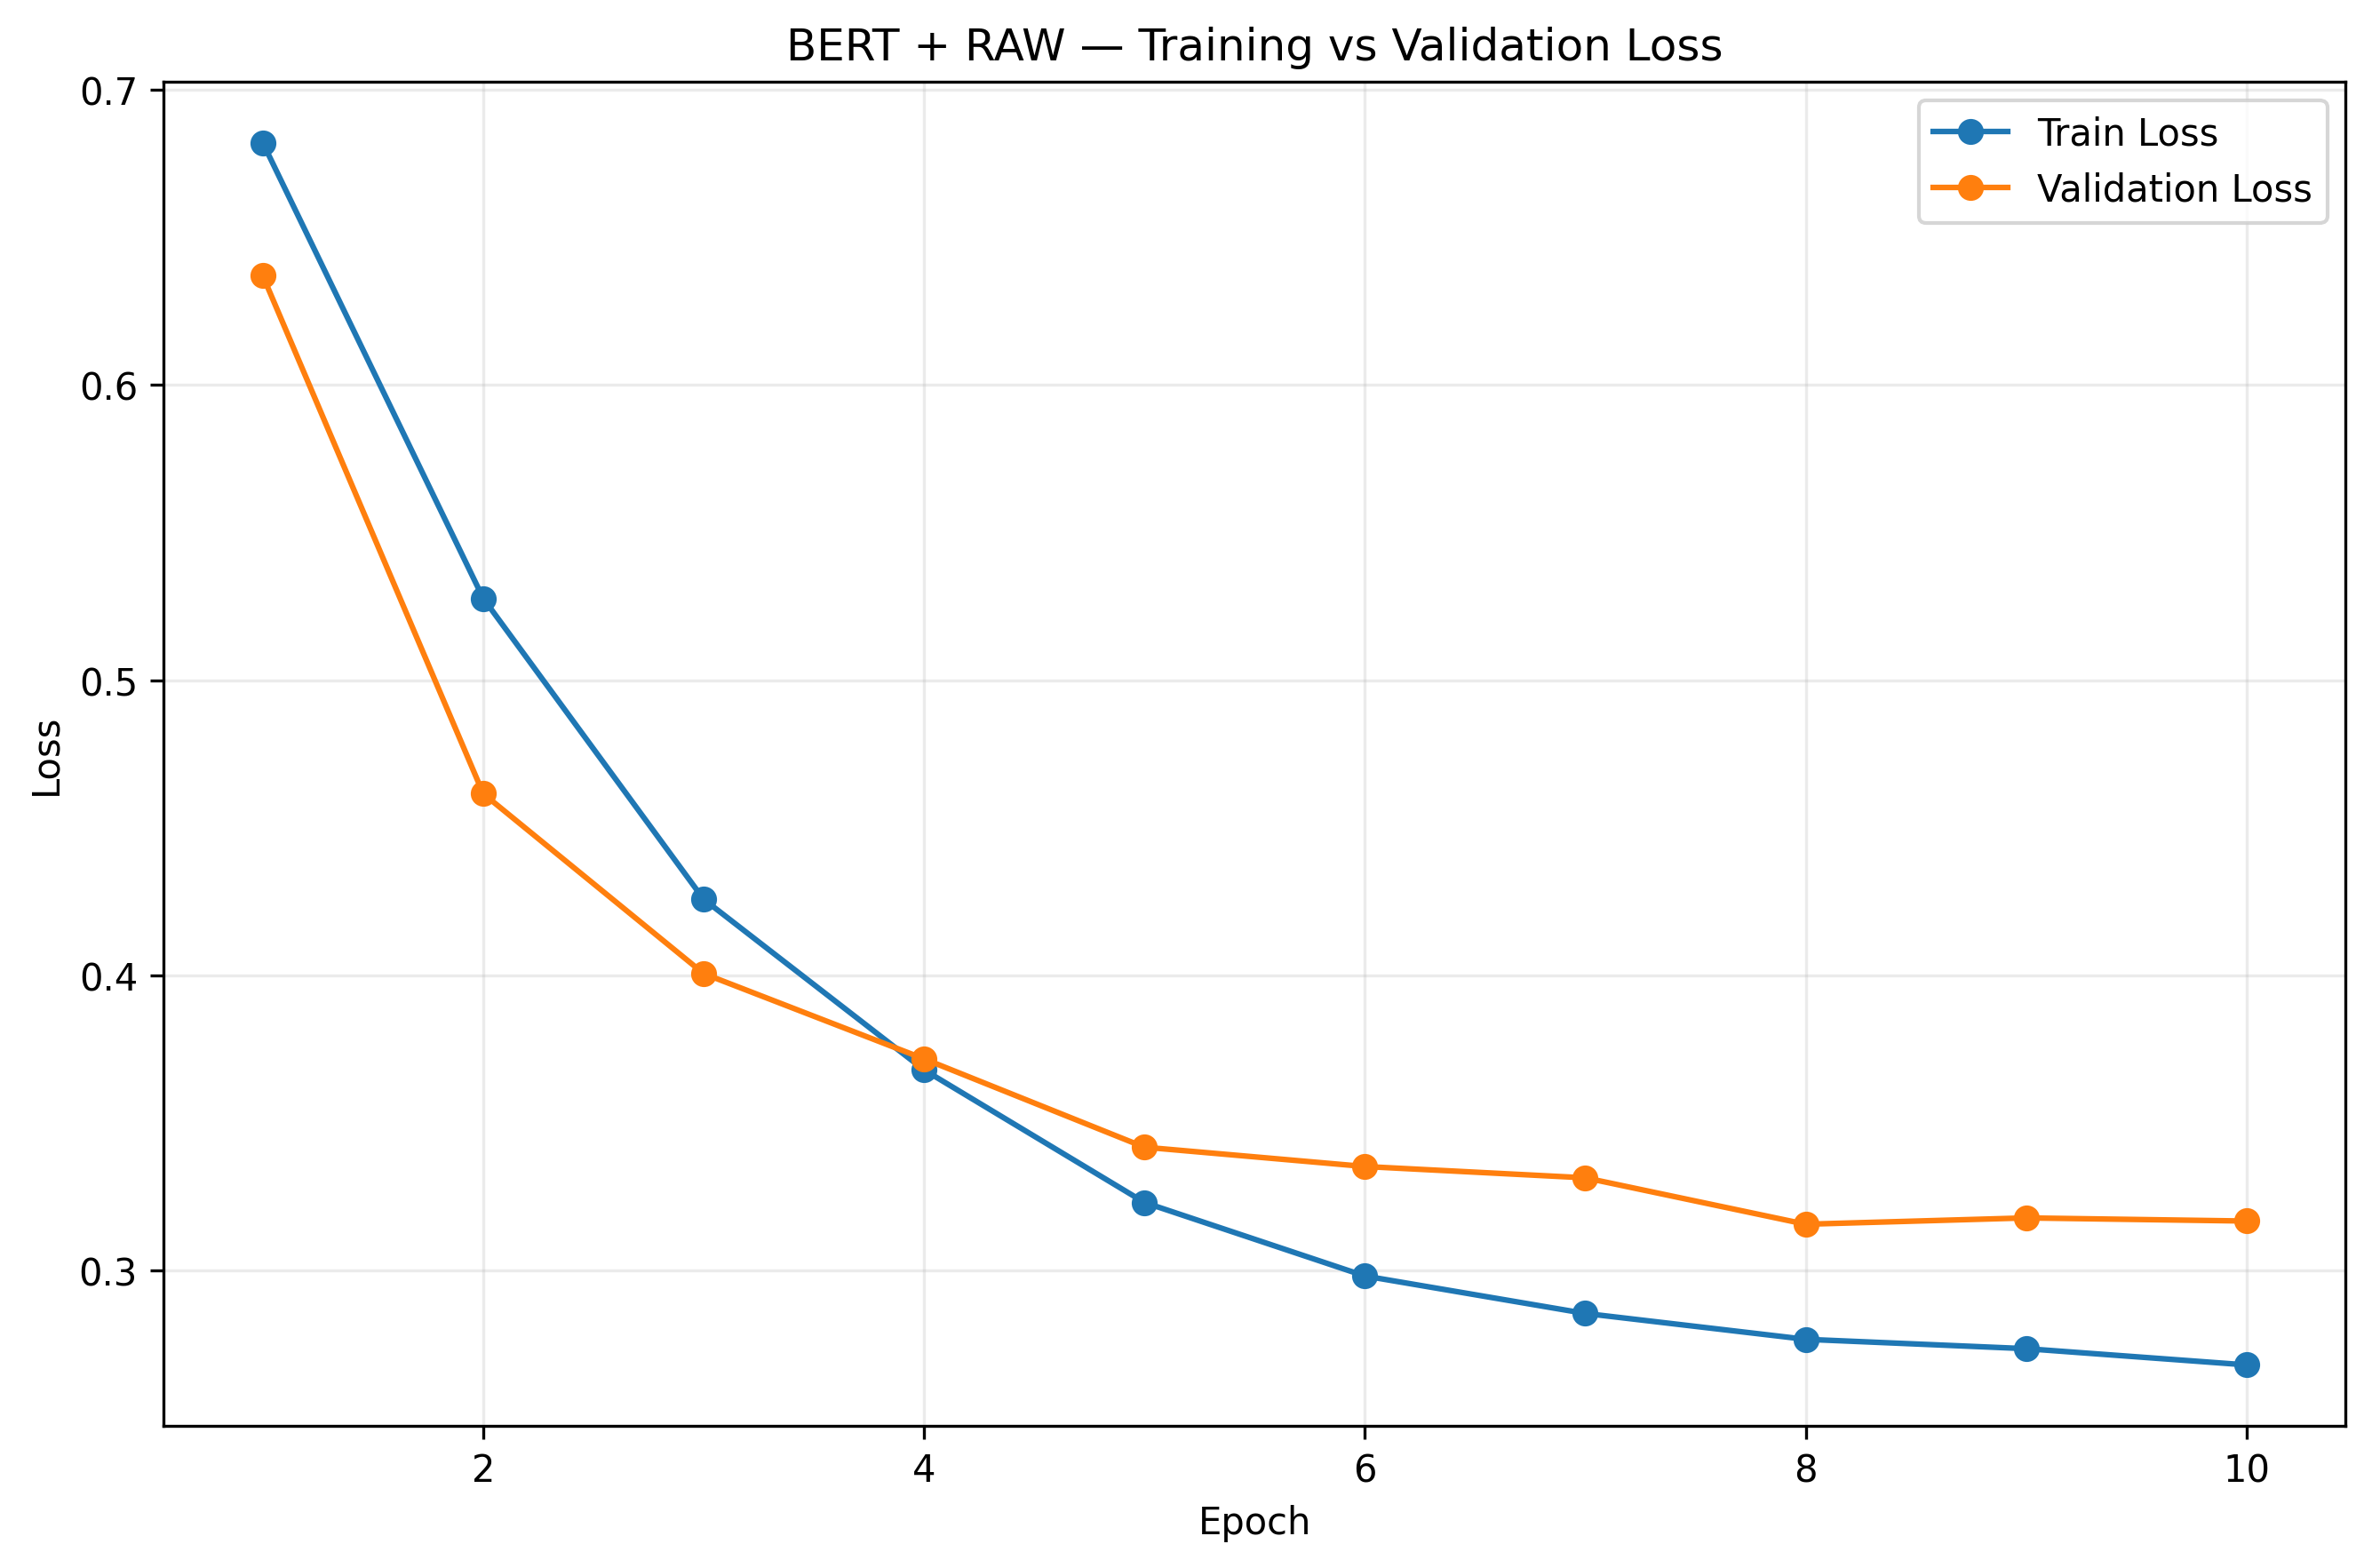


▶ bert_raw_f1_curve.png


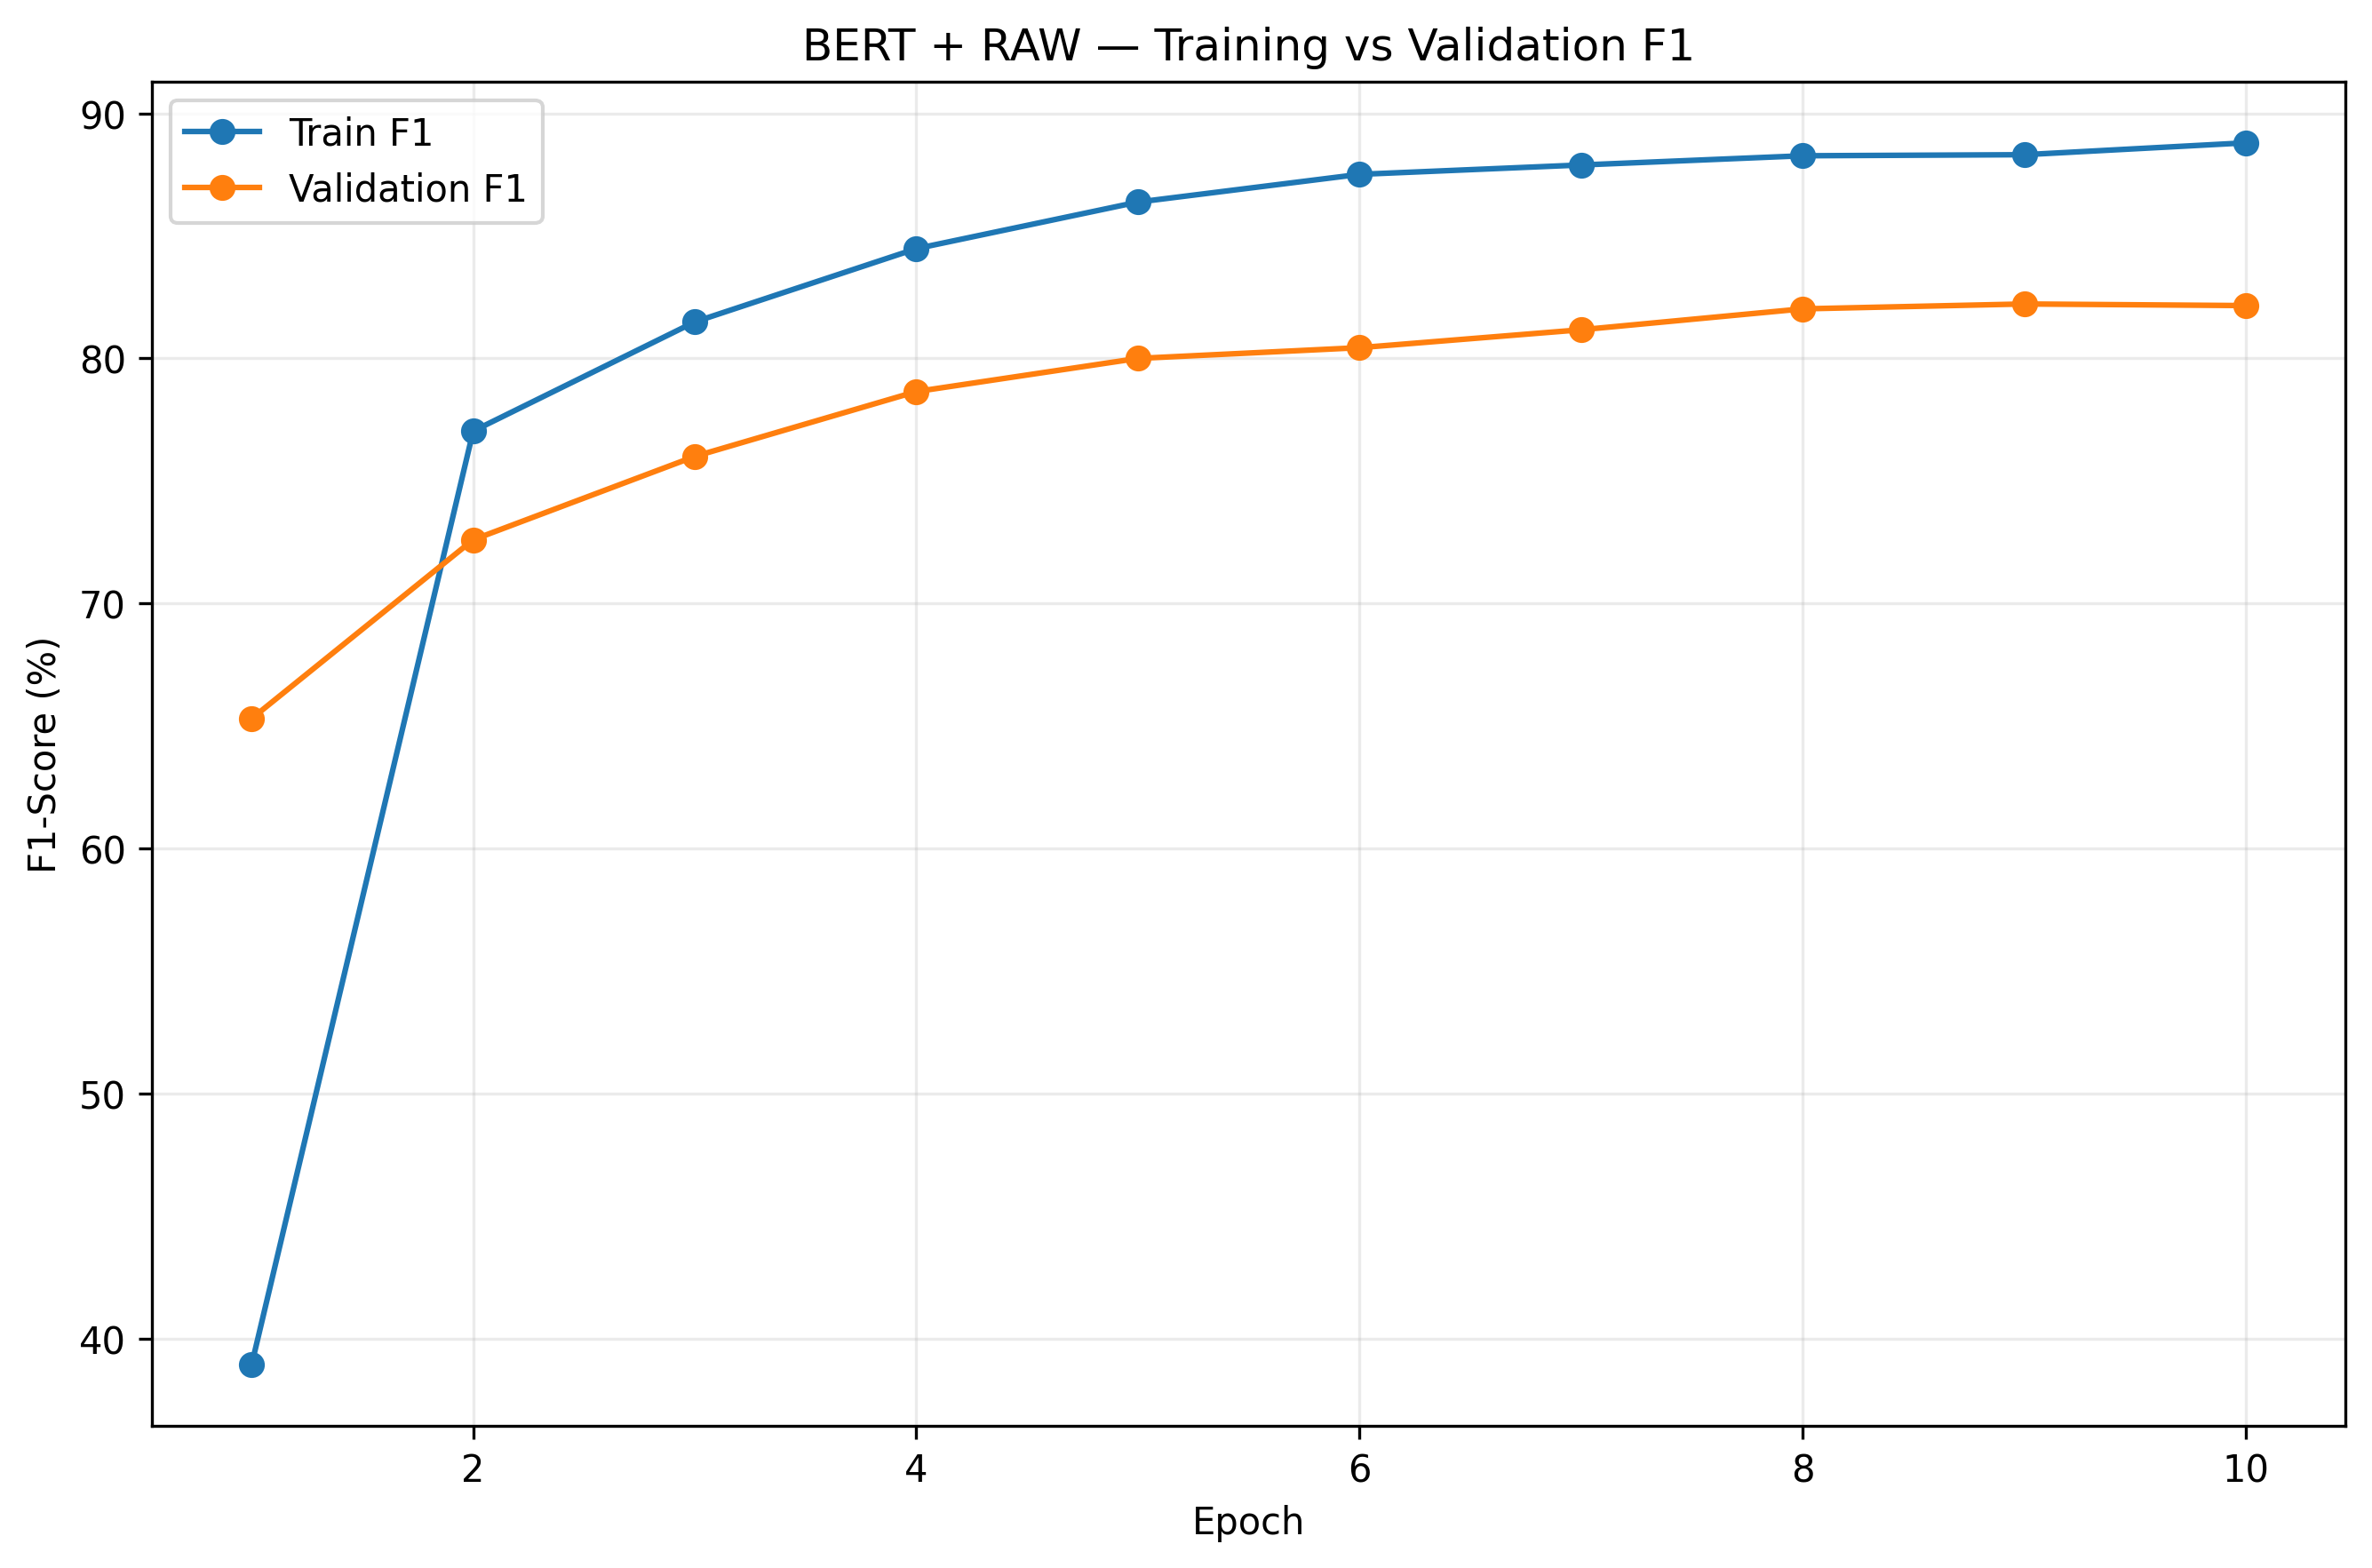


▶ bert_raw_validation_roc_auc.png


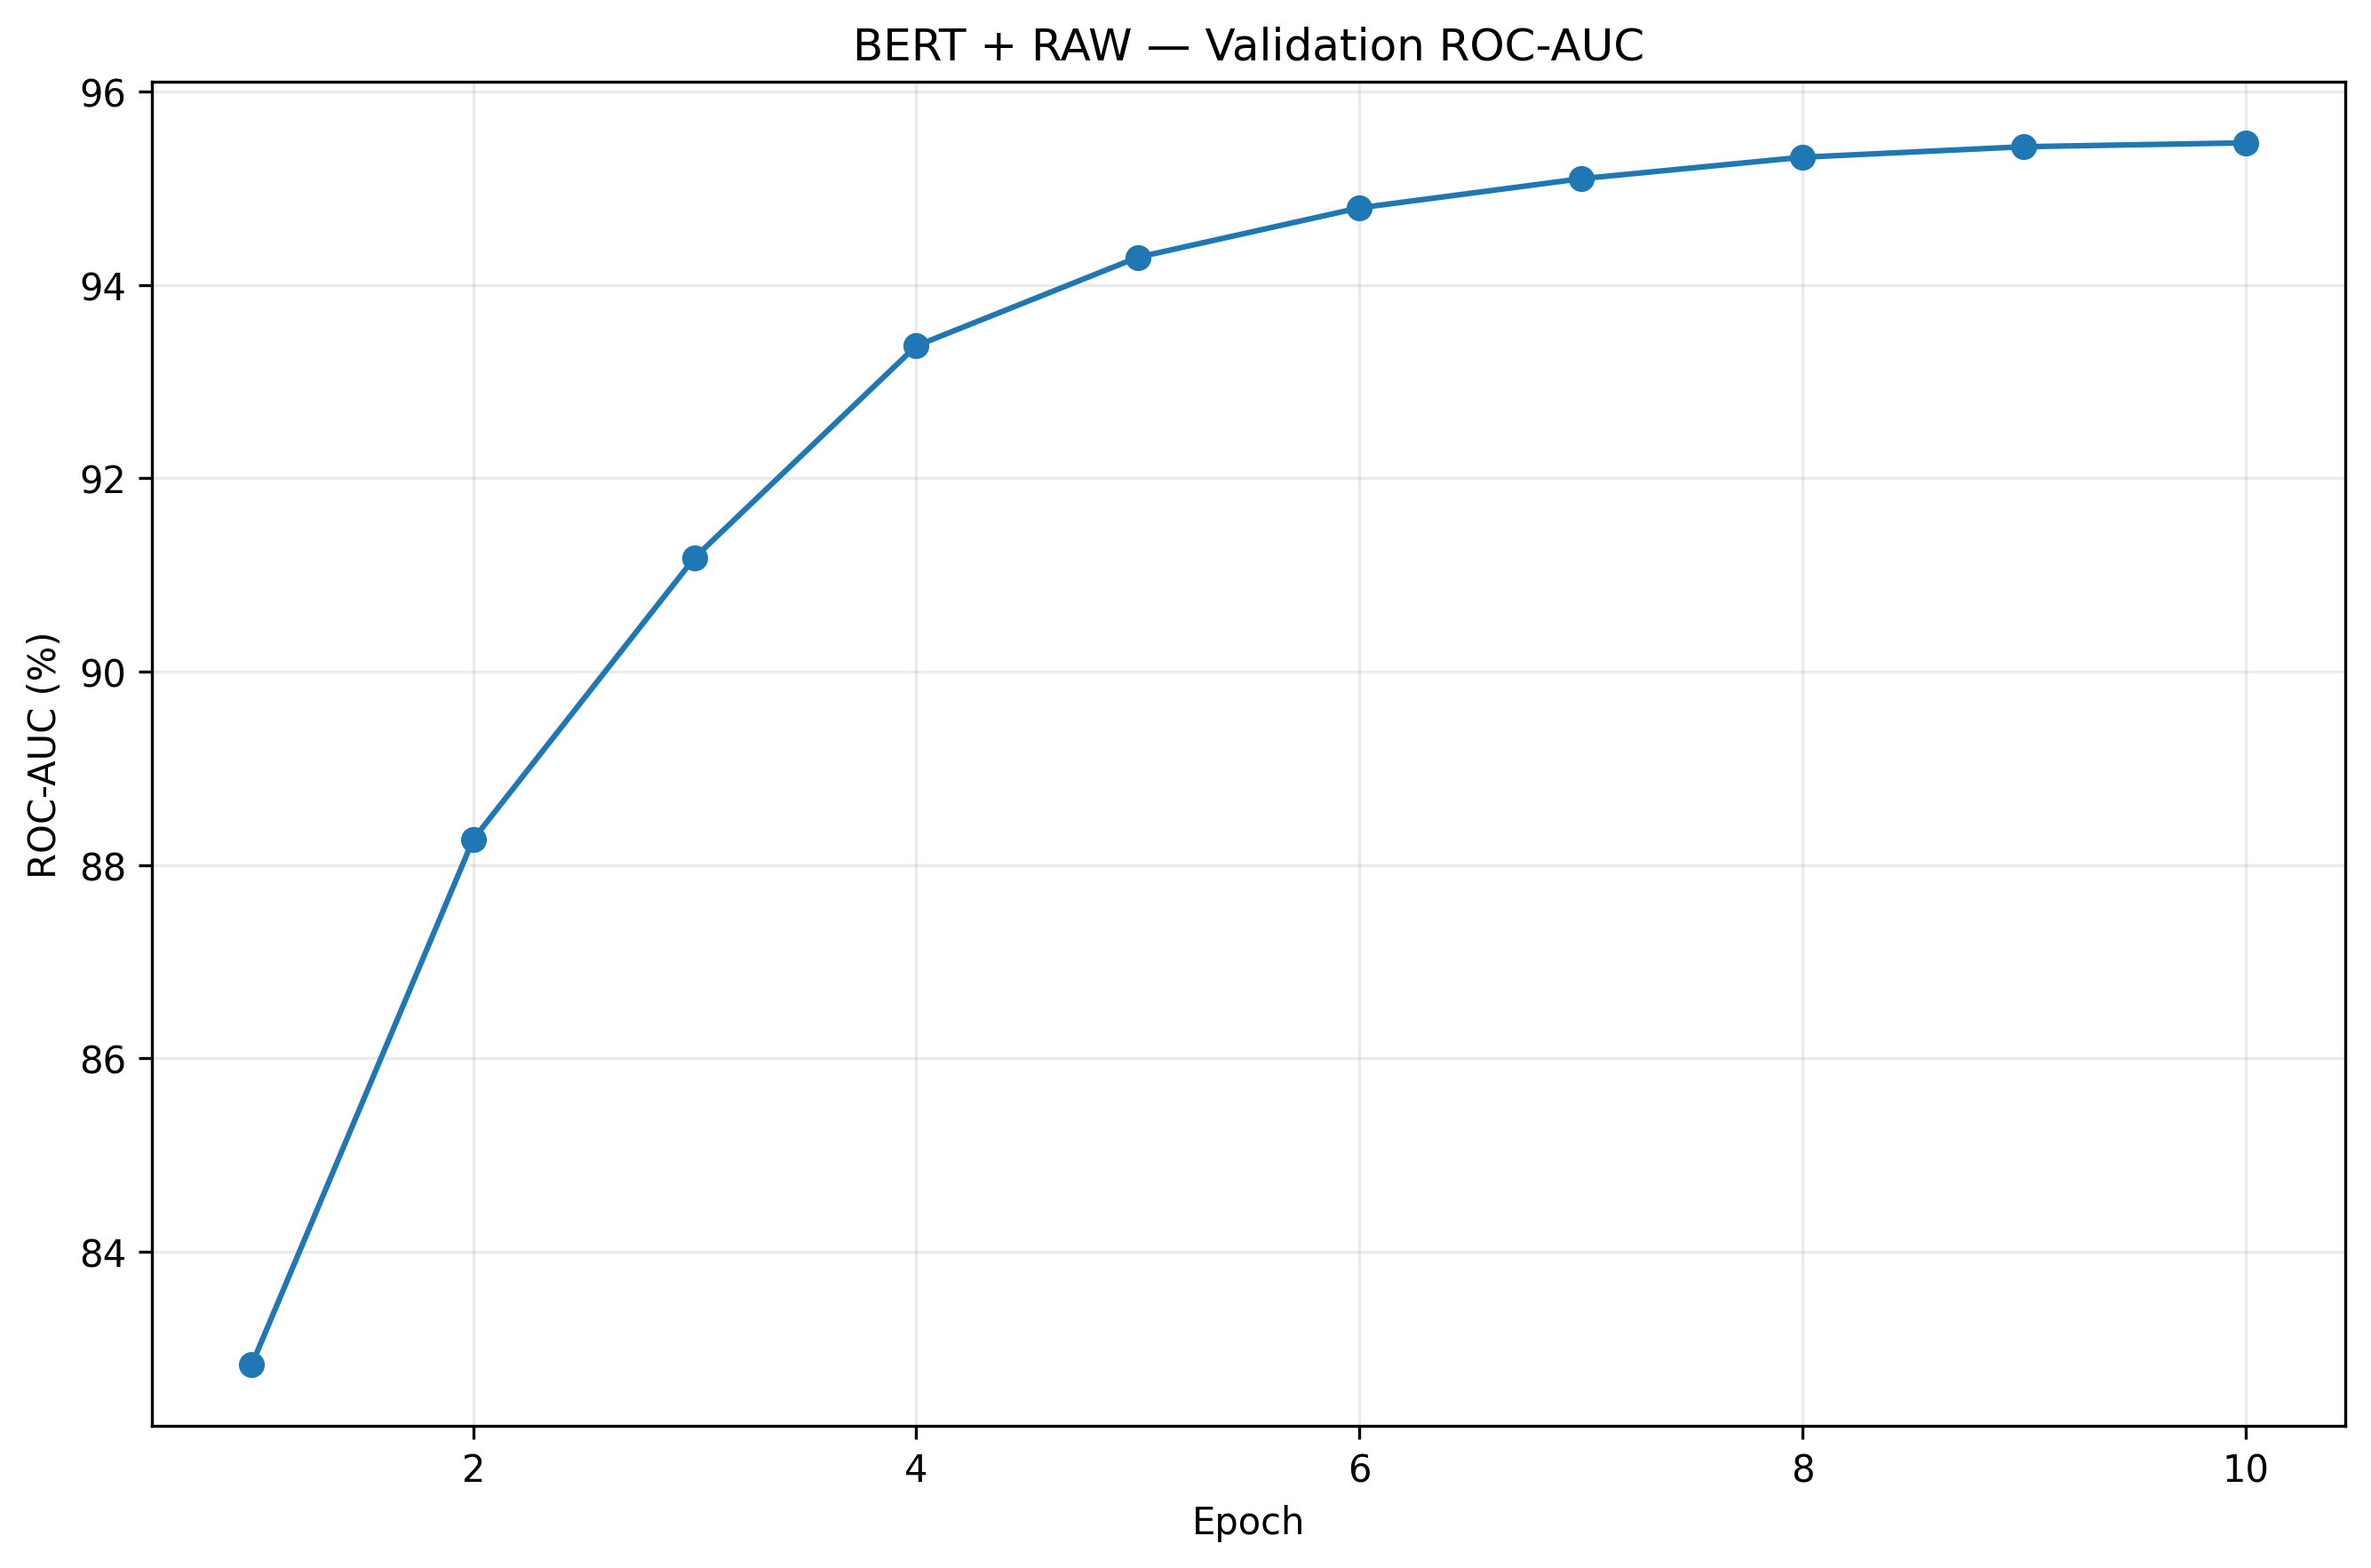


▶ bert_raw_validation_accuracy.png


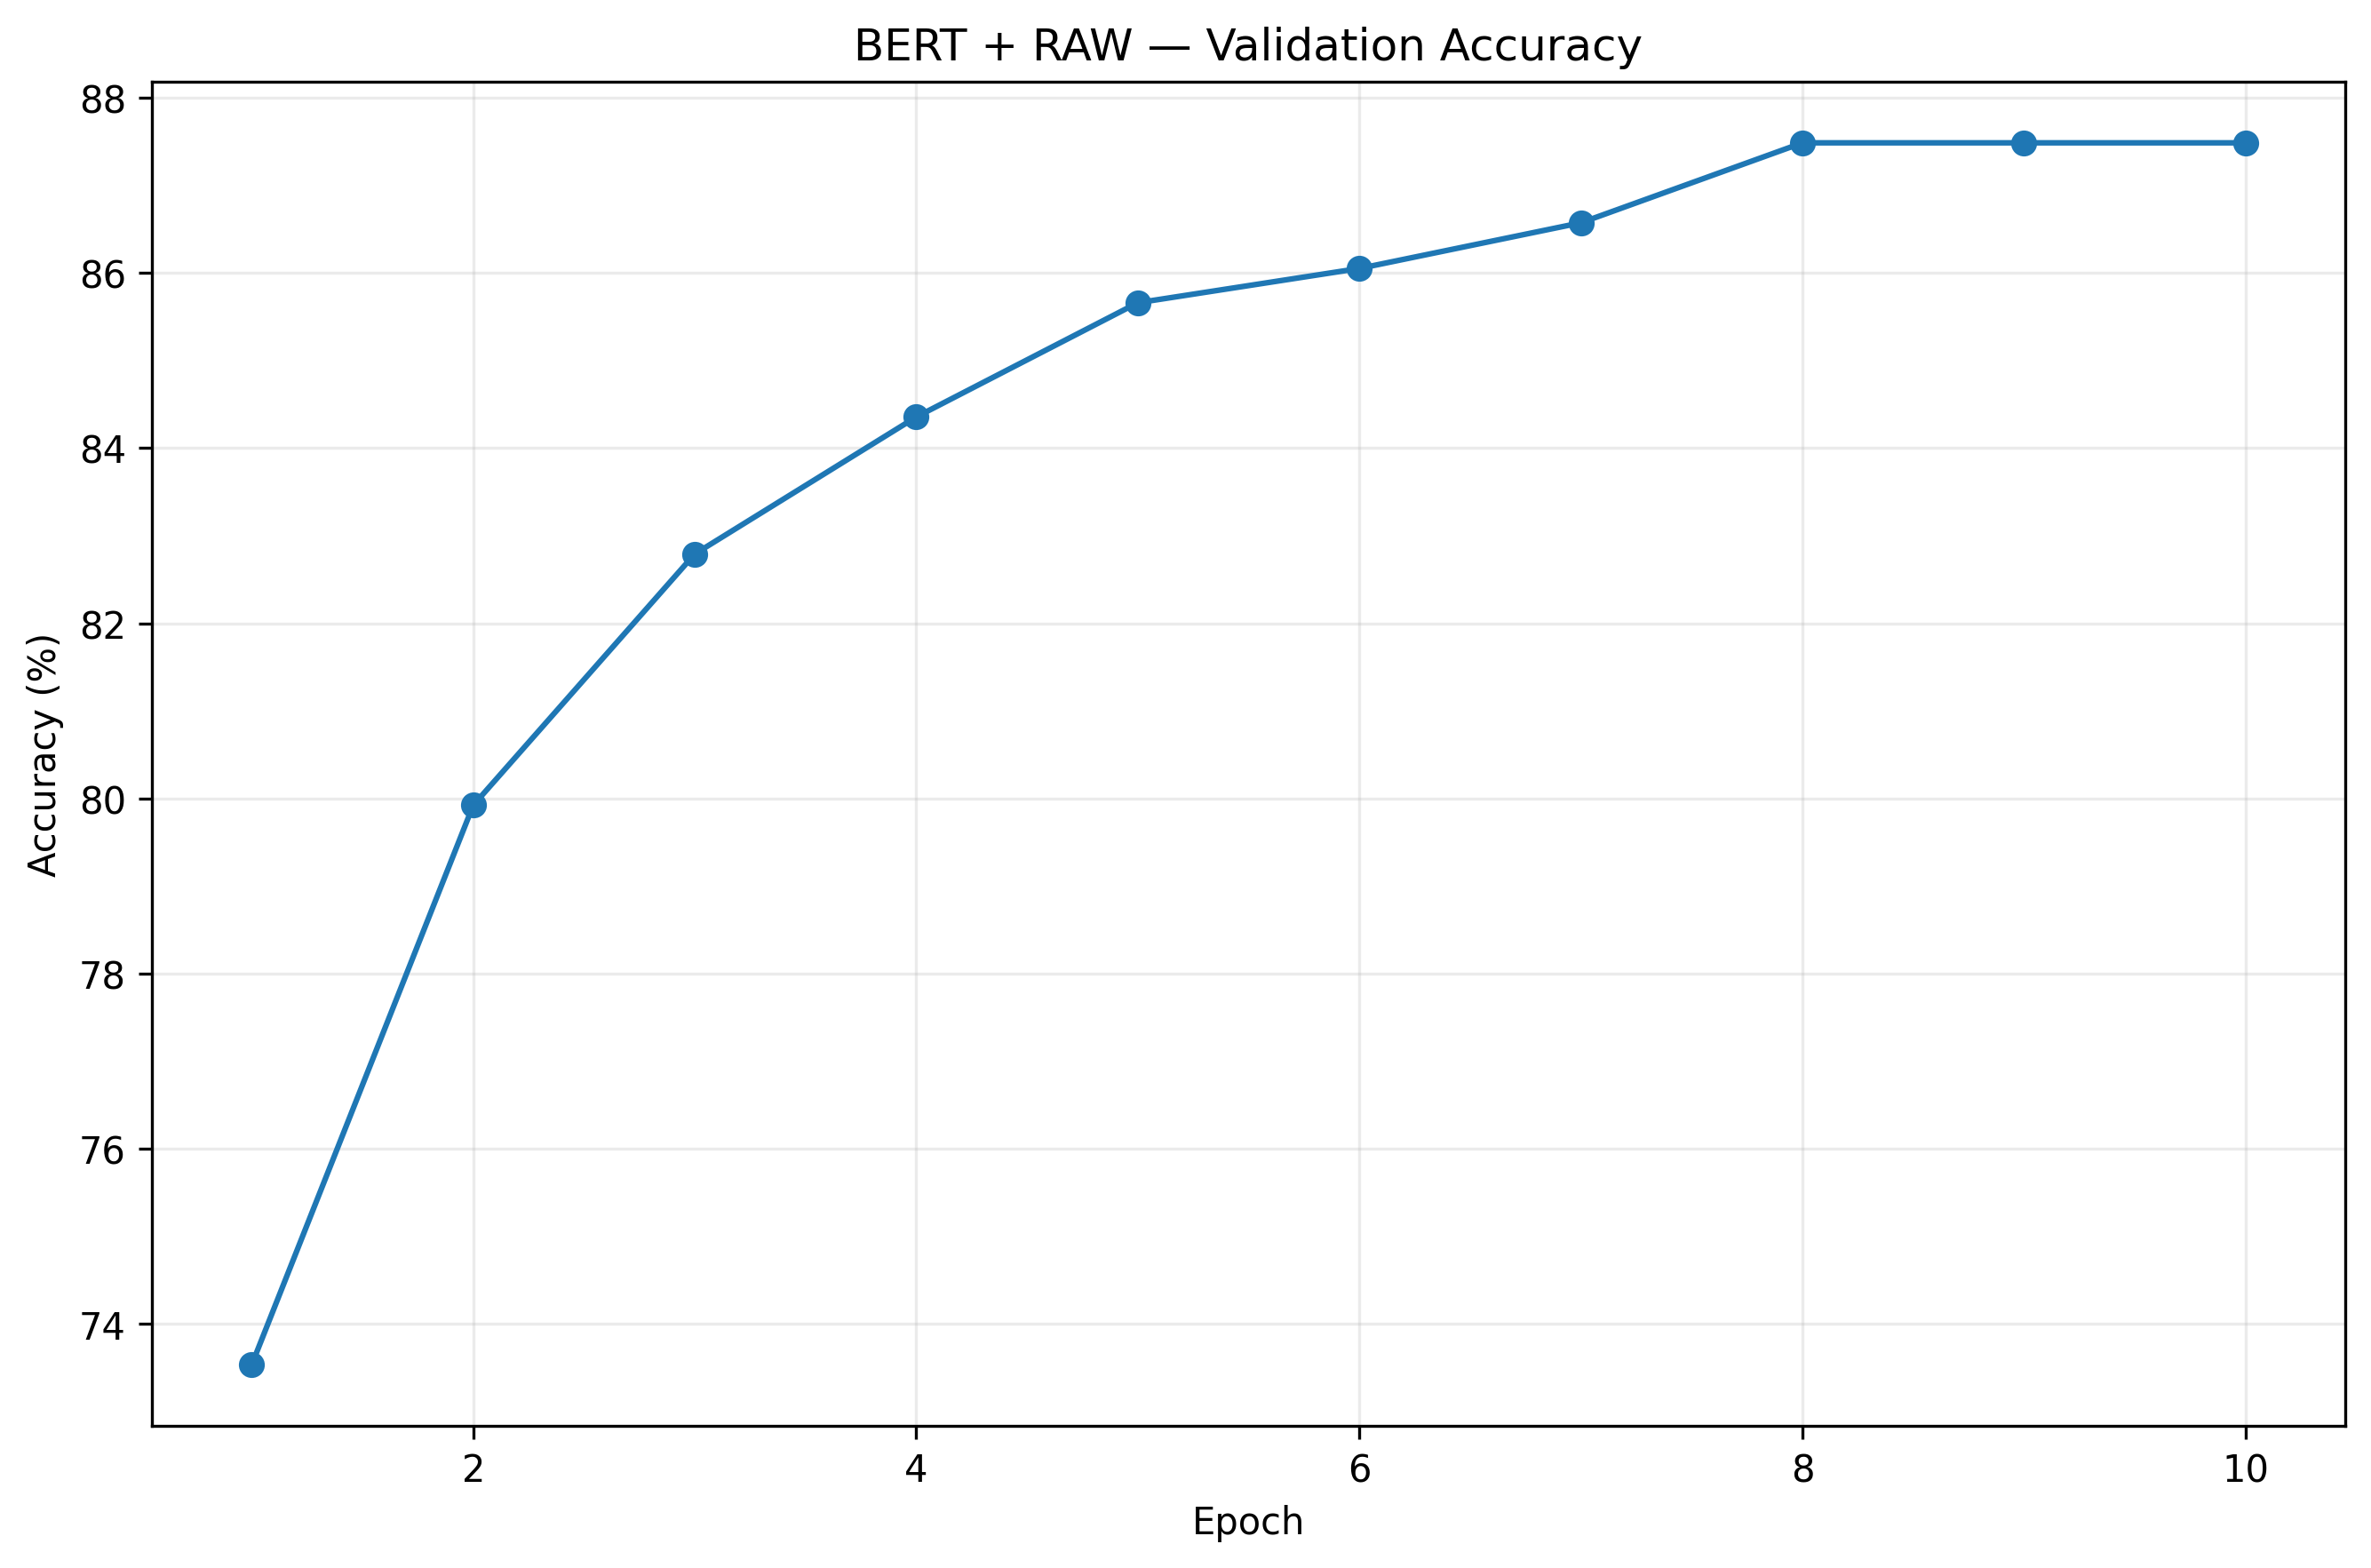


▶ bert_raw_final_metrics.png


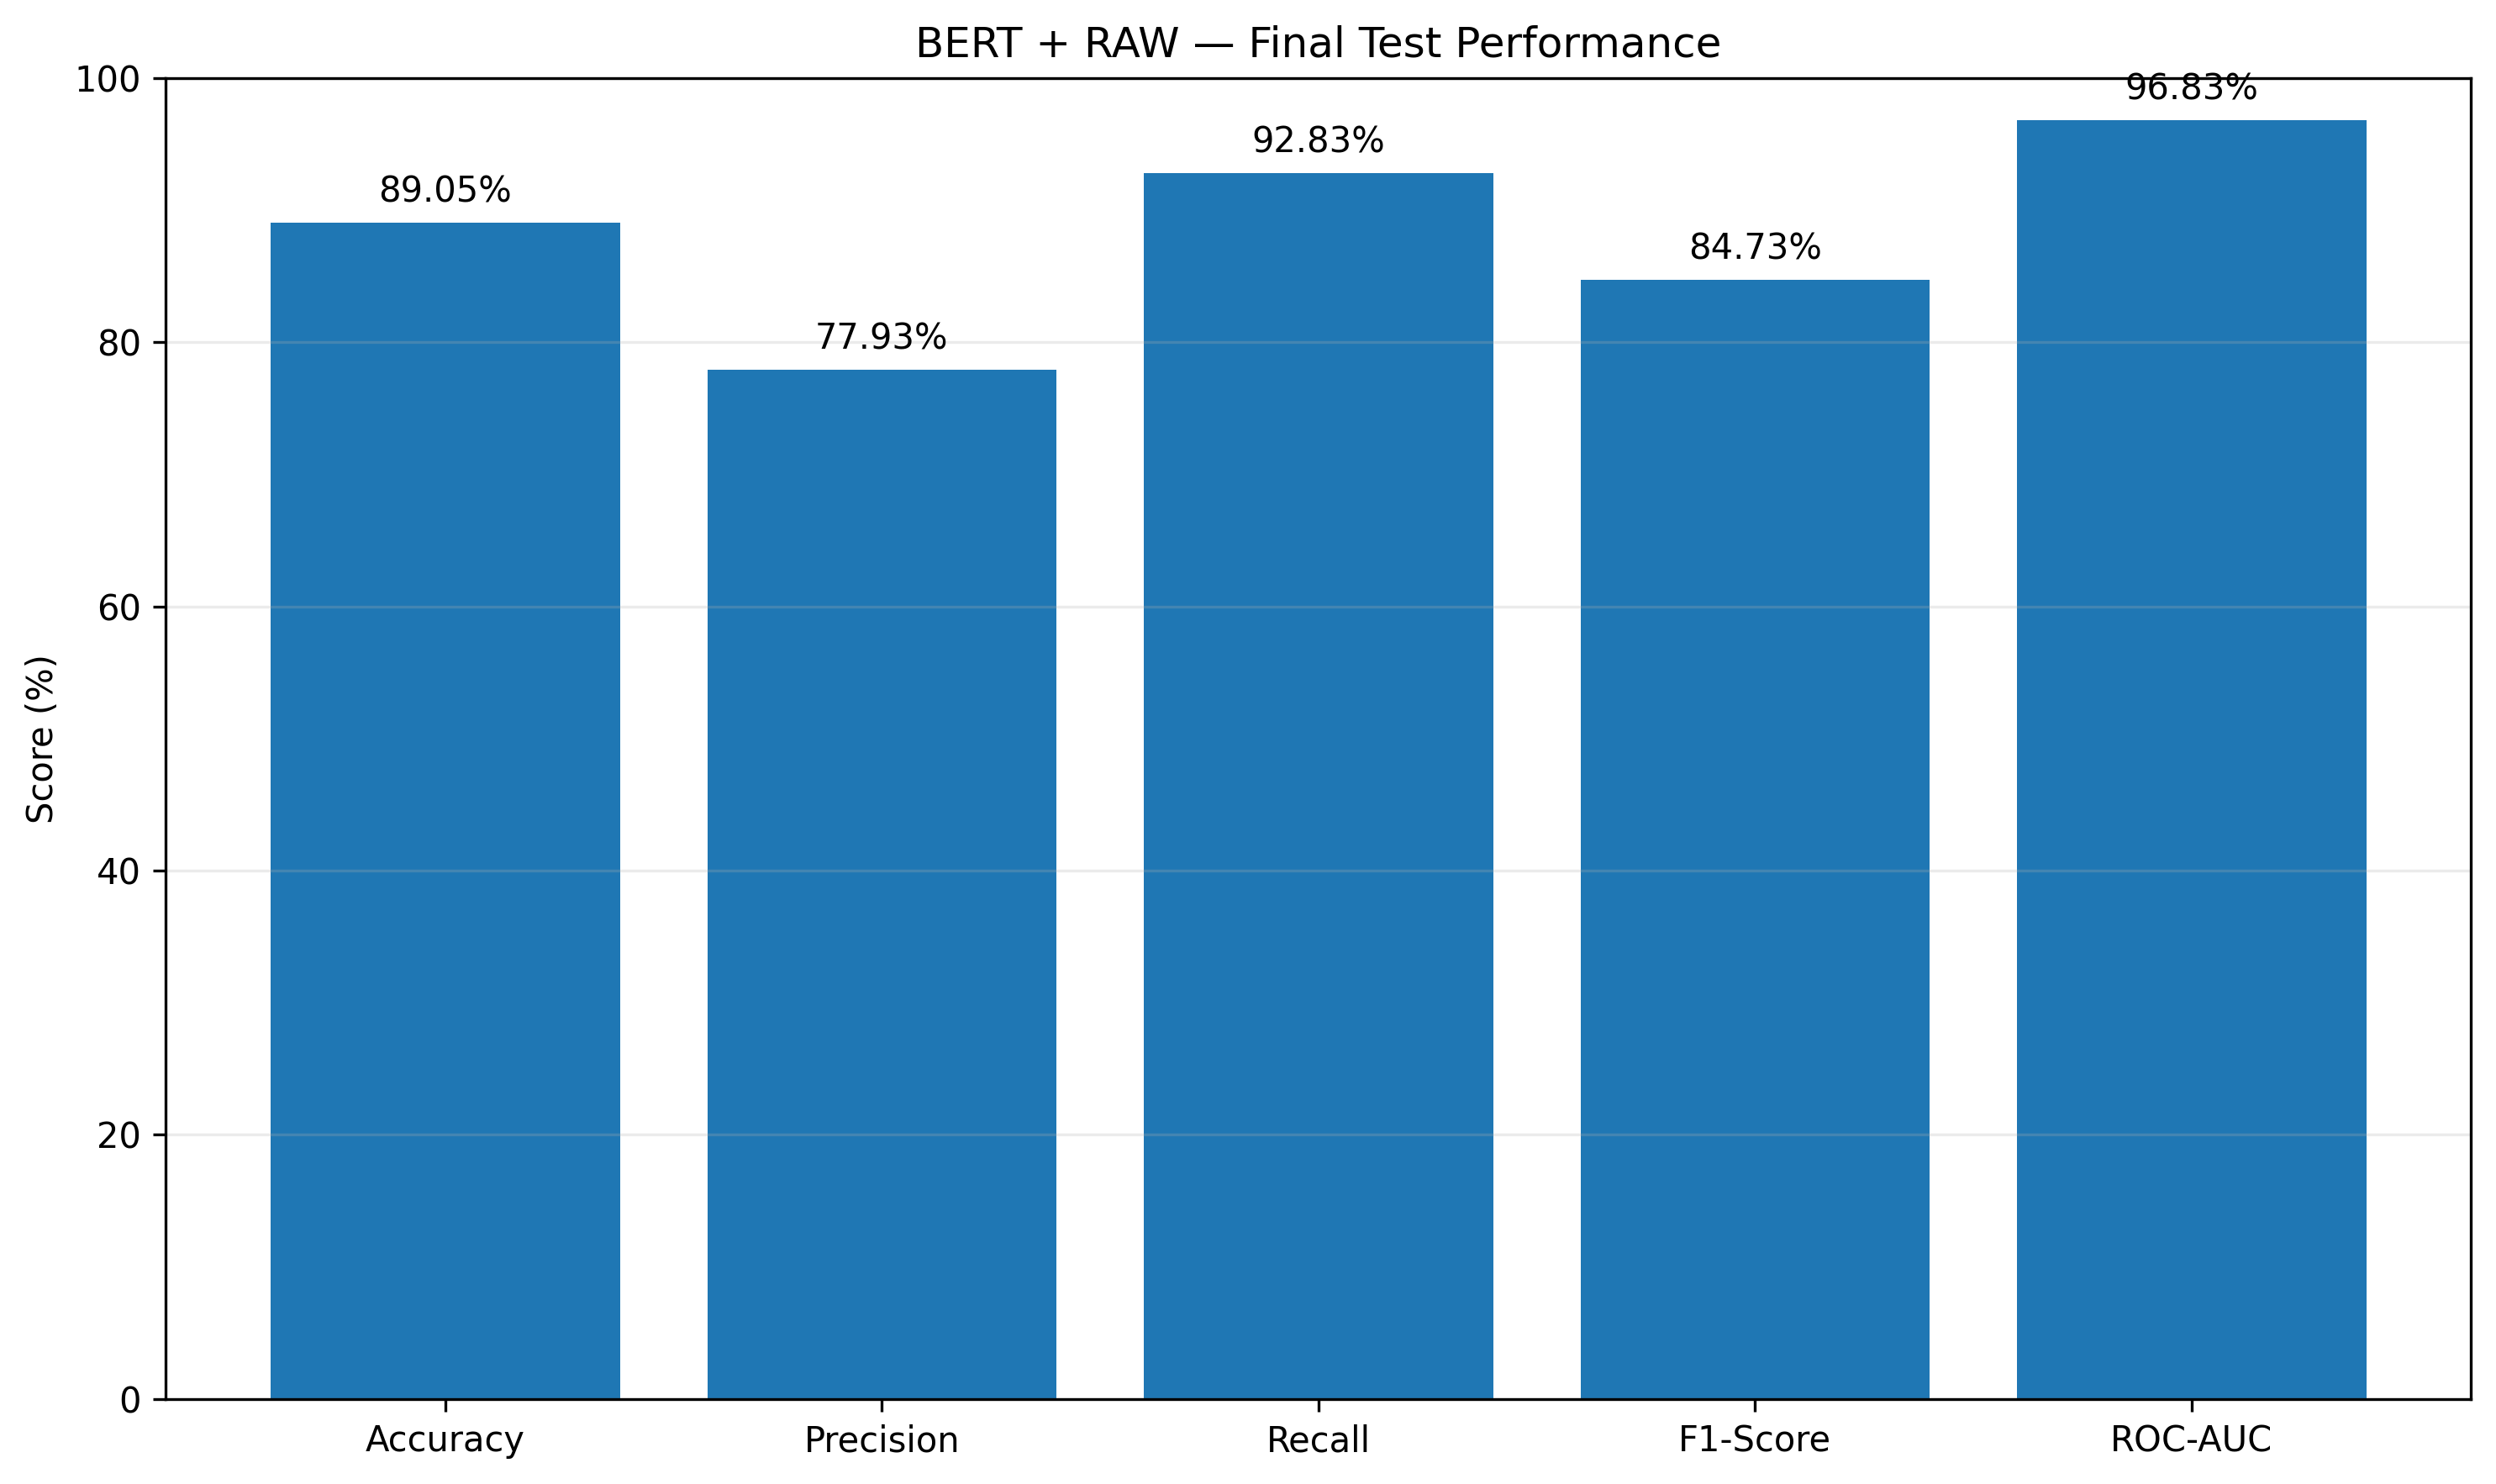


▶ bert_raw_confusion_matrix.png


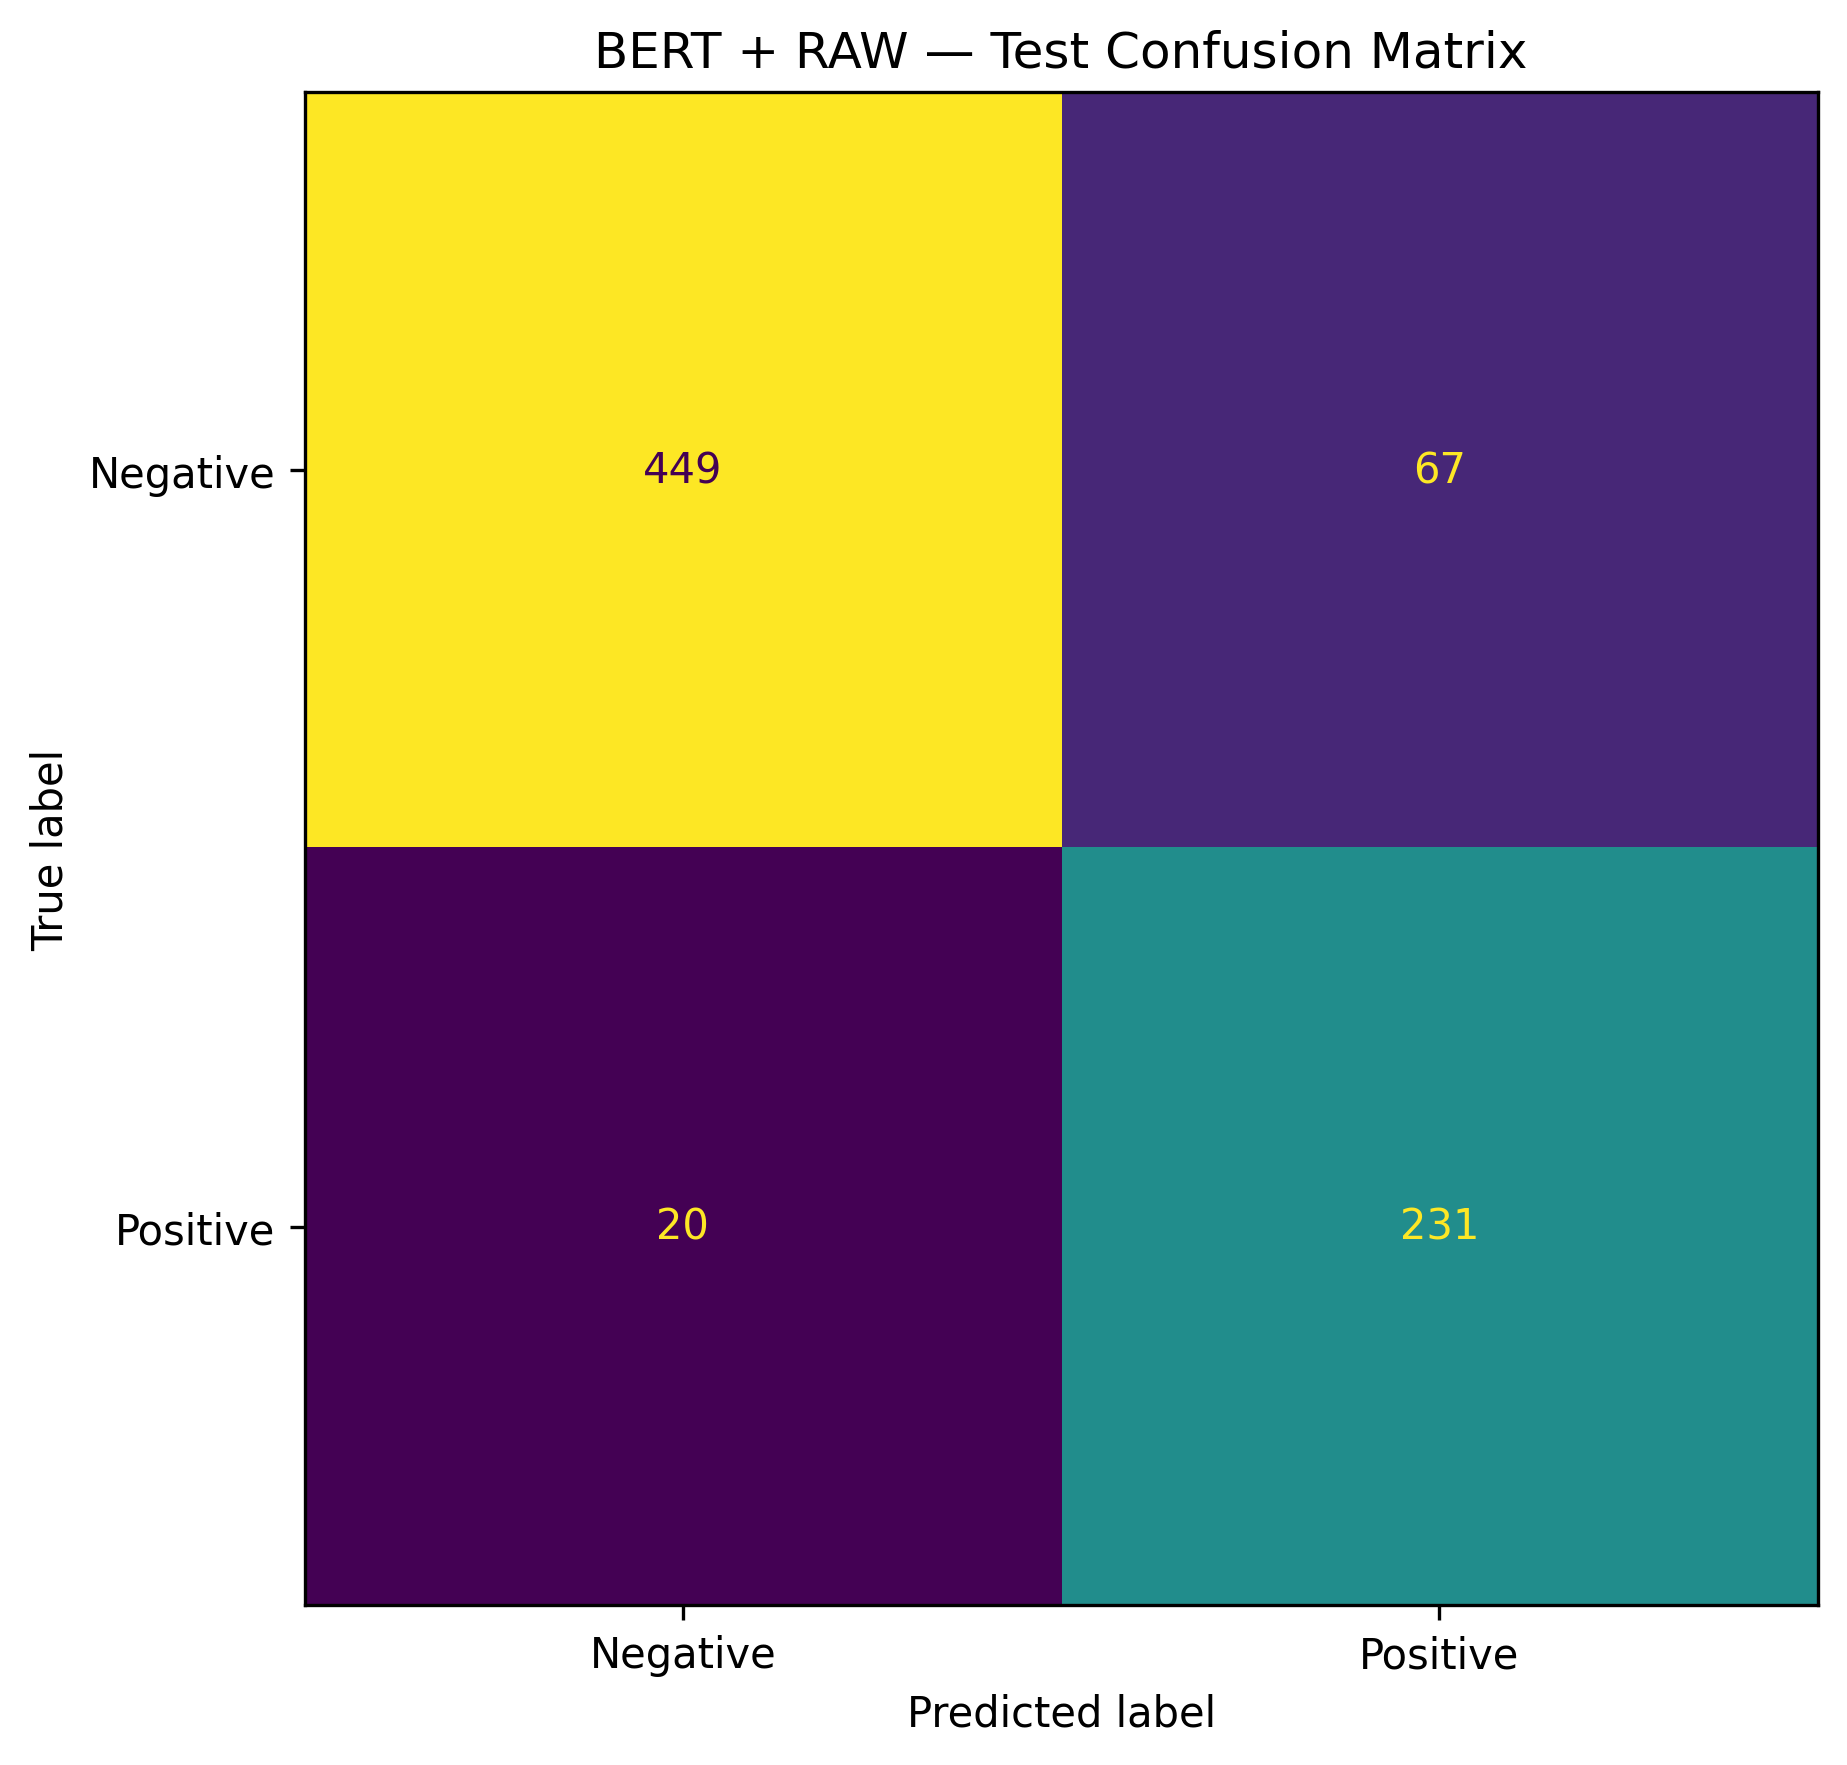

In [15]:
# ============================================================
# CHECK + DISPLAY BERT RAW GRAPHS
# ============================================================

import os
from IPython.display import display, Image

print("=" * 60)
print("BERT + RAW — SAVED GRAPHS CHECK")
print("=" * 60)

expected_graphs = [
    "bert_raw_loss_curve.png",
    "bert_raw_f1_curve.png",
    "bert_raw_validation_roc_auc.png",
    "bert_raw_validation_accuracy.png",
    "bert_raw_final_metrics.png",
    "bert_raw_confusion_matrix.png"
]

print()
print("Graphs folder:")
print(GRAPH_DIR)

print()
print("Checking files...")

found_graphs = []
missing_graphs = []

for filename in expected_graphs:

    filepath = os.path.join(
        GRAPH_DIR,
        filename
    )

    if os.path.exists(filepath):
        found_graphs.append(filename)
        print("✓", filename)
    else:
        missing_graphs.append(filename)
        print("✗", filename)

print()
print("=" * 60)
print("GRAPH SUMMARY")
print("=" * 60)

print(
    f"Created: {len(found_graphs)}/{len(expected_graphs)}"
)

if missing_graphs:
    print(
        "Missing:",
        len(missing_graphs)
    )
else:
    print("✓ ALL 6 GRAPHS CREATED")

# ============================================================
# DISPLAY ALL AVAILABLE GRAPHS
# ============================================================

print()
print("=" * 60)
print("DISPLAYING GRAPHS")
print("=" * 60)

for filename in found_graphs:

    print()
    print("▶", filename)

    display(
        Image(
            filename=os.path.join(
                GRAPH_DIR,
                filename
            )
        )
    )

BERT — PERFORMANCE COMPARISON TABLE

FINAL BERT COMPARISON:


,Model,Cleaning,Accuracy (%),Precision (%),Recall (%),F1 (%),ROC-AUC (%),Best Epoch,Best Val F1 (%)
0,BERT,Raw,89.05%,77.93%,92.83%,84.73%,96.83%,9,82.22%
1,BERT,Aggressive,81.75%,65.81%,92.03%,76.74%,94.04%,9,77.36%
2,BERT,Selective,85.79%,72.61%,90.84%,80.71%,94.88%,9,80.29%
3,BERT,Emotion-Based,89.96%,80.21%,92.03%,85.71%,96.96%,9,82.80%


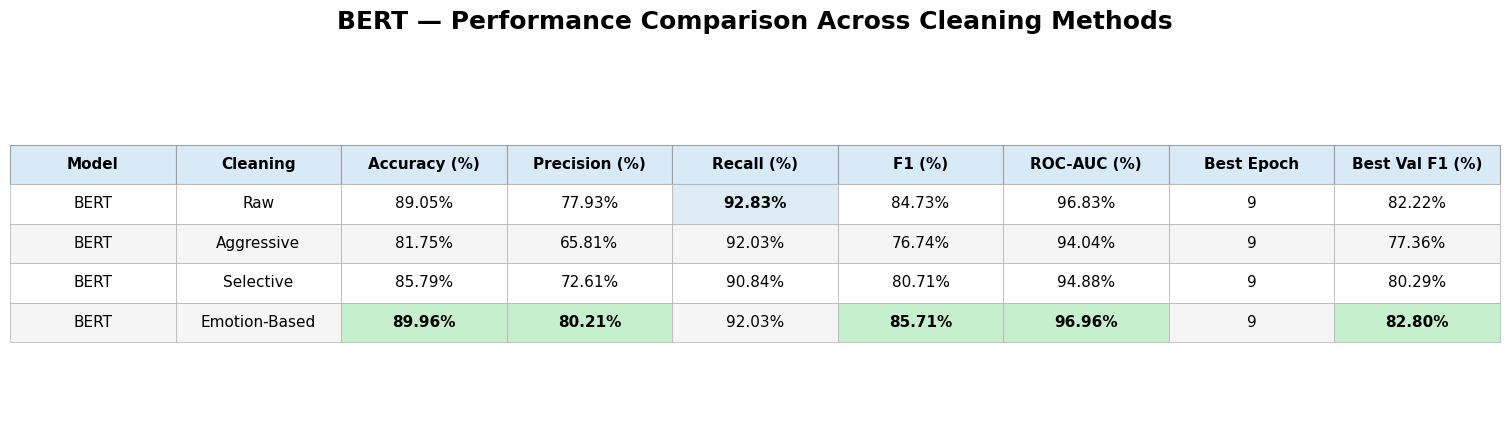

TABLE GENERATION COMPLETE

✓ BERT comparison table displayed

✓ PNG table saved:
/kaggle/working/bert_comparison/bert_cleaning_comparison.png

✓ CSV table saved:
/kaggle/working/bert_comparison/bert_cleaning_comparison.csv

✓ Best overall method:
Emotion-Based

✓ Best Accuracy: 89.96%
✓ Best F1 Score: 85.71%
✓ Best ROC-AUC: 96.96%

✓ COMPLETE


In [16]:
# ============================================================
# BERT — PERFORMANCE COMPARISON ACROSS CLEANING METHODS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.table import Table
import os

print("=" * 60)
print("BERT — PERFORMANCE COMPARISON TABLE")
print("=" * 60)


# ------------------------------------------------------------
# 1. CREATE RESULTS DATA
# ------------------------------------------------------------

comparison_data = {
    "Model": [
        "BERT",
        "BERT",
        "BERT",
        "BERT"
    ],

    "Cleaning": [
        "Raw",
        "Aggressive",
        "Selective",
        "Emotion-Based"
    ],

    "Accuracy (%)": [
        "89.05%",
        "81.75%",
        "85.79%",
        "89.96%"
    ],

    "Precision (%)": [
        "77.93%",
        "65.81%",
        "72.61%",
        "80.21%"
    ],

    "Recall (%)": [
        "92.83%",
        "92.03%",
        "90.84%",
        "92.03%"
    ],

    "F1 (%)": [
        "84.73%",
        "76.74%",
        "80.71%",
        "85.71%"
    ],

    "ROC-AUC (%)": [
        "96.83%",
        "94.04%",
        "94.88%",
        "96.96%"
    ],

    "Best Epoch": [
        9,
        9,
        9,
        9
    ],

    "Best Val F1 (%)": [
        "82.22%",
        "77.36%",
        "80.29%",
        "82.80%"
    ]
}


# ------------------------------------------------------------
# 2. CREATE DATAFRAME
# ------------------------------------------------------------

bert_comparison_df = pd.DataFrame(comparison_data)

print("\nFINAL BERT COMPARISON:")
display(bert_comparison_df)


# ------------------------------------------------------------
# 3. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/bert_comparison"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

table_path = os.path.join(
    OUTPUT_DIR,
    "bert_cleaning_comparison.png"
)


# ------------------------------------------------------------
# 4. CREATE PROFESSIONAL TABLE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 4.5)
)

ax.axis("off")


# ------------------------------------------------------------
# 5. ADD TITLE
# ------------------------------------------------------------

plt.title(
    "BERT — Performance Comparison Across Cleaning Methods",
    fontsize=18,
    fontweight="bold",
    pad=20
)


# ------------------------------------------------------------
# 6. CREATE TABLE
# ------------------------------------------------------------

table = ax.table(
    cellText=bert_comparison_df.values,
    colLabels=bert_comparison_df.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)


# ------------------------------------------------------------
# 7. STYLE TABLE
# ------------------------------------------------------------

table.auto_set_font_size(False)
table.set_fontsize(11)

table.scale(
    1.15,
    2.2
)


# ------------------------------------------------------------
# 8. STYLE HEADER
# ------------------------------------------------------------

for column in range(
    len(bert_comparison_df.columns)
):

    cell = table[
        (0, column)
    ]

    cell.set_facecolor(
        "#D9EAF7"
    )

    cell.set_text_props(
        weight="bold"
    )

    cell.set_edgecolor(
        "#A0A0A0"
    )

    cell.set_linewidth(
        0.8
    )


# ------------------------------------------------------------
# 9. STYLE DATA ROWS
# ------------------------------------------------------------

for row in range(
    1,
    len(bert_comparison_df) + 1
):

    for column in range(
        len(bert_comparison_df.columns)
    ):

        cell = table[
            (row, column)
        ]

        # Alternate row colors
        if row % 2 == 0:

            cell.set_facecolor(
                "#F5F5F5"
            )

        else:

            cell.set_facecolor(
                "#FFFFFF"
            )


        cell.set_edgecolor(
            "#B0B0B0"
        )

        cell.set_linewidth(
            0.5
        )


# ------------------------------------------------------------
# 10. HIGHLIGHT BEST VALUES
# ------------------------------------------------------------

# Emotion-Based row = row 4
emotion_row = 4


# Best Accuracy
table[
    (emotion_row, 2)
].set_facecolor("#C6EFCE")

table[
    (emotion_row, 2)
].set_text_props(weight="bold")


# Best Precision
table[
    (emotion_row, 3)
].set_facecolor("#C6EFCE")

table[
    (emotion_row, 3)
].set_text_props(weight="bold")


# Best F1
table[
    (emotion_row, 5)
].set_facecolor("#C6EFCE")

table[
    (emotion_row, 5)
].set_text_props(weight="bold")


# Best ROC-AUC
table[
    (emotion_row, 6)
].set_facecolor("#C6EFCE")

table[
    (emotion_row, 6)
].set_text_props(weight="bold")


# Best Validation F1
table[
    (emotion_row, 8)
].set_facecolor("#C6EFCE")

table[
    (emotion_row, 8)
].set_text_props(weight="bold")


# Best Recall belongs to RAW
raw_row = 1

table[
    (raw_row, 4)
].set_facecolor("#DDEBF7")

table[
    (raw_row, 4)
].set_text_props(weight="bold")


# ------------------------------------------------------------
# 11. ADJUST LAYOUT
# ------------------------------------------------------------

plt.tight_layout()


# ------------------------------------------------------------
# 12. SAVE HIGH QUALITY TABLE
# ------------------------------------------------------------

plt.savefig(
    table_path,
    dpi=300,
    bbox_inches="tight"
)


# ------------------------------------------------------------
# 13. DISPLAY TABLE
# ------------------------------------------------------------

plt.show()


# ------------------------------------------------------------
# 14. SAVE CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    OUTPUT_DIR,
    "bert_cleaning_comparison.csv"
)

bert_comparison_df.to_csv(
    csv_path,
    index=False
)


# ------------------------------------------------------------
# 15. FINAL OUTPUT
# ------------------------------------------------------------

print("=" * 60)
print("TABLE GENERATION COMPLETE")
print("=" * 60)

print("\n✓ BERT comparison table displayed")

print("\n✓ PNG table saved:")
print(table_path)

print("\n✓ CSV table saved:")
print(csv_path)

print("\n✓ Best overall method:")
print("Emotion-Based")

print("\n✓ Best Accuracy: 89.96%")
print("✓ Best F1 Score: 85.71%")
print("✓ Best ROC-AUC: 96.96%")

print("\n✓ COMPLETE")

t-SNE REPRESENTATION ANALYSIS
BERT + RAW

Extracting fused model representations...
Processed 1/767
Processed 100/767
Processed 200/767
Processed 300/767
Processed 400/767
Processed 500/767
Processed 600/767
Processed 700/767
Processed 767/767

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 89.12%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


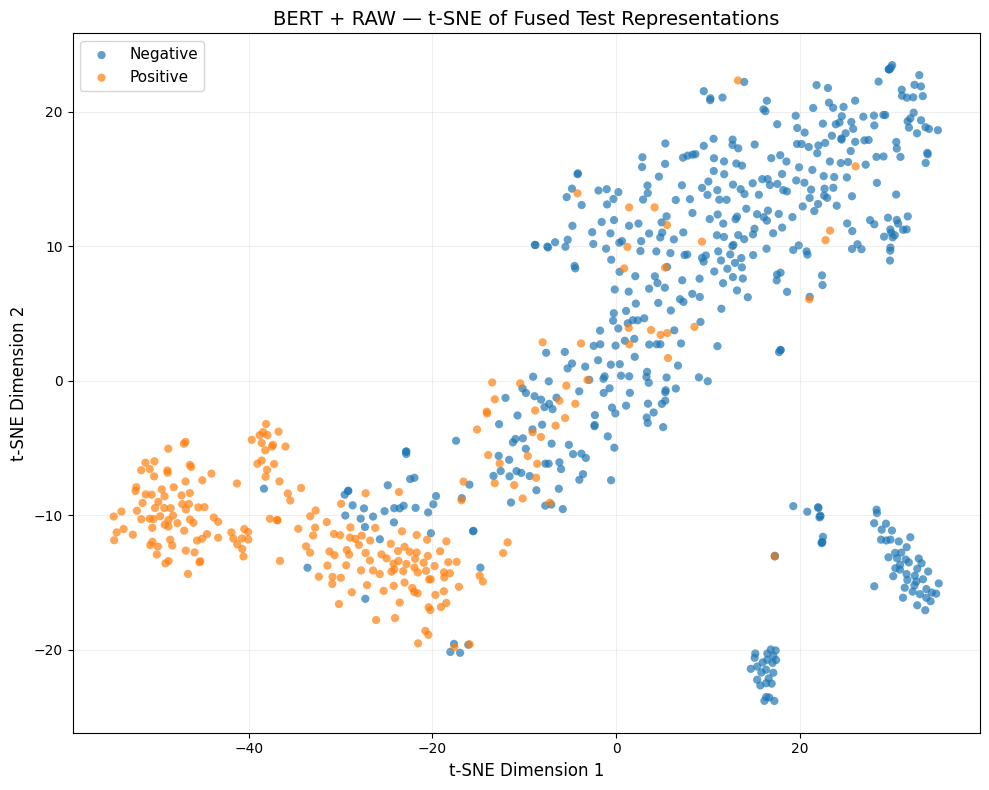


t-SNE ANALYSIS COMPLETE
✓ BERT fused representation extracted
✓ Text representation = 768
✓ Metadata representation = 64
✓ Learned metadata gate used
✓ Fusion = 832 dimensions
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/bert_raw/explainability/tsne/bert_raw_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/bert_raw/explainability/tsne/bert_raw_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [17]:
# ============================================================
# EXPLAINABILITY — CELL 1
# BERT + RAW
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("BERT + RAW")
print("=" * 70)


# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000


np.random.seed(
    EXPLAINABILITY_SEED
)


torch.manual_seed(
    EXPLAINABILITY_SEED
)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)


TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)


os.makedirs(
    TSNE_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()


# ============================================================
# EXTRACT EXACT FUSED REPRESENTATIONS
#
# BERT + RAW:
# text representation = 768
# metadata representation = 64
# metadata gate = learned
# gated metadata = gate * metadata representation
# fused = 832
# ============================================================

fused_representations = []
test_labels = []


print()
print("Extracting fused model representations...")


# ============================================================
# MEMORY-SAFE EXTRACTION
# ONE TEST USER AT A TIME
# ============================================================

num_test_samples = len(
    test_dataset
)


for test_index in range(
    num_test_samples
):

    sample = test_dataset[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    labels = sample[
        "labels"
    ].to(device)


    # --------------------------------------------------------
    # FORWARD PASS
    # --------------------------------------------------------

    with torch.inference_mode():

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        # ----------------------------------------------------
        # EXACT TEXT REPRESENTATION
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]


        # ----------------------------------------------------
        # EXACT METADATA REPRESENTATION
        # ----------------------------------------------------

        metadata_representation = output[
            "metadata_representation"
        ]


        # ----------------------------------------------------
        # EXACT METADATA GATE
        # ----------------------------------------------------

        metadata_gate = output[
            "metadata_gate"
        ]


        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )


        # ----------------------------------------------------
        # EXACT BERT + RAW FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )


        fused_representations.append(
            fused
            .cpu()
            .numpy()
        )


        test_labels.append(
            int(
                labels.item()
            )
        )


    # --------------------------------------------------------
    # DELETE GPU TENSORS
    # --------------------------------------------------------

    del (
        input_ids,
        attention_mask,
        metadata,
        labels,
        output,
        text_representation,
        metadata_representation,
        metadata_gate,
        gated_metadata,
        fused
    )


    # --------------------------------------------------------
    # PERIODIC MEMORY CLEANUP
    # --------------------------------------------------------

    if (
        test_index % 25 == 0
    ):

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    if (
        test_index == 0
        or
        (test_index + 1) % 100 == 0
        or
        test_index == num_test_samples - 1
    ):

        print(
            f"Processed "
            f"{test_index + 1}/"
            f"{num_test_samples}"
        )


# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)


test_labels = np.array(
    test_labels
)


# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)


print(
    "Representation shape:",
    fused_representations.shape
)


print(
    "Number of test users:",
    len(test_labels)
)


print(
    "Representation dimensions:",
    fused_representations.shape[1]
)


print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)


print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)


assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)


assert (
    fused_representations.shape[1]
    ==
    832
)


assert np.isfinite(
    fused_representations
).all()


# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)


pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)


pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)


pca_representation = pca.fit_transform(
    fused_representations
)


explained_variance = (
    pca.explained_variance_ratio_.sum()
)


print(
    "Original dimensions:",
    fused_representations.shape[1]
)


print(
    "PCA dimensions:",
    pca_representation.shape[1]
)


print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)


# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)


tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)


tsne_representation = tsne.fit_transform(
    pca_representation
)


print(
    "t-SNE output shape:",
    tsne_representation.shape
)


# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[
            :,
            0
        ],

    "tsne_2":
        tsne_representation[
            :,
            1
        ],

    "label":
        test_labels

})


tsne_df[
    "class"
] = tsne_df[
    "label"
].map({

    0:
        "Negative",

    1:
        "Positive"

})


tsne_csv_path = os.path.join(

    TSNE_DIR,

    "bert_raw_tsne_coordinates.csv"

)


tsne_df.to_csv(

    tsne_csv_path,

    index=False

)


# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)


negative_mask = (
    test_labels == 0
)


positive_mask = (
    test_labels == 1
)


plt.scatter(

    tsne_representation[
        negative_mask,
        0
    ],

    tsne_representation[
        negative_mask,
        1
    ],

    s=35,

    alpha=0.70,

    label="Negative",

    edgecolors="none"

)


plt.scatter(

    tsne_representation[
        positive_mask,
        0
    ],

    tsne_representation[
        positive_mask,
        1
    ],

    s=35,

    alpha=0.70,

    label="Positive",

    edgecolors="none"

)


plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)


plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)


plt.title(

    "BERT + RAW — "
    "t-SNE of Fused Test Representations",

    fontsize=14

)


plt.legend(
    fontsize=11
)


plt.grid(
    alpha=0.20
)


plt.tight_layout()


tsne_plot_path = os.path.join(

    TSNE_DIR,

    "bert_raw_tsne.png"

)


plt.savefig(

    tsne_plot_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

metadata_gate_final = float(

    torch.sigmoid(
        model.metadata_beta
    )
    .detach()
    .cpu()

)


tsne_config = {

    "model":
        "BERT",

    "model_name":
        MODEL_NAME,

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "test_users":
        int(
            len(test_labels)
        ),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        768,

    "metadata_representation_dimension":
        64,

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "fusion":
        "768 + 64 = 832",

    "metadata_gate":
        metadata_gate_final,

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            explained_variance
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED

}


with open(

    os.path.join(
        TSNE_DIR,
        "bert_raw_tsne_config.json"
    ),

    "w"

) as f:


    json.dump(

        tsne_config,

        f,

        indent=2

    )


# ============================================================
# FINAL OUTPUT
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)


print(
    "✓ BERT fused representation extracted"
)


print(
    "✓ Text representation = 768"
)


print(
    "✓ Metadata representation = 64"
)


print(
    "✓ Learned metadata gate used"
)


print(
    "✓ Fusion = 832 dimensions"
)


print(
    "✓ PCA reduction completed"
)


print(
    "✓ t-SNE reduction completed"
)


print(
    "✓ Coordinates saved:"
)


print(
    tsne_csv_path
)


print(
    "✓ Graph saved:"
)


print(
    tsne_plot_path
)


print(
    "✓ Graph displayed above"
)


print(
    "✓ Configuration saved"
)

GRAD-CAM EXPLAINABILITY
BERT + RAW
✓ CUDA memory cleared
✓ BERT + RAW model loaded
✓ Evaluation mode enabled
✓ Model parameters frozen

CALCULATING TEST PREDICTIONS
Processed 1/767
Processed 100/767
Processed 200/767
Processed 300/767
Processed 400/767
Processed 500/767
Processed 600/767
Processed 700/767
Processed 767/767

TEST PREDICTIONS READY
Test samples: 767

SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.6111
TN : test index 0 | true=0 | pred=0 | probability=0.4610
FP : test index 7 | true=0 | pred=1 | probability=0.7759
FN : test index 14 | true=1 | pred=0 | probability=0.3186

GENERATING GRAD-CAM EXPLANATIONS

Processing TP (test index 1)
Target class : 1
Raw Grad-CAM: min = -0.0047435760498046875 max = 0.005641993135213852


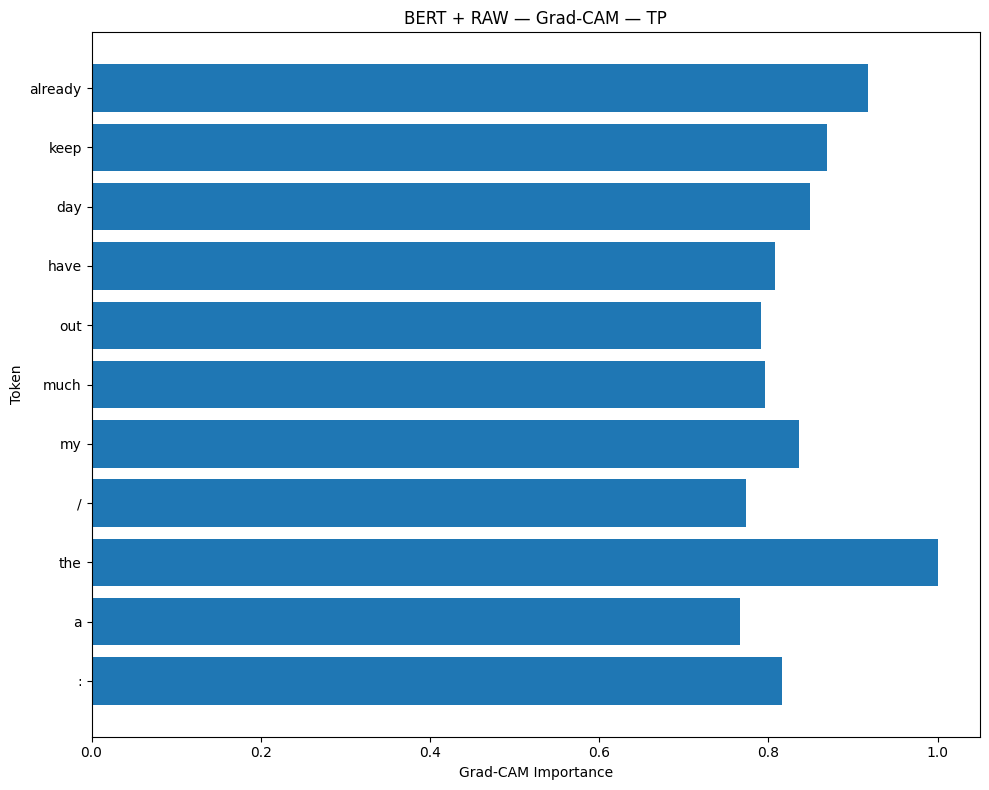

Saved: /kaggle/working/bert_raw/explainability/gradcam/bert_raw_gradcam_tp_tokens.csv

Processing TN (test index 0)
Target class : 0
Raw Grad-CAM: min = -0.005576533265411854 max = 0.003182272193953395


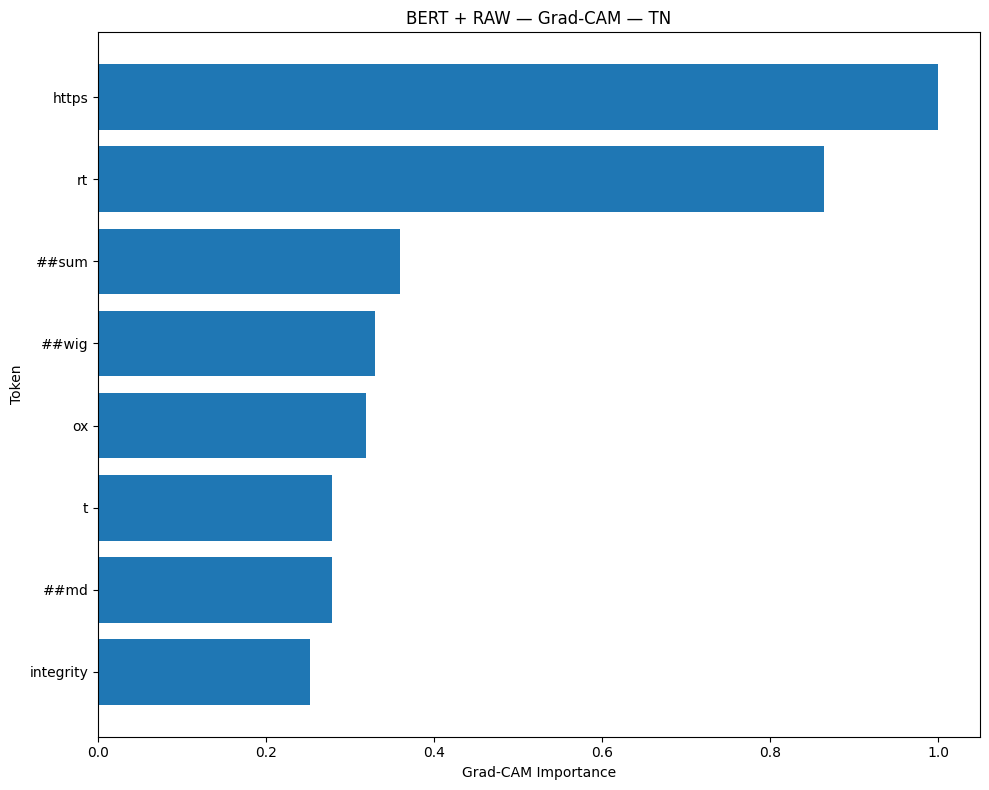

Saved: /kaggle/working/bert_raw/explainability/gradcam/bert_raw_gradcam_tn_tokens.csv

Processing FP (test index 7)
Target class : 1
Raw Grad-CAM: min = -0.004788589663803577 max = 0.004223085939884186


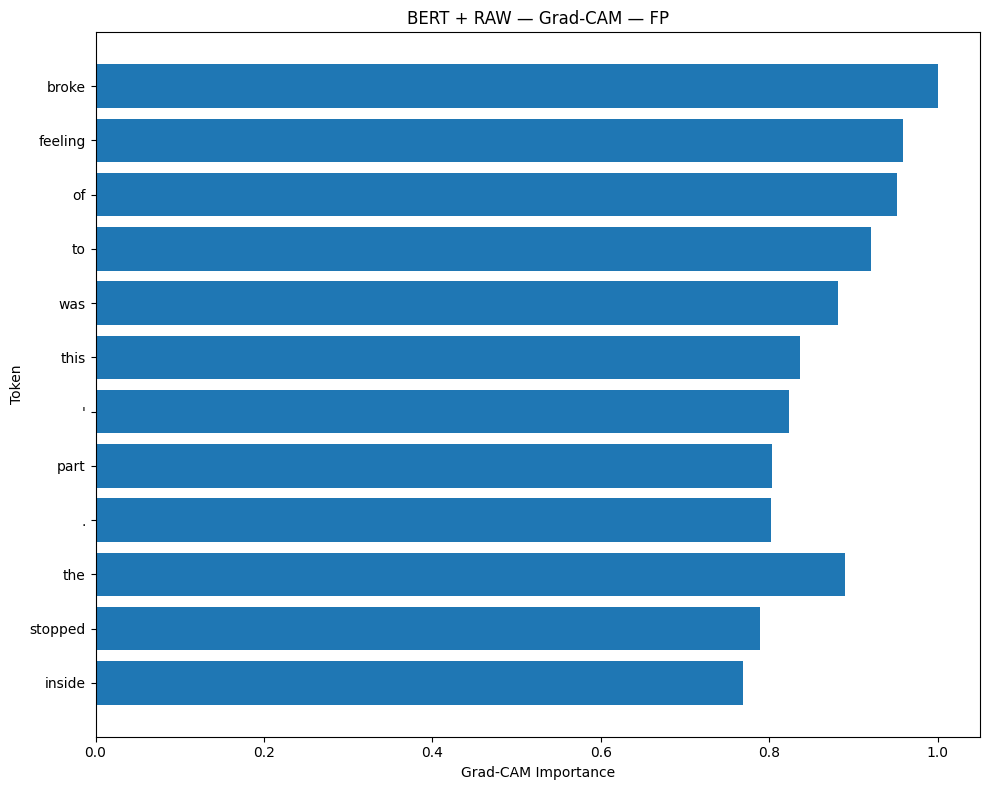

Saved: /kaggle/working/bert_raw/explainability/gradcam/bert_raw_gradcam_fp_tokens.csv

Processing FN (test index 14)
Target class : 0
Raw Grad-CAM: min = -0.006111530587077141 max = 0.0028635079506784678


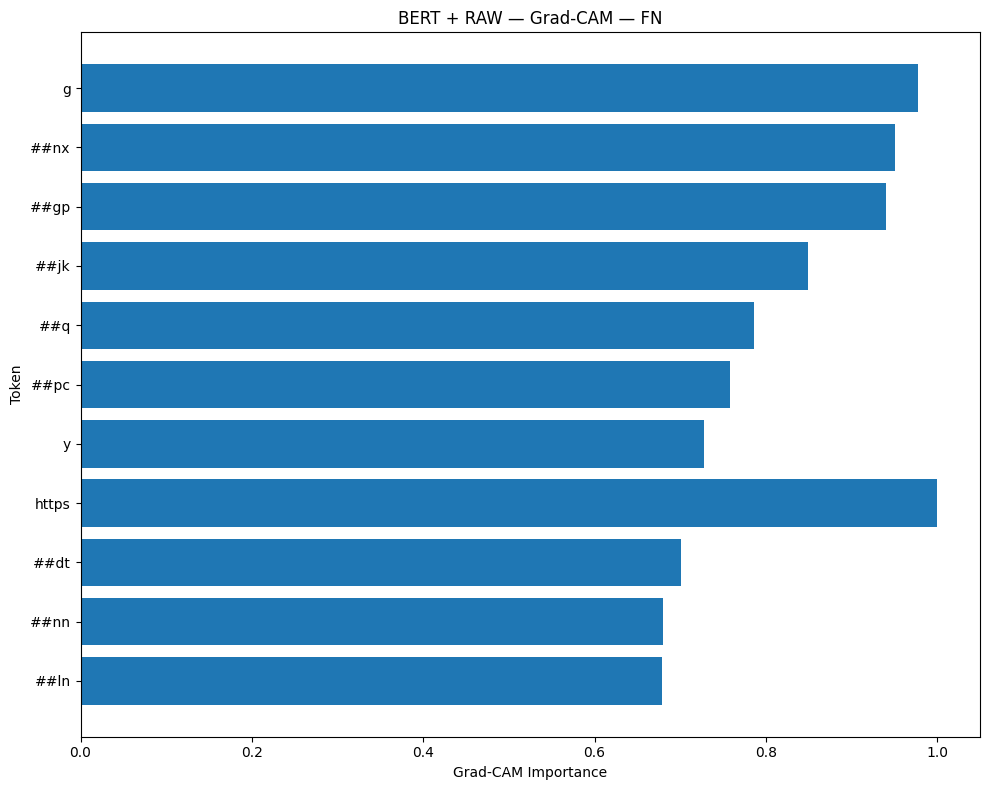

Saved: /kaggle/working/bert_raw/explainability/gradcam/bert_raw_gradcam_fn_tokens.csv

GRAD-CAM COMPLETE
Output directory:
/kaggle/working/bert_raw/explainability/gradcam
Configuration saved:
/kaggle/working/bert_raw/explainability/gradcam/bert_raw_gradcam_config.json
Cases processed: ['TP', 'TN', 'FP', 'FN']
✓ Memory-safe test prediction
✓ TP explained using Positive class
✓ TN explained using Negative class
✓ FP explained using Positive class
✓ FN explained using Negative class
✓ Final BERT hidden states used
✓ Metadata branch included
✓ Fusion = 768 + 64 = 832
✓ CUDA memory cleaned


In [18]:
# ============================================================
# EXPLAINABILITY — CELL 2
# BERT + RAW
# GRAD-CAM: TOKEN-LEVEL LOCAL EXPLANATION
# MEMORY-SAFE VERSION
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


print("=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("BERT + RAW")
print("=" * 70)


# ============================================================
# CUDA MEMORY CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


print(
    "✓ CUDA memory cleared"
)


# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(
    GRADCAM_SEED
)

torch.manual_seed(
    GRADCAM_SEED
)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()


# Freeze BERT parameters
for parameter in model.parameters():

    if parameter.requires_grad:

        parameter.requires_grad = False


model.zero_grad(
    set_to_none=True
)


print(
    "✓ BERT + RAW model loaded"
)

print(
    "✓ Evaluation mode enabled"
)

print(
    "✓ Model parameters frozen"
)


# ============================================================
# STEP 1 — CALCULATE TEST PREDICTIONS
# MEMORY-SAFE:
# ONE TEST USER AT A TIME
# ============================================================

labels_np = []
preds_np = []
probs_np = []


print()
print("=" * 70)
print("CALCULATING TEST PREDICTIONS")
print("=" * 70)


num_test_samples = len(
    test_dataset
)


for test_index in range(
    num_test_samples
):

    sample = test_dataset[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    with torch.inference_mode():

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        logits = output[
            "logits"
        ]


        probabilities = torch.softmax(
            logits,
            dim=1
        )


        prediction = torch.argmax(
            logits,
            dim=1
        )


        labels_np.append(
            int(
                sample[
                    "labels"
                ].item()
            )
        )


        preds_np.append(
            int(
                prediction.item()
            )
        )


        probs_np.append(
            float(
                probabilities[
                    0,
                    1
                ].item()
            )
        )


    del (
        input_ids,
        attention_mask,
        metadata,
        output,
        logits,
        probabilities,
        prediction
    )


    if (
        test_index % 25 == 0
    ):

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    if (
        test_index == 0
        or
        (test_index + 1) % 100 == 0
        or
        test_index == num_test_samples - 1
    ):

        print(
            f"Processed "
            f"{test_index + 1}/"
            f"{num_test_samples}"
        )


labels_np = np.asarray(
    labels_np
)

preds_np = np.asarray(
    preds_np
)

probs_np = np.asarray(
    probs_np
)


print()
print("=" * 70)
print("TEST PREDICTIONS READY")
print("=" * 70)

print(
    "Test samples:",
    len(labels_np)
)


# ============================================================
# STEP 2 — SELECT TP / TN / FP / FN CASES
# ============================================================

selected_cases = {}


tp_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 1)
)[0]


tn_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 0)
)[0]


fp_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 1)
)[0]


fn_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 0)
)[0]


if len(
    tp_candidates
) > 0:

    selected_cases[
        "TP"
    ] = int(
        tp_candidates[0]
    )


if len(
    tn_candidates
) > 0:

    selected_cases[
        "TN"
    ] = int(
        tn_candidates[0]
    )


if len(
    fp_candidates
) > 0:

    selected_cases[
        "FP"
    ] = int(
        fp_candidates[0]
    )


if len(
    fn_candidates
) > 0:

    selected_cases[
        "FN"
    ] = int(
        fn_candidates[0]
    )


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_type, test_index in selected_cases.items():

    print(
        f"{case_type} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )


# ============================================================
# STEP 3 — GRAD-CAM COMPUTATION
# ============================================================

def compute_bert_raw_gradcam(
    test_index
):

    # --------------------------------------------------------
    # CLEAN MEMORY BEFORE EACH CASE
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    sample = test_dataset[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # TARGET CLASS
    #
    # TP -> predicted class 1
    # TN -> predicted class 0
    # FP -> predicted class 1
    # FN -> predicted class 0
    # --------------------------------------------------------

    target_class = int(
        preds_np[
            test_index
        ]
    )


    # --------------------------------------------------------
    # CLEAR OLD GRADIENTS
    # --------------------------------------------------------

    model.zero_grad(
        set_to_none=True
    )


    # --------------------------------------------------------
    # BERT ENCODER
    #
    # The BERT backbone is frozen.
    # We therefore compute its hidden states without
    # building the full parameter gradient graph.
    #
    # Then gradients are enabled only on the detached
    # token hidden-state activation used by Grad-CAM.
    # --------------------------------------------------------

    with torch.no_grad():

        encoder_output = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )


    hidden_states = (
        encoder_output
        .last_hidden_state
        .detach()
    )


    del encoder_output


    hidden_states.requires_grad_(
        True
    )

    hidden_states.retain_grad()


    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    projected = torch.tanh(
        model.attention_projection(
            hidden_states
        )
    )


    attention_scores = (
        model.attention_score(
            projected
        )
        .squeeze(-1)
    )


    # Mask padding
    attention_scores = (
        attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )
    )


    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )


    text_representation = torch.sum(
        hidden_states
        *
        attention_weights.unsqueeze(-1),
        dim=1
    )


    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = (
        model.metadata_branch(
            metadata
        )
    )


    # --------------------------------------------------------
    # METADATA GATE
    # --------------------------------------------------------

    metadata_gate = torch.sigmoid(
        model.metadata_beta
    )


    gated_metadata = (
        metadata_gate
        *
        metadata_representation
    )


    # --------------------------------------------------------
    # FUSION
    #
    # BERT text = 768
    # Metadata = 64
    # Fusion = 832
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            gated_metadata
        ],
        dim=1
    )


    # --------------------------------------------------------
    # CLASSIFIER
    # --------------------------------------------------------

    logits = model.classifier(
        fused
    )


    # --------------------------------------------------------
    # TARGET LOGIT
    #
    # Explain the class actually predicted by the model.
    # --------------------------------------------------------

    target_logit = logits[
        :,
        target_class
    ]


    # --------------------------------------------------------
    # BACKWARD
    # --------------------------------------------------------

    target_logit.backward()


    gradients = (
        hidden_states.grad
    )


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    channel_weights = (
        gradients.mean(
            dim=1,
            keepdim=True
        )
    )


    raw_gradcam = (
        channel_weights
        *
        hidden_states
    ).sum(
        dim=-1
    )


    # --------------------------------------------------------
    # DIAGNOSTIC
    # --------------------------------------------------------

    raw_min = float(
        raw_gradcam.min()
        .detach()
        .cpu()
    )


    raw_max = float(
        raw_gradcam.max()
        .detach()
        .cpu()
    )


    print(
        f"Target class : {target_class}"
    )


    print(
        "Raw Grad-CAM:",
        "min =",
        raw_min,
        "max =",
        raw_max
    )


    # --------------------------------------------------------
    # POSITIVE GRAD-CAM
    # --------------------------------------------------------

    gradcam = torch.relu(
        raw_gradcam
    )


    # --------------------------------------------------------
    # REMOVE BATCH DIMENSION
    # --------------------------------------------------------

    gradcam = (
        gradcam
        .squeeze(0)
    )


    attention_weights = (
        attention_weights
        .squeeze(0)
    )


    valid_mask = (
        attention_mask
        .squeeze(0)
    )


    # --------------------------------------------------------
    # MOVE TO CPU
    # --------------------------------------------------------

    gradcam = (
        gradcam
        .detach()
        .cpu()
        .numpy()
    )


    attention_weights = (
        attention_weights
        .detach()
        .cpu()
        .numpy()
    )


    valid_mask = (
        valid_mask
        .detach()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # REMOVE PADDING
    # --------------------------------------------------------

    gradcam = (
        gradcam
        *
        valid_mask
    )


    # --------------------------------------------------------
    # NORMALIZATION
    # --------------------------------------------------------

    if gradcam.max() > 0:

        gradcam = (
            gradcam
            /
            gradcam.max()
        )


    # --------------------------------------------------------
    # FALLBACK
    #
    # If positive Grad-CAM is completely zero,
    # use absolute raw Grad-CAM magnitude for visualization.
    # --------------------------------------------------------

    if gradcam.max() == 0:

        raw_gradcam_np = np.abs(
            raw_gradcam
            .squeeze(0)
            .detach()
            .cpu()
            .numpy()
        )


        raw_gradcam_np = (
            raw_gradcam_np
            *
            valid_mask
        )


        if raw_gradcam_np.max() > 0:

            gradcam = (
                raw_gradcam_np
                /
                raw_gradcam_np.max()
            )


    # --------------------------------------------------------
    # SAVE RESULT
    # --------------------------------------------------------

    result = {

        "gradcam":
            gradcam,

        "attention_weights":
            attention_weights,

        "input_ids":
            sample[
                "input_ids"
            ]
            .cpu()
            .numpy(),

        "attention_mask":
            sample[
                "attention_mask"
            ]
            .cpu()
            .numpy(),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "target_class":
            target_class,

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            )
    }


    # --------------------------------------------------------
    # DELETE GPU TENSORS
    # --------------------------------------------------------

    del (
        input_ids,
        attention_mask,
        metadata,
        hidden_states,
        projected,
        attention_scores,
        attention_weights,
        text_representation,
        metadata_representation,
        metadata_gate,
        gated_metadata,
        fused,
        logits,
        target_logit,
        gradients,
        channel_weights,
        raw_gradcam
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return result


# ============================================================
# STEP 4 — TOKEN INFORMATION
# ============================================================

def get_token_information(
    input_ids,
    attention_mask,
    gradcam,
    tokenizer,
    top_tokens=20
):

    token_ids = input_ids[
        attention_mask.astype(bool)
    ]


    importance = gradcam[
        attention_mask.astype(bool)
    ]


    tokens = (
        tokenizer.convert_ids_to_tokens(
            token_ids.tolist()
        )
    )


    token_information = []


    for token, score in zip(
        tokens,
        importance
    ):

        if token in tokenizer.all_special_tokens:

            continue


        token_information.append(
            {
                "token":
                    token,

                "importance":
                    float(score)
            }
        )


    token_information = sorted(
        token_information,
        key=lambda x:
            x["importance"],
        reverse=True
    )


    for rank, item in enumerate(
        token_information,
        start=1
    ):

        item[
            "rank"
        ] = rank


    return token_information[
        :top_tokens
    ]


# ============================================================
# STEP 5 — RUN TP / TN / FP / FN
# ============================================================

all_gradcam_results = []


print()
print("=" * 70)
print("GENERATING GRAD-CAM EXPLANATIONS")
print("=" * 70)


for case_type, test_index in selected_cases.items():

    print()
    print("=" * 70)

    print(
        f"Processing {case_type} "
        f"(test index {test_index})"
    )

    print("=" * 70)


    result = (
        compute_bert_raw_gradcam(
            test_index
        )
    )


    token_information = (
        get_token_information(

            result[
                "input_ids"
            ],

            result[
                "attention_mask"
            ],

            result[
                "gradcam"
            ],

            bert_raw_tokenizer,

            GRADCAM_TOP_TOKENS
        )
    )


    token_df = pd.DataFrame(
        token_information
    )


    # --------------------------------------------------------
    # SAVE TOKEN CSV
    # --------------------------------------------------------

    token_csv_path = os.path.join(

        GRADCAM_DIR,

        (
            "bert_raw_gradcam_"
            f"{case_type.lower()}_tokens.csv"
        )

    )


    token_df.to_csv(

        token_csv_path,

        index=False

    )


    # --------------------------------------------------------
    # TOP TOKEN PLOT
    # --------------------------------------------------------

    plot_df = token_df.sort_values(

        "importance",

        ascending=True

    )


    plt.figure(
        figsize=(10, 8)
    )


    plt.barh(

        plot_df[
            "token"
        ],

        plot_df[
            "importance"
        ]

    )


    plt.xlabel(
        "Grad-CAM Importance"
    )


    plt.ylabel(
        "Token"
    )


    plt.title(

        (
            "BERT + RAW — "
            f"Grad-CAM — {case_type}"
        )

    )


    plt.tight_layout()


    plot_path = os.path.join(

        GRADCAM_DIR,

        (
            "bert_raw_gradcam_"
            f"{case_type.lower()}.png"
        )

    )


    plt.savefig(

        plot_path,

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()

    plt.close()


    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    all_gradcam_results.append(

        {

            "case_type":
                case_type,

            "test_index":
                test_index,

            "true_label":
                result[
                    "true_label"
                ],

            "predicted_label":
                result[
                    "predicted_label"
                ],

            "target_class":
                result[
                    "target_class"
                ],

            "positive_probability":
                result[
                    "positive_probability"
                ],

            "top_tokens":
                token_information

        }

    )


    print(
        f"Saved: {token_csv_path}"
    )


    # --------------------------------------------------------
    # CLEAN MEMORY
    # --------------------------------------------------------

    del (
        result,
        token_information,
        token_df,
        plot_df
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# STEP 6 — SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "BERT",

    "model_name":
        MODEL_NAME,

    "architecture":
        "BERT + Metadata Branch",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "method":
        "Transformer Grad-CAM",

    "target":
        "Predicted class logit",

    "target_classes":
        {
            "TP":
                "Positive",

            "TN":
                "Negative",

            "FP":
                "Positive",

            "FN":
                "Negative"
        },

    "hidden_dimension":
        768,

    "text_representation_dimension":
        768,

    "metadata_representation_dimension":
        64,

    "fused_representation_dimension":
        832,

    "metadata_gate":
        "sigmoid(metadata_beta)",

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen",

    "prediction_batch_size":
        1,

    "fallback_visualization":
        "Absolute raw Grad-CAM magnitude if positive activation is zero"
}


config_path = os.path.join(

    GRADCAM_DIR,

    "bert_raw_gradcam_config.json"

)


with open(

    config_path,

    "w"

) as f:


    json.dump(

        gradcam_config,

        f,

        indent=4

    )


# ============================================================
# FINAL CUDA CLEANUP
# ============================================================

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM COMPLETE")
print("=" * 70)


print(
    f"Output directory:\n"
    f"{GRADCAM_DIR}"
)


print(
    f"Configuration saved:\n"
    f"{config_path}"
)


print(
    "Cases processed:",
    list(
        selected_cases.keys()
    )
)


print(
    "✓ Memory-safe test prediction"
)


print(
    "✓ TP explained using Positive class"
)


print(
    "✓ TN explained using Negative class"
)


print(
    "✓ FP explained using Positive class"
)


print(
    "✓ FN explained using Negative class"
)


print(
    "✓ Final BERT hidden states used"
)


print(
    "✓ Metadata branch included"
)


print(
    "✓ Fusion = 768 + 64 = 832"
)


print(
    "✓ CUDA memory cleaned"
)


print("=" * 70)

SHAP ANALYSIS
BERT + RAW
✓ CUDA memory cleared
✓ Metadata features confirmed: 53
✓ BERT + RAW model loaded
✓ Evaluation mode enabled
✓ Model parameters frozen for SHAP

SHAP BACKGROUND
Background samples: 50
Metadata dimensions: 53

SHAP TEST USERS
Negative users: 50
Positive users: 50
Total users: 100

GENERATING SHAP EXPLANATIONS

Processing user 1/100 (test index 448)
Fixed text representation: (1, 768)
Processed 1/100

Processing user 2/100 (test index 741)
Fixed text representation: (1, 768)

Processing user 3/100 (test index 656)
Fixed text representation: (1, 768)

Processing user 4/100 (test index 231)
Fixed text representation: (1, 768)

Processing user 5/100 (test index 743)
Fixed text representation: (1, 768)

Processing user 6/100 (test index 202)
Fixed text representation: (1, 768)

Processing user 7/100 (test index 306)
Fixed text representation: (1, 768)

Processing user 8/100 (test index 756)
Fixed text representation: (1, 768)

Processing user 9/100 (test index 477)
Fi

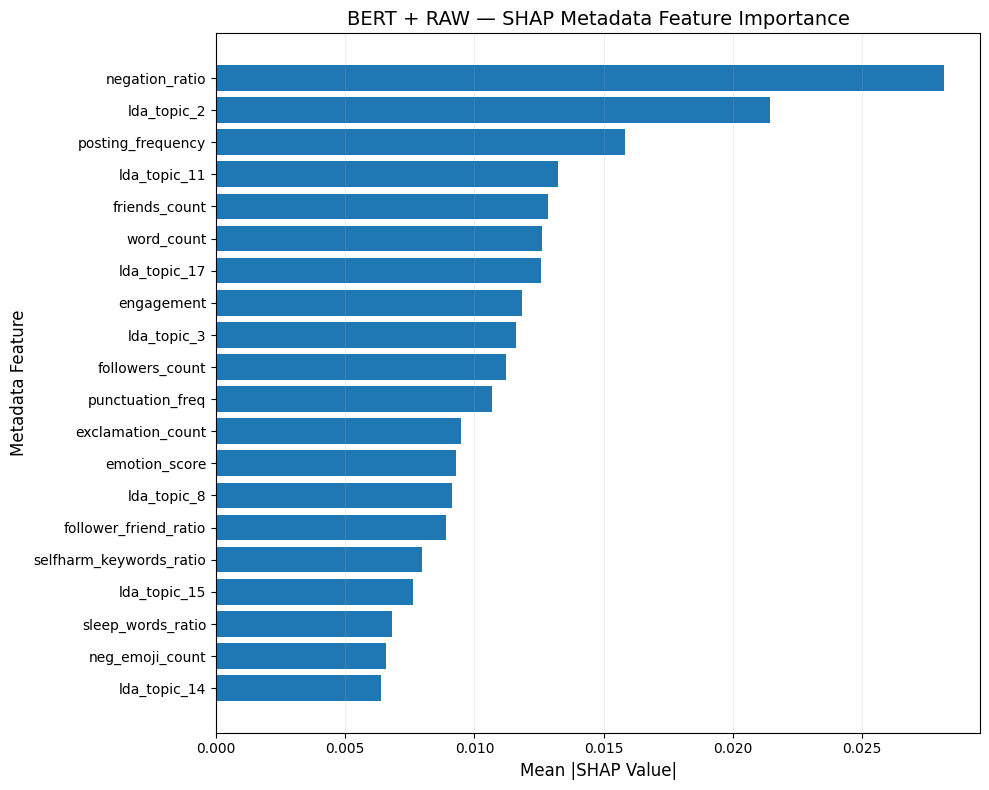

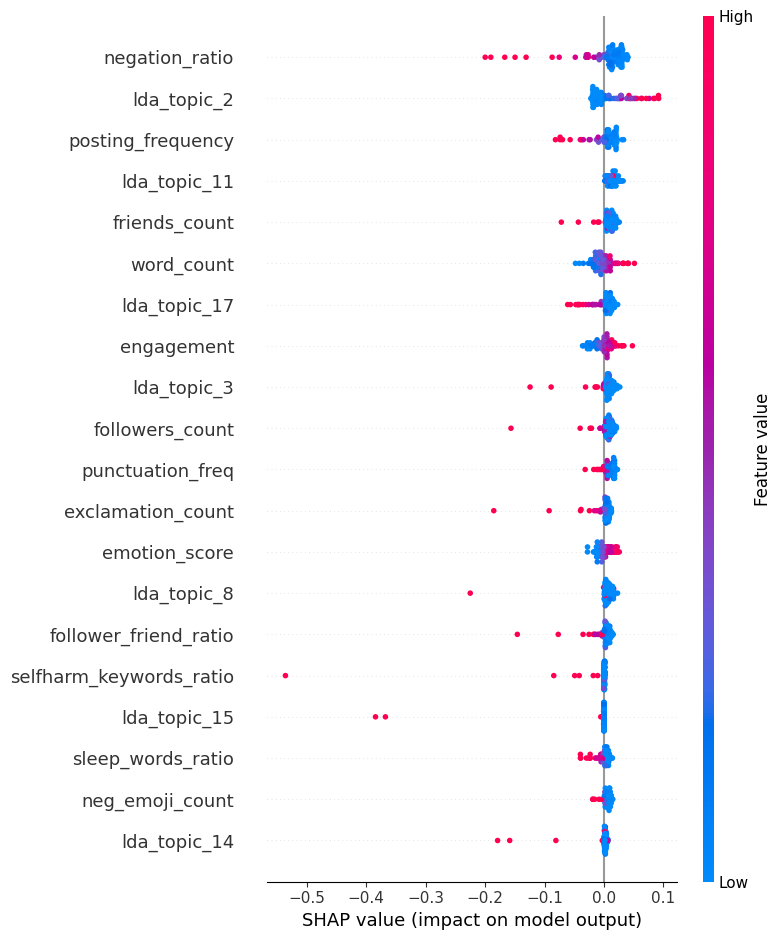


SHAP ANALYSIS COMPLETE
✓ 53 metadata features used
✓ 50 negative + 50 positive test users targeted
✓ BERT text representation fixed per user
✓ Learned metadata gate included
✓ Metadata-only SHAP explanations generated
✓ Global feature importance calculated
✓ SHAP summary plot saved
✓ Top feature plot saved
✓ SHAP CSV saved
✓ Configuration saved

SHAP output directory: /kaggle/working/bert_raw/explainability/shap


In [19]:
# ============================================================
# EXPLAINABILITY — CELL 3
# BERT + RAW
# SHAP: METADATA-LEVEL GLOBAL EXPLANATION
# MEMORY-SAFE VERSION
# ============================================================

import os
import json
import random
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap


print("=" * 70)
print("SHAP ANALYSIS")
print("BERT + RAW")
print("=" * 70)


# ============================================================
# CUDA MEMORY CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


print(
    "✓ CUDA memory cleared"
)


# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42

SHAP_BACKGROUND_SIZE = 50

SHAP_TEST_SIZE_PER_CLASS = 50

SHAP_TOP_FEATURES = 20


np.random.seed(
    SHAP_SEED
)


random.seed(
    SHAP_SEED
)


torch.manual_seed(
    SHAP_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(

    BASE_RESULT_DIR,

    "explainability"

)


SHAP_DIR = os.path.join(

    EXPLAINABILITY_DIR,

    "shap"

)


os.makedirs(

    SHAP_DIR,

    exist_ok=True

)


# ============================================================
# EXACT 53 METADATA FEATURE NAMES
# ============================================================

behavioral_features = [

    "posting_frequency",

    "follower_friend_ratio",

    "night_posting_ratio",

    "engagement",

    "followers_count",

    "friends_count",

    "statuses_count",

    "favourites_count"

]


linguistic_features = [

    "first_person_ratio",

    "negation_ratio",

    "uppercase_ratio",

    "punctuation_freq"

]


readability_features = [

    "flesch_reading_ease",

    "gunning_fog",

    "flesch_kincaid_grade"

]


emotional_features = [

    "sentiment_score",

    "emotion_score",

    "pos_emoji_count",

    "neg_emoji_count",

    "emoji_density",

    "exclamation_count"

]


psychological_features = [

    "depression_lexicon_score",

    "hopelessness_score",

    "loneliness_score",

    "anxiety_score",

    "sleep_words_ratio",

    "fatigue_words_ratio",

    "selfharm_keywords_ratio"

]


writing_style_features = [

    "avg_sentence_length",

    "lexical_diversity",

    "word_count",

    "avg_paragraph_length",

    "repeated_letters"

]


lda_features = [

    f"lda_topic_{i}"

    for i in range(
        1,
        21
    )

]


raw_metadata_features = (

    behavioral_features

    + linguistic_features

    + readability_features

    + emotional_features

    + psychological_features

    + writing_style_features

    + lda_features

)


assert len(
    raw_metadata_features
) == 53


print(
    f"✓ Metadata features confirmed: "
    f"{len(raw_metadata_features)}"
)


# ============================================================
# MODEL PREPARATION
# ============================================================

model.eval()


# Freeze all model parameters
for parameter in model.parameters():

    parameter.requires_grad = False


model.zero_grad(
    set_to_none=True
)


print(
    "✓ BERT + RAW model loaded"
)


print(
    "✓ Evaluation mode enabled"
)


print(
    "✓ Model parameters frozen for SHAP"
)


# ============================================================
# SHAP WRAPPER
#
# IMPORTANT:
#
# The text representation is computed ONCE for each
# explained user.
#
# SHAP varies ONLY the 53 metadata features.
#
# Therefore BERT is NOT repeatedly executed by SHAP.
# ============================================================

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_text_representation
    ):

        super().__init__()


        self.base_model = (
            base_model
        )


        self.register_buffer(
            "fixed_text_representation",
            fixed_text_representation
        )


    def forward(
        self,
        metadata
    ):

        batch_size = (
            metadata.shape[0]
        )


        # ----------------------------------------------------
        # METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (

            self.base_model
            .metadata_branch(
                metadata
            )

        )


        # ----------------------------------------------------
        # LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(

            self.base_model
            .metadata_beta

        )


        gated_metadata = (

            metadata_gate
            *
            metadata_representation

        )


        # ----------------------------------------------------
        # FIXED BERT TEXT REPRESENTATION
        # ----------------------------------------------------

        text_representation = (

            self.fixed_text_representation

            .expand(
                batch_size,
                -1
            )

        )


        # ----------------------------------------------------
        # EXACT FUSION
        #
        # BERT text = 768
        # metadata = 64
        # total = 832
        # ----------------------------------------------------

        fused = torch.cat(

            [
                text_representation,
                gated_metadata
            ],

            dim=1

        )


        # ----------------------------------------------------
        # EXACT CLASSIFIER
        # ----------------------------------------------------

        logits = (

            self.base_model
            .classifier(
                fused
            )

        )


        # Positive / depression class logit
        return logits[
            :,
            1:2
        ]


# ============================================================
# FIXED TEXT REPRESENTATION
#
# BERT runs ONCE per explained user.
# ============================================================

def get_fixed_text_representation(
    input_ids,
    attention_mask
):

    # --------------------------------------------------------
    # FROZEN BERT ENCODER
    # --------------------------------------------------------

    with torch.no_grad():

        encoder_output = model.encoder(

            input_ids=input_ids,

            attention_mask=attention_mask

        )


        hidden_states = (

            encoder_output
            .last_hidden_state

        )


    # --------------------------------------------------------
    # ATTENTION POOLING
    #
    # EXACT SAME OPERATION AS MODEL FORWARD
    # --------------------------------------------------------

    projected = torch.tanh(

        model.attention_projection(
            hidden_states
        )

    )


    attention_scores = (

        model.attention_score(
            projected
        )

        .squeeze(-1)

    )


    attention_scores = (

        attention_scores.masked_fill(

            attention_mask == 0,

            -1e9

        )

    )


    attention_weights = torch.softmax(

        attention_scores,

        dim=1

    )


    text_representation = torch.sum(

        hidden_states

        *

        attention_weights.unsqueeze(
            -1
        ),

        dim=1

    )


    return (
        text_representation
        .detach()
    )


# ============================================================
# BACKGROUND METADATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (

    train_dataset
    .metadata[
        :SHAP_BACKGROUND_SIZE
    ]

    .clone()
    .detach()
    .float()
    .to(device)

)


print()
print("=" * 70)
print("SHAP BACKGROUND")
print("=" * 70)


print(
    "Background samples:",
    background_metadata.shape[0]
)


print(
    "Metadata dimensions:",
    background_metadata.shape[1]
)


assert (
    background_metadata.shape[0]
    ==
    SHAP_BACKGROUND_SIZE
)


assert (
    background_metadata.shape[1]
    ==
    53
)


# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels = (

    test_dataset
    .labels
    .detach()
    .cpu()
    .numpy()

)


negative_indices = np.where(

    test_labels == 0

)[0]


positive_indices = np.where(

    test_labels == 1

)[0]


np.random.seed(
    SHAP_SEED
)


negative_indices = np.random.choice(

    negative_indices,

    size=min(

        SHAP_TEST_SIZE_PER_CLASS,

        len(
            negative_indices
        )

    ),

    replace=False

)


positive_indices = np.random.choice(

    positive_indices,

    size=min(

        SHAP_TEST_SIZE_PER_CLASS,

        len(
            positive_indices
        )

    ),

    replace=False

)


selected_shap_indices = np.concatenate(

    [

        negative_indices,

        positive_indices

    ]

)


print()
print("=" * 70)
print("SHAP TEST USERS")
print("=" * 70)


print(
    "Negative users:",
    len(
        negative_indices
    )
)


print(
    "Positive users:",
    len(
        positive_indices
    )
)


print(
    "Total users:",
    len(
        selected_shap_indices
    )
)


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_rows = []

all_user_importance = []


print()
print("=" * 70)
print("GENERATING SHAP EXPLANATIONS")
print("=" * 70)


for count, test_index in enumerate(

    selected_shap_indices,

    start=1

):

    test_index = int(
        test_index
    )


    # --------------------------------------------------------
    # CLEAR MEMORY BEFORE EACH USER
    # --------------------------------------------------------

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


        # ----------------------------------------------------
        # GET USER SAMPLE
        # ----------------------------------------------------

    sample = test_dataset[
        test_index
    ]


    input_ids = (

        sample[
            "input_ids"
        ]

        .unsqueeze(0)

        .to(device)

    )


    attention_mask = (

        sample[
            "attention_mask"
        ]

        .unsqueeze(0)

        .to(device)

    )


    metadata = (

        sample[
            "metadata"
        ]

        .unsqueeze(0)

        .float()

        .to(device)

    )


    true_label = int(

        sample[
            "labels"
        ].item()

    )


    # ========================================================
    # STEP 1 — FIX TEXT REPRESENTATION
    # ========================================================

    fixed_text_representation = (

        get_fixed_text_representation(

            input_ids,

            attention_mask

        )

    )


    assert (
        fixed_text_representation.shape
        ==
        (1, 768)
    )


    print()
    print(

        f"Processing user "
        f"{count}/"
        f"{len(selected_shap_indices)} "
        f"(test index {test_index})"

    )


    print(

        "Fixed text representation:",

        tuple(
            fixed_text_representation.shape
        )

    )


    # ========================================================
    # STEP 2 — SHAP WRAPPER
    # ========================================================

    wrapper = MetadataSHAPWrapper(

        base_model=model,

        fixed_text_representation=
            fixed_text_representation

    ).to(device)


    wrapper.eval()


    # ========================================================
    # STEP 3 — GRADIENT SHAP
    # ========================================================

    #
    # batch_size=1 keeps memory usage low.
    #
    # The BERT encoder is NOT inside the SHAP wrapper.
    # Only the 53-dimensional metadata path is evaluated.
    #

    explainer = shap.GradientExplainer(

        wrapper,

        background_metadata,

        batch_size=1

    )


    # ========================================================
    # STEP 4 — COMPUTE SHAP VALUES
    # ========================================================

    shap_values = (

        explainer.shap_values(

            metadata

        )

    )


    # ========================================================
    # STEP 5 — SHAP VERSION HANDLING
    # ========================================================

    if isinstance(

        shap_values,

        list

    ):

        shap_array = np.asarray(

            shap_values[0]

        )

    else:

        shap_array = np.asarray(

            shap_values

        )


    shap_array = np.squeeze(

        shap_array

    )


    # ========================================================
    # SAFETY CHECK
    # ========================================================

    assert len(

        shap_array

    ) == len(

        raw_metadata_features

    )


    # ========================================================
    # SAVE USER-LEVEL IMPORTANCE
    # ========================================================

    user_importance = pd.DataFrame({

        "feature":

            raw_metadata_features,

        "shap_value":

            shap_array,

        "abs_shap_value":

            np.abs(
                shap_array
            )

    })


    user_importance = (

        user_importance

        .sort_values(

            "abs_shap_value",

            ascending=False

        )

        .reset_index(

            drop=True

        )

    )


    user_importance[
        "test_index"
    ] = test_index


    user_importance[
        "true_label"
    ] = true_label


    all_user_importance.append(

        user_importance

    )


    # ========================================================
    # SAVE ALL FEATURE RESULTS
    # ========================================================

    for rank, row in enumerate(

        user_importance.itertuples(
            index=False
        ),

        start=1

    ):


        all_shap_rows.append({

            "test_index":

                test_index,

            "true_label":

                true_label,

            "feature":

                row.feature,

            "shap_value":

                float(
                    row.shap_value
                ),

            "abs_shap_value":

                float(
                    row.abs_shap_value
                ),

            "rank":

                rank

        })


    # ========================================================
    # PROGRESS
    # ========================================================

    if (

        count == 1

        or

        count % 10 == 0

        or

        count ==
        len(
            selected_shap_indices
        )

    ):

        print(

            f"Processed "
            f"{count}/"
            f"{len(selected_shap_indices)}"

        )


    # ========================================================
    # CLEAN USER MEMORY
    # ========================================================

    del (

        input_ids,

        attention_mask,

        metadata,

        fixed_text_representation,

        wrapper,

        explainer,

        shap_values,

        shap_array,

        user_importance

    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# COMBINE SHAP RESULTS
# ============================================================

shap_results_df = pd.DataFrame(

    all_shap_rows

)


shap_csv_path = os.path.join(

    SHAP_DIR,

    "bert_raw_shap_values.csv"

)


shap_results_df.to_csv(

    shap_csv_path,

    index=False

)


# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

global_importance = (

    shap_results_df

    .groupby(
        "feature"
    )[

        "abs_shap_value"

    ]

    .mean()

    .sort_values(

        ascending=False

    )

    .reset_index()

)


global_importance.columns = [

    "feature",

    "mean_abs_shap_value"

]


global_importance[
    "rank"
] = (

    np.arange(

        len(
            global_importance
        )

    )

    + 1

)


global_importance_csv = os.path.join(

    SHAP_DIR,

    "bert_raw_shap_feature_importance.csv"

)


global_importance.to_csv(

    global_importance_csv,

    index=False

)


# ============================================================
# TOP FEATURES
# ============================================================

top_features = (

    global_importance

    .head(
        SHAP_TOP_FEATURES
    )

    .copy()

)


print()
print("=" * 70)
print("TOP SHAP FEATURES")
print("=" * 70)


print(

    top_features[

        [

            "rank",

            "feature",

            "mean_abs_shap_value"

        ]

    ]

    .to_string(
        index=False
    )

)


# ============================================================
# PAPER-READY GLOBAL BAR PLOT
# ============================================================

plot_df = (

    top_features

    .iloc[::-1]

)


plt.figure(

    figsize=(10, 8)

)


plt.barh(

    plot_df[
        "feature"
    ],

    plot_df[
        "mean_abs_shap_value"
    ]

)


plt.xlabel(

    "Mean |SHAP Value|",

    fontsize=12

)


plt.ylabel(

    "Metadata Feature",

    fontsize=12

)


plt.title(

    (
        "BERT + RAW — "
        "SHAP Metadata Feature Importance"
    ),

    fontsize=14

)


plt.grid(

    axis="x",

    alpha=0.20

)


plt.tight_layout()


global_plot_path = os.path.join(

    SHAP_DIR,

    "bert_raw_shap_global_feature_importance.png"

)


plt.savefig(

    global_plot_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ============================================================
# SHAP SUMMARY / BEESWARM
# ============================================================

# users × features

shap_matrix = np.zeros(

    (

        len(
            selected_shap_indices
        ),

        len(
            raw_metadata_features
        )

    ),

    dtype=np.float32

)


for row_index, test_index in enumerate(

    selected_shap_indices

):

    user_rows = shap_results_df[

        shap_results_df[
            "test_index"
        ]

        == int(
            test_index
        )

    ]


    feature_map = dict(

        zip(

            user_rows[
                "feature"
            ],

            user_rows[
                "shap_value"
            ]

        )

    )


    for feature_index, feature in enumerate(

        raw_metadata_features

    ):

        shap_matrix[

            row_index,

            feature_index

        ] = feature_map.get(

            feature,

            0.0

        )


metadata_matrix = np.asarray(

    [

        test_dataset
        .metadata[
            int(
                test_index
            )
        ]
        .cpu()
        .numpy()

        for test_index in

        selected_shap_indices

    ],

    dtype=np.float32

)


plt.figure(

    figsize=(10, 8)

)


shap.summary_plot(

    shap_matrix,

    metadata_matrix,

    feature_names=
        raw_metadata_features,

    max_display=
        SHAP_TOP_FEATURES,

    show=False

)


plt.tight_layout()


summary_plot_path = os.path.join(

    SHAP_DIR,

    "bert_raw_shap_summary.png"

)


plt.savefig(

    summary_plot_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()

plt.close()


# ============================================================
# SAVE USER INFORMATION
# ============================================================

user_information = []


for test_index in selected_shap_indices:

    test_index = int(
        test_index
    )


    user_information.append({

        "test_index":

            test_index,

        "true_label":

            int(

                test_dataset
                .labels[
                    test_index
                ]
                .item()

            )

    })


user_information_df = pd.DataFrame(

    user_information

)


user_information_path = os.path.join(

    SHAP_DIR,

    "bert_raw_shap_user_information.csv"

)


user_information_df.to_csv(

    user_information_path,

    index=False

)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

metadata_gate_final = float(

    torch.sigmoid(

        model.metadata_beta

    )

    .detach()

    .cpu()

)


shap_config = {

    "model":

        "BERT",

    "model_name":

        MODEL_NAME,

    "cleaning":

        "RAW",

    "dataset":

        "Held-out test set",

    "method":

        "SHAP GradientExplainer",

    "explanation_target":

        "Positive/depression class logit",

    "explanation_type":

        "Metadata-level explanation",

    "metadata_features":

        53,

    "background_size":

        SHAP_BACKGROUND_SIZE,

    "test_size_per_class":

        SHAP_TEST_SIZE_PER_CLASS,

    "total_test_users":

        int(

            len(
                selected_shap_indices
            )

        ),

    "top_features_displayed":

        SHAP_TOP_FEATURES,

    "random_seed":

        SHAP_SEED,

    "text_representation_dimension":

        768,

    "metadata_representation_dimension":

        64,

    "fused_representation_dimension":

        832,

    "fusion":

        "768 + gated 64 = 832",

    "metadata_gate":

        metadata_gate_final,

    "model_training":

        "No additional training",

    "transformer_weights":

        "Frozen",

    "text_representation":

        "Computed once per user and fixed during SHAP",

    "memory_mode":

        "BERT encoder excluded from SHAP wrapper",

    "shap_batch_size":

        1

}


config_path = os.path.join(

    SHAP_DIR,

    "bert_raw_shap_config.json"

)


with open(

    config_path,

    "w"

) as f:


    json.dump(

        shap_config,

        f,

        indent=2

    )


# ============================================================
# FINAL CUDA CLEANUP
# ============================================================

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)


print(
    "✓ 53 metadata features used"
)


print(
    "✓ 50 negative + 50 positive "
    "test users targeted"
)


print(
    "✓ BERT text representation "
    "fixed per user"
)


print(
    "✓ Learned metadata gate included"
)


print(
    "✓ Metadata-only SHAP "
    "explanations generated"
)


print(
    "✓ Global feature importance calculated"
)


print(
    "✓ SHAP summary plot saved"
)


print(
    "✓ Top feature plot saved"
)


print(
    "✓ SHAP CSV saved"
)


print(
    "✓ Configuration saved"
)


print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

In [ ]:
# ============================================================
# EXPLAINABILITY — CELL 4
# BERT + RAW
# LIME: TOKEN / WORD-LEVEL LOCAL EXPLANATION
# MEMORY-SAFE VERSION
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML


print("=" * 70)
print("LIME EXPLAINABILITY")
print("BERT + RAW")
print("=" * 70)


# ============================================================
# CUDA MEMORY CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


print(
    "✓ CUDA memory cleared"
)


# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42

LIME_NUM_SAMPLES = 1000

LIME_NUM_FEATURES = 15

# Memory-safe
LIME_BATCH_SIZE = 1


np.random.seed(
    LIME_SEED
)


torch.manual_seed(
    LIME_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(

    BASE_RESULT_DIR,

    "explainability"

)


LIME_DIR = os.path.join(

    EXPLAINABILITY_DIR,

    "lime"

)


os.makedirs(

    LIME_DIR,

    exist_ok=True

)


# ============================================================
# MODEL
# ============================================================

model.eval()


# Freeze BERT parameters
for parameter in model.parameters():

    parameter.requires_grad = False


model.zero_grad(
    set_to_none=True
)


print(
    "✓ BERT + RAW model loaded"
)


print(
    "✓ Evaluation mode enabled"
)


print(
    "✓ Model parameters frozen"
)


# ============================================================
# STEP 1 — CALCULATE TEST PREDICTIONS
# MEMORY-SAFE:
# ONE TEST USER AT A TIME
# ============================================================

labels_np = []

preds_np = []

probs_np = []


print()
print("=" * 70)
print("CALCULATING TEST PREDICTIONS")
print("=" * 70)


num_test_samples = len(
    test_dataset
)


for test_index in range(
    num_test_samples
):

    sample = test_dataset[
        test_index
    ]


    input_ids = (

        sample[
            "input_ids"
        ]

        .unsqueeze(0)

        .to(device)

    )


    attention_mask = (

        sample[
            "attention_mask"
        ]

        .unsqueeze(0)

        .to(device)

    )


    metadata = (

        sample[
            "metadata"
        ]

        .unsqueeze(0)

        .to(device)

    )


    with torch.inference_mode():

        output = model(

            input_ids=input_ids,

            attention_mask=attention_mask,

            metadata=metadata

        )


        logits = output[
            "logits"
        ]


        probabilities = torch.softmax(

            logits,

            dim=1

        )


        prediction = torch.argmax(

            logits,

            dim=1

        )


        labels_np.append(

            int(

                sample[
                    "labels"
                ].item()

            )

        )


        preds_np.append(

            int(

                prediction.item()

            )

        )


        probs_np.append(

            float(

                probabilities[
                    0,
                    1
                ].item()

            )

        )


    del (

        input_ids,

        attention_mask,

        metadata,

        output,

        logits,

        probabilities,

        prediction

    )


    if (

        test_index % 25 == 0

    ):

        gc.collect()


        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    if (

        test_index == 0

        or

        (test_index + 1) % 100 == 0

        or

        test_index ==
        num_test_samples - 1

    ):

        print(

            f"Processed "
            f"{test_index + 1}/"
            f"{num_test_samples}"

        )


labels_np = np.asarray(
    labels_np
)


preds_np = np.asarray(
    preds_np
)


probs_np = np.asarray(
    probs_np
)


print()
print("=" * 70)
print("TEST PREDICTIONS READY")
print("=" * 70)


print(
    "Test samples:",
    len(labels_np)
)


# ============================================================
# STEP 2 — SELECT TP / TN / FP / FN
# ============================================================

selected_cases = {}


tp_candidates = np.where(

    (labels_np == 1)

    &

    (preds_np == 1)

)[0]


tn_candidates = np.where(

    (labels_np == 0)

    &

    (preds_np == 0)

)[0]


fp_candidates = np.where(

    (labels_np == 0)

    &

    (preds_np == 1)

)[0]


fn_candidates = np.where(

    (labels_np == 1)

    &

    (preds_np == 0)

)[0]


if len(
    tp_candidates
) > 0:

    selected_cases[
        "TP"
    ] = int(

        tp_candidates[
            0
        ]

    )


if len(
    tn_candidates
) > 0:

    selected_cases[
        "TN"
    ] = int(

        tn_candidates[
            0
        ]

    )


if len(
    fp_candidates
) > 0:

    selected_cases[
        "FP"
    ] = int(

        fp_candidates[
            0
        ]

    )


if len(
    fn_candidates
) > 0:

    selected_cases[
        "FN"
    ] = int(

        fn_candidates[
            0
        ]

    )


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_name, test_index in (

    selected_cases.items()

):

    print(

        f"{case_name} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability="
        f"{probs_np[test_index]:.4f}"

    )


# ============================================================
# STEP 3 — GET EXACT TEST TEXT
# ============================================================
#
# Uses the same model_text that was tokenized for BERT RAW.
# ============================================================

def get_test_text(
    test_index
):

    return str(

        test_bert_raw_df.iloc[
            int(test_index)
        ][
            "model_text"
        ]

    )


# ============================================================
# STEP 4 — CREATE LIME PREDICTOR
#
# TEXT VARIES
# METADATA REMAINS FIXED
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_dataset[
        int(test_index)
    ]


    fixed_metadata = (

        sample[
            "metadata"
        ]

        .unsqueeze(0)

        .float()

        .to(device)

    )


    def predictor(
        texts
    ):

        all_probabilities = []


        # ----------------------------------------------------
        # PROCESS LIME PERTURBATIONS IN SMALL BATCHES
        # ----------------------------------------------------

        for start in range(

            0,

            len(texts),

            LIME_BATCH_SIZE

        ):

            batch_texts = texts[

                start:

                start + LIME_BATCH_SIZE

            ]


            # ------------------------------------------------
            # TOKENIZATION
            # ------------------------------------------------

            encoded = (

                bert_raw_tokenizer(

                    list(batch_texts),

                    padding="max_length",

                    truncation=True,

                    max_length=MAX_LENGTH,

                    return_attention_mask=True,

                    return_tensors="pt"

                )

            )


            lime_input_ids = (

                encoded[
                    "input_ids"
                ]

                .to(device)

            )


            lime_attention_mask = (

                encoded[
                    "attention_mask"
                ]

                .to(device)

            )


            # Same metadata for every LIME perturbation
            batch_metadata = (

                fixed_metadata.expand(

                    len(batch_texts),

                    -1

                )

            )


            # ------------------------------------------------
            # MEMORY-SAFE MODEL INFERENCE
            # ------------------------------------------------

            with torch.inference_mode():

                output = model(

                    input_ids=
                        lime_input_ids,

                    attention_mask=
                        lime_attention_mask,

                    metadata=
                        batch_metadata

                )


                probabilities = torch.softmax(

                    output[
                        "logits"
                    ],

                    dim=1

                )


            # ------------------------------------------------
            # MOVE TO CPU
            # ------------------------------------------------

            all_probabilities.append(

                probabilities

                .cpu()

                .numpy()

            )


            # ------------------------------------------------
            # DELETE GPU OBJECTS
            # ------------------------------------------------

            del (

                lime_input_ids,

                lime_attention_mask,

                batch_metadata,

                output,

                probabilities,

                encoded

            )


            gc.collect()


            if torch.cuda.is_available():

                torch.cuda.empty_cache()


        # ----------------------------------------------------
        # RETURN N × 2 PROBABILITY MATRIX
        # ----------------------------------------------------

        return np.vstack(

            all_probabilities

        )


    return predictor


# ============================================================
# STEP 5 — LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(

    class_names=[

        "Negative",

        "Positive"

    ],

    split_expression=r"\s+",

    random_state=LIME_SEED

)


# ============================================================
# STEP 6 — RUN LIME FOR TP / TN / FP / FN
# ============================================================

all_explanations = {}


print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)


for case_name, test_index in (

    selected_cases.items()

):

    print()
    print(
        "=" * 60
    )


    print(

        f"Processing {case_name} "
        f"(test index {test_index})..."

    )


    print(
        "=" * 60
    )


    # --------------------------------------------------------
    # ORIGINAL TEST TEXT
    # --------------------------------------------------------

    text = get_test_text(

        test_index

    )


    print(

        "Text length:",

        len(text),

        "characters"

    )


    # --------------------------------------------------------
    # USER-SPECIFIC PREDICTOR
    # --------------------------------------------------------

    predictor = make_lime_predictor(

        test_index

    )


    # --------------------------------------------------------
    # LIME EXPLANATION
    #
    # Same original methodology:
    # explain Positive / depression class.
    # --------------------------------------------------------

    explanation = (

        explainer.explain_instance(

            text,

            predictor,

            labels=(1,),

            num_features=
                LIME_NUM_FEATURES,

            num_samples=
                LIME_NUM_SAMPLES

        )

    )


    all_explanations[
        case_name
    ] = explanation


    print(

        f"✓ {case_name} explanation complete"

    )


    # --------------------------------------------------------
    # CLEAN MEMORY
    # --------------------------------------------------------

    del (

        predictor,

        text,

        explanation

    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# STEP 7 — SAVE LIME RESULTS
# ============================================================

all_lime_rows = []


for case_name, explanation in (

    all_explanations.items()

):


    explanation_list = (

        explanation.as_list(

            label=1

        )

    )


    for rank, (

        word,

        weight

    ) in enumerate(

        explanation_list,

        start=1

    ):


        all_lime_rows.append({

            "case":

                case_name,

            "test_index":

                selected_cases[
                    case_name
                ],

            "true_label":

                int(

                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]

                ),

            "predicted_label":

                int(

                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]

                ),

            "positive_probability":

                float(

                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]

                ),

            "rank":

                rank,

            "word":

                word,

            "lime_weight":

                float(
                    weight
                )

        })


lime_results_df = pd.DataFrame(

    all_lime_rows

)


lime_csv_path = os.path.join(

    LIME_DIR,

    "bert_raw_lime_results.csv"

)


lime_results_df.to_csv(

    lime_csv_path,

    index=False

)


# ============================================================
# STEP 8 — DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)


for case_name, explanation in (

    all_explanations.items()

):


    print()
    print(
        "=" * 60
    )


    print(

        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"

    )


    print(
        "=" * 60
    )


    display(

        HTML(

            explanation.as_html(

                labels=[1]

            )

        )

    )


    html_path = os.path.join(

        LIME_DIR,

        (

            "bert_raw_lime_"

            f"{case_name}.html"

        )

    )


    with open(

        html_path,

        "w",

        encoding="utf-8"

    ) as f:


        f.write(

            explanation.as_html(

                labels=[1]

            )

        )


# ============================================================
# STEP 9 — PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in (

    all_explanations.items()

):


    explanation_list = (

        explanation.as_list(

            label=1

        )

    )


    plot_df = pd.DataFrame(

        explanation_list,

        columns=[

            "word",

            "weight"

        ]

    )


    plot_df = (

        plot_df

        .sort_values(

            "weight"

        )

    )


    plt.figure(

        figsize=(10, 7)

    )


    plt.barh(

        plot_df[
            "word"
        ],

        plot_df[
            "weight"
        ]

    )


    plt.axvline(

        0,

        linewidth=0.8

    )


    plt.xlabel(

        "LIME Weight",

        fontsize=12

    )


    plt.ylabel(

        "Token / Word",

        fontsize=12

    )


    plt.title(

        (

            "BERT + RAW — "

            f"LIME Explanation ({case_name})"

        ),

        fontsize=14

    )


    plt.grid(

        axis="x",

        alpha=0.20

    )


    plt.tight_layout()


    plot_path = os.path.join(

        LIME_DIR,

        (

            "bert_raw_lime_"

            f"{case_name}.png"

        )

    )


    plt.savefig(

        plot_path,

        dpi=300,

        bbox_inches="tight"

    )


    plt.show()

    plt.close()


# ============================================================
# STEP 10 — SAVE CASE INFORMATION
# ============================================================

case_info_rows = []


for case_name, test_index in (

    selected_cases.items()

):


    case_info_rows.append({

        "case":

            case_name,

        "test_index":

            int(

                test_index

            ),

        "true_label":

            int(

                labels_np[
                    test_index
                ]

            ),

        "predicted_label":

            int(

                preds_np[
                    test_index
                ]

            ),

        "positive_probability":

            float(

                probs_np[
                    test_index
                ]

            ),

        "text_length_characters":

            len(

                get_test_text(

                    test_index

                )

            )

    })


case_info_df = pd.DataFrame(

    case_info_rows

)


case_info_path = os.path.join(

    LIME_DIR,

    "bert_raw_lime_case_information.csv"

)


case_info_df.to_csv(

    case_info_path,

    index=False

)


# ============================================================
# STEP 11 — SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":

        "BERT",

    "model_name":

        MODEL_NAME,

    "cleaning":

        "RAW",

    "dataset":

        "Held-out test set",

    "target":

        "Positive/depression class",

    "representative_cases":

        [

            "TP",

            "TN",

            "FP",

            "FN"

        ],

    "case_selection":

        "First matching test example in fixed test order",

    "random_seed":

        LIME_SEED,

    "num_samples":

        LIME_NUM_SAMPLES,

    "num_features":

        LIME_NUM_FEATURES,

    "batch_size":

        LIME_BATCH_SIZE,

    "metadata":

        "Fixed for each explained user",

    "text_perturbation":

        "LIME word-level perturbations",

    "max_length":

        MAX_LENGTH,

    "model_training":

        "No additional training",

    "transformer_weights":

        "Frozen",

    "memory_mode":

        "One perturbation at a time"

}


config_path = os.path.join(

    LIME_DIR,

    "bert_raw_lime_config.json"

)


with open(

    config_path,

    "w"

) as f:


    json.dump(

        lime_config,

        f,

        indent=2

    )


# ============================================================
# FINAL CUDA CLEANUP
# ============================================================

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.ipc_collect()


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)


print(
    "✓ TP, TN, FP, FN cases explained"
)


print(
    "✓ Same trained BERT + RAW model used"
)


print(
    "✓ Metadata held fixed per user"
)


print(
    f"✓ {LIME_NUM_SAMPLES} LIME perturbations per case"
)


print(
    f"✓ Top {LIME_NUM_FEATURES} features extracted"
)


print(
    "✓ Memory-safe perturbation inference used"
)


print(
    "✓ LIME results saved"
)


print(
    "✓ HTML explanations saved"
)


print(
    "✓ Paper-ready LIME plots saved and displayed"
)


print()
print(
    "LIME output directory:",
    LIME_DIR
)

LIME EXPLAINABILITY
BERT + RAW
✓ CUDA memory cleared
✓ BERT + RAW model loaded
✓ Evaluation mode enabled
✓ Model parameters frozen

CALCULATING TEST PREDICTIONS
Processed 1/767
Processed 100/767
Processed 200/767
Processed 300/767
Processed 400/767
Processed 500/767
Processed 600/767
Processed 700/767
Processed 767/767

TEST PREDICTIONS READY
Test samples: 767

SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.6111
TN : test index 0 | true=0 | pred=0 | probability=0.4610
FP : test index 7 | true=0 | pred=1 | probability=0.7759
FN : test index 14 | true=1 | pred=0 | probability=0.3186

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
Text length: 1861 characters
✓ TP explanation complete

Processing TN (test index 0)...
Text length: 83643 characters
✓ TN explanation complete

Processing FP (test index 7)...
Text length: 63194 characters
